# <font color=RED> ROMPEBRECHAS — Hito 3 </font>
### Revisión metodológica e implementación inicial

Este notebook reproduce el proceso completo **desde las fuentes hasta los perfiles de colegios y los mapas**: limpieza e
integración de las cuatro fuentes, transformaciones justificadas (incluidas las que se probaron y se descartaron), matriz
analítica, reducción dimensional, clustering y análisis geoespacial.

| Sección | Contenido |
|---|---|
| 0 | Cambios respecto al Hito 1 y al Hito 2 |
| 1 – 4 | Carga, diagnóstico y limpieza de cada fuente |
| 5 | Integración, granularidad y validación de cruces |
| 6 | EDA: tres gráficos sobre los colegios |
| 7 | Transformación de variables (codificación, discretización, escalamiento) |
| 8 | Matriz analítica: variables, diccionario, exclusiones, selección de atributos y distancias |
| 9 | Reducción dimensional: PCA y NMF |
| 10 | Clustering: K-means, validación y comparación con DBSCAN y jerárquico |
| 11 | Datos geoespaciales: densidad y mapas de colegios |
| 12 | Clustering espacial, desafío del laboratorio S12 (12.4) y mapa interactivo para la UGEL (12.7) |
| 13 | Problemas y trabajo pendiente |
| 14 | Hallazgos preliminares y limitaciones |

**Dónde está cada punto de la revisión metodológica**

| Lo que pide el Hito 3 | Sección |
|---|---|
| Técnica seleccionada y justificación | 10 (inicio) y 12.5 |
| Representación final: atributos y exclusiones | 8.2, 9.1, 10.1 – 10.3 y 10.11 |
| Implementación sobre datos reales | 10.7 y 12.2 |
| Configuraciones evaluadas y métricas | 10.4 – 10.6, 10.9 – 10.12, 12.2 y 12.4 |
| Primeros resultados | 10.8, 10.13, 11 y 12 |
| Problemas y trabajo pendiente | 13 |

## <font color=yellow> Planteamiento del problema </font>

**Contexto.** En el Perú, cada colegio debe anotar los casos de violencia escolar en un *libro de registro de
incidencias* y reportarlos al **SíseVe**, el portal del MINEDU creado para ese fin. Con esa información, las UGEL y el
MINEDU deciden a qué colegios acompañar, capacitar o supervisar.

**Problema.** La mayoría de colegios de primaria reporta **cero casos**. Pero un cero puede significar dos cosas muy
distintas: que en el colegio no hubo violencia, o que el colegio no tiene cómo detectarla y registrarla (no tiene un
responsable de convivencia, el director no conoce los protocolos, etc.). Hoy los datos no permiten distinguir un caso
del otro.

**¿Por qué es un problema?** Si ese cero se lee como "aquí no pasa nada", los colegios con menos capacidad quedan fuera
de la atención justamente porque no registran: la violencia no se atiende y los estudiantes siguen expuestos. Además, la
violencia puede afectar la trayectoria escolar (que el estudiante repita de grado o deje el colegio), y eso tampoco se
estaría viendo.

**¿Qué vamos a hacer? (objetivo de análisis)** Con datos públicos del MINEDU construimos una base en la que **cada fila
es un colegio de primaria**, y con ella respondemos dos preguntas:

1.  ¿Qué características del colegio se asocian a que registre (o no) casos de violencia?
2.  ¿Los colegios que registran violencia tienen más estudiantes que repiten de grado o se retiran?

La meta es ayudar a la UGEL a **priorizar los colegios donde un cero dice poco**. Los datos no miden la violencia ocurrida, así que no pueden confirmar qué colegio está libre de violencia, pero sí mostrar cuáles tienen menos capacidad de registrarla.

**¿A quiénes ayudamos?**

*   **Usuarios:** los especialistas de convivencia escolar de las UGEL y DRE, y el equipo del MINEDU a cargo del SíseVe.
    Son quienes deciden en qué colegios intervenir.
*   **Beneficiarios:** los estudiantes de primaria, en especial los de colegios donde hoy la violencia no se registra y,
    por lo tanto, no se atiende.

**Pregunta de análisis:** ¿Qué características institucionales se asocian a que un colegio de primaria del Perú registre
casos de violencia escolar, y se relaciona ese registro con la repetición y el retiro de sus estudiantes (2024-2025)?

**UNIDAD DE ANÁLISIS**

Las cuatro fuentes se llevan a la misma unidad: **el servicio educativo de primaria (colegio)**, identificado por la
llave compuesta `COD_MOD` + `ANEXO`.

*   `Lineal_3AP_1` (Censo Educativo 2025, Módulo I): respuestas del director sobre convivencia escolar, tutoría y ESI. Ya viene a nivel colegio.
*   `Padron_web`: datos administrativos y geográficos. Ya viene a nivel colegio, pero incluye todos los niveles educativos.
*   `Matricula_01` (cédula 3AP, cuadro C201): viene **por colegio y turno**; se sumaron los turnos para llegar a una fila por colegio.
*   `Resultado_2025` (cédula 3BP): viene en **formato largo** (colegio × cuadro × situación); se pivoteó a una fila por colegio.

**Qué representa cada fila**

*   **Base integrada** (`base_final`): un colegio de primaria, con sus respuestas del censo, su ubicación y gestión, su matrícula y su resultado del año escolar.
*   **Matriz analítica** (`matriz`): el mismo colegio, pero solo con las variables que entran al análisis, ya codificadas y derivadas. La escala común se aplica dentro de cada técnica (sección 9).

**FUENTES DE DATOS USADAS:**

*   Censo Educativo 2025 — Módulo I: Matrícula, Docentes y Recursos (MINEDU-ESCALE): https://escale.minedu.gob.pe/uee/-/document_library_display/GMv7/view/10632985
*   Resultado del Ejercicio Educativo 2025 (MINEDU-ESCALE, fuente SIAGIE): mismo repositorio, archivo `73_Resultado_2025.zip`
*   Padrón de Instituciones Educativas (MINEDU-ESCALE): https://escale.minedu.gob.pe/web/inicio/padron-de-iiee

Las bases procesadas están publicadas en Hugging Face: https://huggingface.co/datasets/themasterdrop/rompebrechas-violencia-escolar

Las bases se descargaron en formato `.dbf`, se filtraron al nivel Primaria y se publicaron en formato `.parquet` en el repositorio del equipo en Hugging Face.

**CÓMO SE ORGANIZA EL TRABAJO (CRISP-DM)**

| Fase de CRISP-DM | Qué se hace en este proyecto | Secciones |
|---|---|---|
| 1. Comprensión del problema | Pregunta, usuarios y unidad de análisis | Planteamiento, 0 |
| 2. Comprensión de los datos | Carga, diagnóstico de calidad y análisis exploratorio | 1 – 4, 6 |
| 3. Preparación de los datos | Limpieza, integración, transformación, selección de atributos y matriz analítica | 1 – 5, 7, 8 |
| 4. Modelado | Reducción dimensional (PCA y NMF), K-means y clustering espacial (DBSCAN) | 9, 10, 12 |
| 5. Evaluación | Codo, silueta, Davies-Bouldin y estabilidad para K-means; comparación con DBSCAN y jerárquico; k-distancias y sensibilidad a `min_samples` para DBSCAN espacial | 10 y 12 |
| 6. Despliegue | Mapa interactivo para la UGEL (listo) y lista priorizada de colegios (pendiente) | 12.7 y entrega final |

**Tipos de problema de minería de datos que aborda el proyecto:**

*   **Reducción dimensional:** resumir el perfil de cada colegio en pocas componentes (sección 9).
*   **Segmentación:** agrupar colegios con perfiles parecidos de capacidad de registro (secciones 10 y 12).
*   **Asociaciones:** qué instrumentos de convivencia suelen estar presentes, o faltar, juntos (trabajo pendiente, sección 13).

## <font color=yellow> 0. Cambios respecto a los hitos anteriores </font>

**Del Hito 1 al Hito 2**


| Aspecto | Hito 1 | Hito 2 | Por qué se cambió |
|---|---|---|---|
| Problema | Factores que influyen en los *casos* de violencia | Factores asociados al *registro* de violencia, y su relación con repetición y retiro | Los datos disponibles miden violencia **registrada**, no ocurrida |
| Fuente de violencia | Denuncias del portal SíseVe | `P124B_SI` y `P126B_SI_1` del Censo (a nivel colegio) | SíseVe solo llega a nivel UGEL: cruzarla con colegios producía una falacia ecológica |
| Fuentes nuevas | — | Resultado del Ejercicio 2025 y Matrícula 2025 | Aportan repetición/retiro y el denominador de las tasas |
| Unidad de análisis | Mezcla de colegio y denuncia | Colegio (`COD_MOD` + `ANEXO`) en las cuatro fuentes | Permite una integración 1 a 1 real |
| Llave | `COD_MOD` sin normalizar en una fuente | `normalizar_llave()` en todas | El merge perdía filas en silencio |
| Tipo de unión | `outer` y luego eliminar filas con umbral de NaN | `inner` (censo–padrón) y `left` (matrícula, resultado) | No crear filas sin colegio real |
| Preguntas condicionadas | Imputación con la mediana | 0 estructural o NaN según la pregunta filtro | La mediana asignaba violencia a colegios que declararon cero |
| Indicadores | Conteos absolutos | Tasas por 100 estudiantes y tasa agregada | Comparar colegios de distinto tamaño |
| Transformaciones | No había | Codificación, discretización, log y z-score justificados (sección 7) | Requisito del Hito 2 y base para el análisis posterior |

**Del Hito 2 al Hito 3**

| Aspecto | Hito 2 | Hito 3 | Por qué se cambió |
|---|---|---|---|
| Reducción dimensional | — | PCA y NMF sobre 9 atributos de contexto y convivencia (sección 9) | Resumir el perfil del colegio sin usar el dato de registro |
| Clustering | — | K-means sobre los mismos 9 atributos, validado con silueta y Davies-Bouldin y comparado con DBSCAN y jerárquico (sección 10) | Encontrar perfiles de capacidad de registro |
| Datos geoespaciales | — | Mapa de densidad por departamento y mapas de puntos por colegio (sección 11) | Ver dónde se registra y dónde no se puede registrar |
| Clustering espacial | — | DBSCAN y mapa de calor de los colegios sin libro (sección 12) | Encontrar zonas con muchos colegios sin libro |
| Sensibilidad espacial (desafío S12) | — | K = 2 y K = 4 en el mapa; `min_samples` = 15, 30 y 60; K-means y jerárquico con las coordenadas (12.4) | Comprobar que los resultados no dependen de un solo parámetro |
| Mapa interactivo | — | Mapa de Folium con capas, guardado en HTML (12.7) | La UGEL puede acercar, hacer clic en cada colegio y abrirlo sin Python |
| Colegios sin libro de incidencias | Contados como "sin dato" o "no respondió" | Grupo propio: sin libro no se puede registrar (1.7) | 5,851 de los 5,875 colegios sin dato no tienen libro |
| `actividad_esi` (P116A) | 20% de vacíos | 0 estructural si el colegio no hace actividades con familias (1.7) | Es una pregunta condicionada: los vacíos bajan de 7,714 a 8 |
| EDA | Cinco gráficos de tasas y una regresión logística | Tres gráficos que cuentan colegios (sección 6) | Más fáciles de leer para la UGEL; la regresión es un modelo predictivo, propio de otro curso |
| Selección de atributos y distancias | — | Filtro, wrapper y embedded (8.3); euclidiana vs. Jaccard (8.4) | Contenidos de la unidad 2 y base para el clustering |
| Matriz analítica | 31 columnas, con versiones repetidas (`_z`, tamaño ordinal, nivel de registro) | 26 columnas, una versión por variable | La escala común se aplica dentro de cada técnica |
| Repetición | Solo `permanece en el grado` del cuadro C101 | C101 + `permanece en el grado` tras la recuperación (C201) | Según el diccionario, quien requiere recuperación termina promovido o repitiendo en C201 |
| Grupo sin libro | Colegios sin dato en `P126B` | Colegios con `P125B` = NO | 418 colegios sin libro sí respondieron `P126B` y se contaban como "con libro" |
| `P105B`, `P106B`, `P122B` | Vacío = no respondió | 0 estructural si la pregunta filtro es NO (1.7) | Son preguntas condicionadas, igual que `P116A` |
| `P112A`, `P113A` | Seleccionadas como tutoría | Retiradas | Según el diccionario son preguntas sobre anemia, fuera del problema |

## <font color=yellow> Preparación del entorno </font>

In [1]:
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from scipy.spatial.distance import pdist
from sklearn.decomposition import NMF, PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

pd.set_option("display.max_columns", 60)
sns.set_theme(style="ticks")

# Carpeta donde se guardan la base integrada y la matriz analítica
SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)

In [2]:
# --- Origen remoto (Hugging Face) --------------------------------------------
REPO_HF = "themasterdrop/rompebrechas-violencia-escolar"
URL_HF = f"https://huggingface.co/datasets/{REPO_HF}/resolve/main/"

def leer_de_hugging_face(nombre_archivo):
    with urllib.request.urlopen(URL_HF + nombre_archivo, timeout=120) as respuesta:
        return pd.read_parquet(io.BytesIO(respuesta.read()))

print("Origen remoto:", URL_HF)

Origen remoto: https://huggingface.co/datasets/themasterdrop/rompebrechas-violencia-escolar/resolve/main/


In [3]:
# --- Normalización de la llave -----------------------------------------------
# COD_MOD tiene 7 caracteres y ANEXO 1. Si una fuente los trae como número y otra
# como texto, el merge falla en silencio y se pierden filas. Por eso todas las
# fuentes pasan por esta función antes de cruzarse.

LLAVE = ["COD_MOD", "ANEXO"]

def normalizar_llave(df):
    df = df.copy()
    df["COD_MOD"] = df["COD_MOD"].astype(str).str.strip().str.zfill(7)
    df["ANEXO"] = df["ANEXO"].astype(str).str.strip()
    return df

## <font color=yellow> 1. Tratamiento de datos — Lineal_3AP_1 (Censo Educativo) </font>

### <font color=skyblue> 1.1 Importación de datos — Lineal_3AP_1 </font>

In [4]:
df_censo = leer_de_hugging_face("censo_3ap_primaria.parquet")
print("Censo 3AP leído desde Hugging Face")

Censo 3AP leído desde Hugging Face


In [5]:
"""
# Lectura original desde el archivo .dbf descargado de ESCALE:
from dbfread import DBF
tabla_f2 = DBF("Lineal_3AP_1.dbf", encoding="latin-1", char_decode_errors="replace")
df_censo = pd.DataFrame(iter(tabla_f2))
"""

# Convertir nombres de columnas a mayúsculas
df_censo.columns = [c.upper() for c in df_censo.columns]

print("Dimensiones:", df_censo.shape)
display(df_censo.head(5))

Dimensiones: (37354, 193)


,COD_MOD,ANEXO,CODLOCAL,NROCED,CEN_EDU,DISTRITO,LOCALIDAD,P104A,P105A,P105A_S_1,P105A_S_2,P105A_S_3,P105A_S_4,P105A_S_5,P105A_S_5O,P106A,P107A,P107A_NO,P107A_NO_O,P108A,P109A_1,P109A_2,P109A_3,P109A_4,P109A_5,P109A_6,P110A,P111A_1,P111A_2,P111A_3,...,P134B,P134B_S1_1,P134B_S1_2,P134B_S1_3,P134B_S1_4,P134B_S1_5,P134B_S1_6,P134B_S1_7,P134B_S1_O,P134B_S2_1,P134B_S2_2,P134B_S2_3,P135B,P135B_S_1,P135B_S_2,P135B_S_3,P135B_S_4,P135B_S_5,P135B_SI_5,P136B,P136B_S_1,P136B_S_2,P136B_S_3,P136B_S_4,P136B_S_4O,NIV_MOD,GES_DEP,AREA_CENSO,CODGEO,CODOOII
0,1720556,0,852373,3AP,SIR ALEXANDER FLEMING,CERCADO,,NO,,,,,,,,NO,,,,NO,X,,,,,,SI,X,,,...,NO,,,,,,,,,,,,SI,X,,,,,,SI,X,X,,,,B0,B4,1,040101,040001
1,0313890,0,073181,3AP,40513 SAN MIGUEL ARCANGEL,ALCA,ANEXO DE CAHUANA,NO,,,,,,,,NO,,,,SI,,,,,,X,SI,X,X,X,...,SI,X,X,X,,,,,,X,,X,SI,X,X,X,X,,,SI,X,X,X,,,B0,A1,2,040802,040009
2,1495092,0,605028,3AP,33421,PILLCO MARCA,CAYHUAYNA,NO,,,,,,,,SI,NO,2,,SI,,,,X,,,SI,X,,X,...,NO,,,,,,,,,,,,NO,,,,,,,NO,,,,,,B0,A1,1,100111,100001
3,1579861,0,651751,3AP,SANTANDER DE PUENTE PIEDRA,PUENTE PIEDRA,SANTA PAULA,NO,,,,,,,,SI,SI,,,SI,,,,,,X,SI,X,,,...,NO,,,,,,,,,,,,NO,,,,,,,NO,,,,,,B0,B4,1,150125,150105
4,1529767,0,553166,3AP,COLEGIO SUPERIOR DE CIENCIAS NEWTON VIANNEY,YURA,,NO,,,,,,,,SI,SI,,,SI,,,,,,X,SI,X,,,...,NO,,,,,,,,,,,,NO,,,,,,,SI,,X,,,,B0,B4,1,040128,040001


### <font color=skyblue> 1.2 Ajuste de columnas — Lineal_3AP_1 </font>

De las 193 variables de la cédula 3AP se seleccionan las de identificación y las
vinculadas a **convivencia escolar, tutoría y educación sexual integral**, que son
las que responden al problema planteado.

In [6]:
# Variables de identificación
columnas_id = [
    "COD_MOD", "ANEXO", "CODLOCAL", "NROCED", "CEN_EDU", "DISTRITO",
    "LOCALIDAD", "CODGEO", "NIV_MOD", "GES_DEP",
]

# Variables de convivencia escolar y violencia (sección B de la cédula)
columnas_convivencia = [
    "P121B",        # cuenta con normas de convivencia escolar actualizadas
    "P122B",        # normas construidas con participación de estudiantes
    "P123B",        # cuenta con responsable de convivencia escolar
    "P124B",        # el colegio está afiliado al SíseVe
    "P124B_SI",     # si está afiliado: casos reportados hasta la fecha del Censo 2025
    "P124B_NO",     # si no está afiliado: razón de la no afiliación
    "P125B",        # cuenta con libro de registro de incidencias (Ley 29719)
    "P126B",        # en 2024 se hizo uso del libro de registro de incidencias
    "P126B_SI_1",   # si lo usó: cuántas incidencias se registraron en 2024
    "P127B",        # el director consulta el RNSSC para verificar al personal
    "P128B",        # el director conoce los protocolos de atención de violencia
    "P129B",        # sabe que los hechos deben reportarse también a la UGEL
]

# Variables de familias, ESI, organización y tutoría
columnas_tutoria = [
    "P114A",        # realiza actividades dirigidas a familias (filtro de P116A)
    "P116A",        # actividad con familias con eje en Educación Sexual Integral
    "P121A",        # criterio de distribución de estudiantes en secciones
    "P122A",        # acciones para atender interrupción de estudios
    "P103B",        # cuenta con plan de tutoría y convivencia (Plan TOECE)
    "P105B",        # el plan TOECE incluye actividades de convivencia y violencia
    "P106B",        # implementó al menos 3 actividades de convivencia del plan TOECE
]

columnas_solicitadas = columnas_id + columnas_convivencia + columnas_tutoria

columnas_existentes = [c for c in columnas_solicitadas if c in df_censo.columns]
faltantes = [c for c in columnas_solicitadas if c not in df_censo.columns]

df_censo_final = df_censo[columnas_existentes].copy()

print(f"Variables solicitadas: {len(columnas_solicitadas)}")
print(f"Variables encontradas: {len(columnas_existentes)}")
print(f"Variables no encontradas: {faltantes}")
display(df_censo_final.head())

Variables solicitadas: 29
Variables encontradas: 29
Variables no encontradas: []


,COD_MOD,ANEXO,CODLOCAL,NROCED,CEN_EDU,DISTRITO,LOCALIDAD,CODGEO,NIV_MOD,GES_DEP,P121B,P122B,P123B,P124B,P124B_SI,P124B_NO,P125B,P126B,P126B_SI_1,P127B,P128B,P129B,P114A,P116A,P121A,P122A,P103B,P105B,P106B
0,1720556,0,852373,3AP,SIR ALEXANDER FLEMING,CERCADO,,040101,B0,B4,SI,SI,SI,NO,,2,SI,NO,,SI,SI,SI,NO,,6,NO,SI,NO,
1,0313890,0,073181,3AP,40513 SAN MIGUEL ARCANGEL,ALCA,ANEXO DE CAHUANA,040802,B0,A1,SI,SI,SI,SI,0,,SI,NO,,NO,SI,SI,SI,SI,8,SI,SI,SI,SI
2,1495092,0,605028,3AP,33421,PILLCO MARCA,CAYHUAYNA,100111,B0,A1,SI,SI,SI,SI,0,,SI,SI,1,SI,SI,SI,SI,SI,9,SI,SI,SI,NO
3,1579861,0,651751,3AP,SANTANDER DE PUENTE PIEDRA,PUENTE PIEDRA,SANTA PAULA,150125,B0,B4,SI,NO,SI,SI,0,,SI,NO,,NO,NO,SI,SI,NO,6,NO,SI,SI,SI
4,1529767,0,553166,3AP,COLEGIO SUPERIOR DE CIENCIAS NEWTON VIANNEY,YURA,,040128,B0,B4,SI,NO,SI,SI,0,,SI,NO,,NO,NO,SI,NO,,1,NO,NO,,


In [7]:
print(f"Total de registros en df_censo_final: {len(df_censo_final)}")
print(f"Dimensiones (filas, columnas): {df_censo_final.shape}")
print("\nTipos de datos:")
display(df_censo_final.dtypes)

Total de registros en df_censo_final: 37354
Dimensiones (filas, columnas): (37354, 29)

Tipos de datos:


COD_MOD       str
ANEXO         str
CODLOCAL      str
NROCED        str
CEN_EDU       str
DISTRITO      str
LOCALIDAD     str
CODGEO        str
NIV_MOD       str
GES_DEP       str
P121B         str
P122B         str
P123B         str
P124B         str
P124B_SI      str
P124B_NO      str
P125B         str
P126B         str
P126B_SI_1    str
P127B         str
P128B         str
P129B         str
P114A         str
P116A         str
P121A         str
P122A         str
P103B         str
P105B         str
P106B         str
dtype: object

### <font color=skyblue> 1.3 Descripción de datos — Lineal_3AP_1 </font>

In [8]:
print("Resumen de df_censo_final:")
display(df_censo_final.describe(include="all").T.head(30))

Resumen de df_censo_final:


,count,unique,top,freq
COD_MOD,37354,37354,1720556,1
ANEXO,37354,1,0,37354
CODLOCAL,37354,37349,296110,2
NROCED,37354,1,3AP,37354
CEN_EDU,37354,33317,PRIMARIA,51
DISTRITO,37354,2899,SAN JUAN DE LURIGANCHO,453
LOCALIDAD,37354,20115,,1158
CODGEO,37354,1889,150132,490
NIV_MOD,37354,1,B0,37354
GES_DEP,37354,10,A1,29024


### <font color=skyblue> 1.4 Chequeo de faltantes y valores distintos — Lineal_3AP_1 </font>

En esta fuente los faltantes **no vienen como `NaN`**: vienen como **cadena vacía**,
porque el `.dbf` guarda todo como texto de ancho fijo. Por eso se cuentan los dos casos.

In [9]:
vacio_censo = df_censo_final.isna() | (df_censo_final.astype(str).apply(lambda s: s.str.strip()) == "")

resumen_censo = pd.DataFrame({
    "tipo_python": df_censo_final.dtypes.values,
    "n_faltantes": vacio_censo.sum().values,
    "porcentaje_faltantes": (vacio_censo.mean() * 100).round(2).values,
    "valores_distintos": df_censo_final.nunique().values,
}, index=df_censo_final.columns)

display(resumen_censo)

,tipo_python,n_faltantes,porcentaje_faltantes,valores_distintos
COD_MOD,str,0,0.00,37354
ANEXO,str,0,0.00,1
CODLOCAL,str,0,0.00,37349
NROCED,str,0,0.00,1
CEN_EDU,str,0,0.00,33317
DISTRITO,str,1,0.00,2899
LOCALIDAD,str,1158,3.10,20115
CODGEO,str,0,0.00,1889
NIV_MOD,str,0,0.00,1
GES_DEP,str,0,0.00,10


In [10]:
# Distribución de las variables clave de convivencia
for col in ["P124B", "P125B", "P126B", "P123B", "P128B", "P116A"]:
    print(f"--- {col} ---")
    print(df_censo_final[col].value_counts(dropna=False).to_dict())
    print()

--- P124B ---
{'SI': 30709, 'NO': 6611, '': 34}

--- P125B ---
{'SI': 31045, 'NO': 6269, '': 40}

--- P126B ---
{'NO': 27071, '': 5875, 'SI': 4408}

--- P123B ---
{'SI': 32531, 'NO': 4800, '': 23}

--- P128B ---
{'SI': 32517, 'NO': 4812, '': 25}

--- P116A ---
{'SI': 16482, 'NO': 13158, '': 7714}



### <font color=skyblue> 1.5 Chequeo de duplicados — Lineal_3AP_1 </font>

In [11]:
df_censo_final = normalizar_llave(df_censo_final)

print("Filas duplicadas exactas:", df_censo_final.duplicated().sum())
print("IDs repetidos (COD_MOD + ANEXO):", df_censo_final.duplicated(subset=LLAVE).sum())

Filas duplicadas exactas: 0
IDs repetidos (COD_MOD + ANEXO): 0


### <font color=skyblue> 1.6 Conversión de tipos y estandarización de texto — Lineal_3AP_1 </font>

In [12]:
# Variables SI/NO: quitar espacios y unificar mayúsculas. El vacío pasa a NaN
# porque "no respondió" no es lo mismo que "NO".
columnas_si_no = ["P121B", "P122B", "P123B", "P124B", "P125B", "P126B",
                  "P127B", "P128B", "P129B", "P116A", "P122A",
                  "P114A", "P103B", "P105B", "P106B"]

for col in columnas_si_no:
    df_censo_final[col] = (df_censo_final[col].astype(str).str.strip().str.upper()
                           .replace({"": np.nan, "NAN": np.nan, "NONE": np.nan}))

# Variables de texto descriptivo
for col in ["DISTRITO", "LOCALIDAD", "CEN_EDU"]:
    df_censo_final[col] = df_censo_final[col].astype(str).str.strip().str.title()

# Variables de conteo
df_censo_final["P124B_SI"] = pd.to_numeric(df_censo_final["P124B_SI"], errors="coerce")
df_censo_final["P126B_SI_1"] = pd.to_numeric(df_censo_final["P126B_SI_1"], errors="coerce")

print("Estandarización finalizada.")
display(df_censo_final[["P124B", "P124B_SI", "P126B", "P126B_SI_1"]].head(10))

Estandarización finalizada.


,P124B,P124B_SI,P126B,P126B_SI_1
0,NO,NaN,NO,NaN
1,SI,0.0,NO,NaN
2,SI,0.0,SI,1.0
3,SI,0.0,NO,NaN
4,SI,0.0,NO,NaN
5,SI,0.0,NO,NaN
6,NO,NaN,NaN,NaN
7,SI,1.0,SI,4.0
8,SI,0.0,NO,NaN
9,SI,0.0,NO,NaN


### <font color=skyblue> 1.7 Construcción de las variables de violencia escolar — Lineal_3AP_1 </font>

Estas dos variables son el centro del trabajo, y su tratamiento requiere una decisión explícita.

`P124B_SI` y `P126B_SI_1` son **preguntas condicionadas**: solo se llenan si la respuesta
a la pregunta filtro (`P124B`, `P126B`) fue *Sí*. Por eso un vacío puede significar tres
cosas distintas:

| Respuesta filtro | Qué significa el vacío | Cómo se trata |
|---|---|---|
| `SI` | El colegio sí registró, pero no anotó el número | Se imputa **0** (son 2 y 4 casos) |
| `NO` | El colegio no está afiliado / no usó el libro | Es un **0 estructural**, no un faltante |
| vacío | El director no respondió la pregunta filtro | Se deja como **NaN**: no se puede inventar |

Esto corrige el tratamiento de la versión anterior, donde estos vacíos se imputaban con la
**mediana general**. Imputar la mediana asigna incidencias de violencia a colegios que
declararon explícitamente no haber registrado ninguna, lo que infla artificialmente el indicador.

In [13]:
# Casos reportados al SíseVe (hasta la fecha del Censo 2025, no solo en 2024)
df_censo_final["casos_siseve"] = np.where(
    df_censo_final["P124B"] == "SI", df_censo_final["P124B_SI"].fillna(0),
    np.where(df_censo_final["P124B"] == "NO", 0, np.nan))

# Incidencias registradas en el libro de incidencias durante 2024
df_censo_final["incidencias_libro"] = np.where(
    df_censo_final["P126B"] == "SI", df_censo_final["P126B_SI_1"].fillna(0),
    np.where(df_censo_final["P126B"] == "NO", 0, np.nan))

print("casos_siseve      -> con dato:", df_censo_final["casos_siseve"].notna().sum(),
      "| sin dato:", df_censo_final["casos_siseve"].isna().sum())
print("incidencias_libro -> con dato:", df_censo_final["incidencias_libro"].notna().sum(),
      "| sin dato:", df_censo_final["incidencias_libro"].isna().sum())

display(df_censo_final[["casos_siseve", "incidencias_libro"]].describe().round(2))

casos_siseve      -> con dato: 37320 | sin dato: 34
incidencias_libro -> con dato: 31479 | sin dato: 5875


,casos_siseve,incidencias_libro
count,37320.00,31479.00
mean,0.18,0.59
std,1.15,7.07
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,0.00,0.00
max,99.00,1000.00


**Colegios sin libro de incidencias.** `P126B` (¿se usó el libro en 2024?) solo corresponde si el colegio tiene libro
(`P125B` = SI). La tabla cruzada lo confirma:

In [14]:
display(pd.crosstab(df_censo_final["P125B"].fillna("vacío"), df_censo_final["P126B"].fillna("vacío"),
                    rownames=["P125B (tiene libro)"], colnames=["P126B (usó el libro en 2024)"]))

P126B (usó el libro en 2024),NO,SI,vacío
P125B (tiene libro),,,
NO,396,22,5851
SI,26656,4379,10
vacío,19,7,14


De los 5,875 colegios sin dato de incidencias, **5,851 no tienen libro** (`P125B` = NO) y por eso no respondieron
`P126B`: la pregunta no les correspondía. No es falta de respuesta: **sin libro no hay dónde registrar**. Su número de
incidencias no existe, así que `incidencias_libro` queda en NaN, pero no son "sin dato": son el grupo **sin libro**
(`tiene_libro` = 0), que en la sección 9 se muestra aparte. Es justamente el *colegio sin capacidad de registro* que el
problema busca distinguir.

El grupo se define con `P125B` = NO (**6,269 colegios**), no con el vacío de `P126B`: otros 418 colegios sin libro sí
respondieron `P126B` (22 dicen haberlo usado en 2024) y tienen número de incidencias, pero hoy tampoco cuentan con libro.

**Otras preguntas condicionadas.** Según el diccionario, estas preguntas solo corresponden si la pregunta filtro es *Sí*:

| Pregunta | Depende de | Si el filtro es NO |
|---|---|---|
| `P116A` ESI con familias | `P114A` actividades con familias | No hay actividad de ESI con familias |
| `P105B` plan TOECE con actividades de convivencia | `P103B` tiene plan TOECE | Sin plan, no puede incluirlas |
| `P106B` implementó 3+ actividades del plan TOECE | `P105B` | Sin esas actividades, no hay qué implementar |
| `P122B` normas construidas con estudiantes | `P121B` tiene normas de convivencia | Sin normas, no hay cómo construirlas |

En esos casos el vacío es un **0 estructural (NO)**, no una falta de respuesta.

In [15]:
display(pd.crosstab(df_censo_final["P114A"].fillna("vacío"), df_censo_final["P116A"].fillna("vacío"),
                    rownames=["P114A (actividades con familias)"], colnames=["P116A (ESI)"]))

# Pregunta condicionada -> pregunta filtro. Si el filtro es NO, el vacío pasa a NO (0 estructural).
# El orden importa: P106B depende de P105B, que se completa antes.
condicionadas = {"P116A": "P114A", "P105B": "P103B", "P106B": "P105B", "P122B": "P121B"}
for pregunta, filtro in condicionadas.items():
    antes = df_censo_final[pregunta].isna().sum()
    sin_filtro = df_censo_final[filtro].eq("NO") & df_censo_final[pregunta].isna()
    df_censo_final.loc[sin_filtro, pregunta] = "NO"
    print(f"{pregunta} (depende de {filtro}): vacíos {antes:,} -> {df_censo_final[pregunta].isna().sum():,}")

P116A (ESI),NO,SI,vacío
P114A (actividades con familias),,,
NO,0,0,7706
SI,13158,16482,8


P116A (depende de P114A): vacíos 7,714 -> 8
P105B (depende de P103B): vacíos 5,828 -> 45
P106B (depende de P105B): vacíos 10,680 -> 41
P122B (depende de P121B): vacíos 2,150 -> 22


### <font color=skyblue> 1.8 Detección de valores fuera de rango — Lineal_3AP_1 </font>

In [16]:
# El año escolar peruano tiene alrededor de 190 días lectivos. Un colegio de primaria
# que declare más de 365 incidencias registraría más de una por día del año: es
# implausible y probablemente un error de digitación (p. ej. anotar el código en lugar
# de la cantidad).
UMBRAL = 365

for col in ["casos_siseve", "incidencias_libro"]:
    fuera = df_censo_final[df_censo_final[col] > UMBRAL]
    print(f"{col}: {len(fuera)} registros por encima de {UMBRAL} (máximo observado: {df_censo_final[col].max():.0f})")
    if len(fuera):
        display(fuera[["COD_MOD", "CEN_EDU", "DISTRITO", col]])

casos_siseve: 0 registros por encima de 365 (máximo observado: 99)
incidencias_libro: 2 registros por encima de 365 (máximo observado: 1000)


,COD_MOD,CEN_EDU,DISTRITO,incidencias_libro
18528,1728054,Futura Schools,Veintiseis De Octubre,387.0
34915,0354423,Salesiano Don Bosco,Castilla,1000.0


In [17]:
# Se convierten a NaN en lugar de imputarse: son pocos casos y no hay una regla
# de negocio que permita corregir el valor real.
for col in ["casos_siseve", "incidencias_libro"]:
    df_censo_final.loc[df_censo_final[col] > UMBRAL, col] = np.nan

print("Valores máximos después del tratamiento:")
display(df_censo_final[["casos_siseve", "incidencias_libro"]].max())

Valores máximos después del tratamiento:


casos_siseve          99.0
incidencias_libro    230.0
dtype: float64

**¿Por qué no se usó la regla del IQR?** Es el criterio estándar para detectar atípicos, pero aquí no
sirve: más del 85% de los colegios registra cero, así que Q1 = Q3 = 0, el IQR vale 0 y el límite superior
también. La regla marcaría como "atípico" a **cualquier colegio que registre algo**: marcaría la señal en
lugar del error. Por eso se usó una regla de negocio (365), que sí distingue un valor imposible de un
valor simplemente alto.

In [18]:
def limite_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

for col in ["casos_siseve", "incidencias_libro"]:
    limite = limite_iqr(df_censo_final[col])
    marcados = (df_censo_final[col] > limite).sum()
    con_dato = df_censo_final[col].notna().sum()
    print(f"{col}: límite IQR = {limite:.0f} -> marcaría {marcados} colegios "
          f"({marcados / con_dato:.1%} de los que tienen dato)")

casos_siseve: límite IQR = 0 -> marcaría 3280 colegios (8.8% de los que tienen dato)
incidencias_libro: límite IQR = 0 -> marcaría 4391 colegios (13.9% de los que tienen dato)


### <font color=skyblue> 1.9 Decisiones de limpieza justificadas — Lineal_3AP_1 </font>

In [19]:
decisiones_censo = pd.DataFrame([
    ["Nombres de columnas", "Mezcla de mayúsculas y minúsculas",
     "Convertir todo a mayúsculas",
     "Evita errores de referencia al cruzar con otras fuentes."],
    ["Variables SI/NO", "El .dbf guarda los faltantes como cadena vacía, no como NaN",
     "Convertir la cadena vacía a NaN",
     "'No respondió' no es lo mismo que 'NO'; mezclarlos sesga los porcentajes."],
    ["P124B_SI / P126B_SI_1", "Preguntas condicionadas: el vacío tiene tres significados distintos",
     "0 si la pregunta filtro fue NO; 0 si fue SI sin número; NaN si no respondió el filtro",
     "Imputar la mediana (versión anterior) asigna violencia a colegios que declararon no haber registrado ninguna."],
    ["casos_siseve / incidencias_libro", "Valores implausibles por encima de 365 al año",
     "Convertir a NaN, sin imputar",
     "Supera el número de días lectivos del año escolar; no hay regla para corregir el valor real."],
    ["incidencias_libro (regla IQR)", "Más del 85% de los colegios registra 0, por lo que el IQR es 0",
     "No usar el IQR; usar la regla de negocio (365)",
     "Con IQR = 0 se marcaría como atípico a todo colegio que registra algo: sería marcar la señal."],
    ["P126B (uso del libro)", "Vacío en casi todos los colegios sin libro (P125B = NO)",
     "Se identifican como grupo propio (sin libro); incidencias_libro queda NaN",
     "Sin libro no se puede registrar: no es falta de respuesta, es el grupo que el problema busca."],
    ["P116A, P105B, P106B, P122B", "Vacío cuando la pregunta filtro es NO (P114A, P103B, P105B, P121B)",
     "0 estructural (NO)",
     "Preguntas condicionadas: sin la condición previa (familias, plan TOECE, normas) la respuesta es NO."],
    ["P112A, P113A", "Según el diccionario tratan sobre la lucha contra la anemia",
     "Retirarlas de la selección",
     "No se relacionan con convivencia ni violencia escolar."],
    ["DISTRITO, LOCALIDAD, CEN_EDU", "Espacios extra y formato inconsistente",
     "strip() y Title Case",
     "Permite agrupar sin que el mismo distrito aparezca dos veces."],
], columns=["variable", "problema", "decisión", "justificación"])

display(decisiones_censo)

,variable,problema,decisión,justificación
0,Nombres de columnas,Mezcla de mayúsculas y minúsculas,Convertir todo a mayúsculas,Evita errores de referencia al cruzar con otra...
1,Variables SI/NO,El .dbf guarda los faltantes como cadena vacía...,Convertir la cadena vacía a NaN,'No respondió' no es lo mismo que 'NO'; mezcla...
2,P124B_SI / P126B_SI_1,Preguntas condicionadas: el vacío tiene tres s...,0 si la pregunta filtro fue NO; 0 si fue SI si...,Imputar la mediana (versión anterior) asigna v...
3,casos_siseve / incidencias_libro,Valores implausibles por encima de 365 al año,"Convertir a NaN, sin imputar",Supera el número de días lectivos del año esco...
4,incidencias_libro (regla IQR),"Más del 85% de los colegios registra 0, por lo...",No usar el IQR; usar la regla de negocio (365),Con IQR = 0 se marcaría como atípico a todo co...
5,P126B (uso del libro),Vacío en casi todos los colegios sin libro (P1...,Se identifican como grupo propio (sin libro); ...,Sin libro no se puede registrar: no es falta d...
6,"P116A, P105B, P106B, P122B","Vacío cuando la pregunta filtro es NO (P114A, ...",0 estructural (NO),Preguntas condicionadas: sin la condición prev...
7,"P112A, P113A",Según el diccionario tratan sobre la lucha con...,Retirarlas de la selección,No se relacionan con convivencia ni violencia ...
8,"DISTRITO, LOCALIDAD, CEN_EDU",Espacios extra y formato inconsistente,strip() y Title Case,Permite agrupar sin que el mismo distrito apar...


## <font color=yellow> 2. Tratamiento de datos — Resultado del Ejercicio Educativo 2025 </font>

### <font color=skyblue> 2.1 Importación de datos — Resultado del Ejercicio Educativo </font>

Esta fuente proviene del archivo `Resultado_2025.dbf` (ESCALE), cuya información se
construye a partir del **SIAGIE**. Es un registro administrativo, no una denuncia
voluntaria, por lo que no sufre el sesgo de subregistro por falta de canales de reporte.

**Transformación previa a la carga.** El `.dbf` original viene en **formato largo**: cada
fila es una combinación de colegio × cuadro × situación, y las columnas `D01` a `D12`
son grado × sexo. Para llevarlo a la unidad de análisis del trabajo (un colegio = una fila)
se filtró la cédula `3BP` (Primaria) y se pivoteó. El código de esa preparación fue:

```python
res = pd.read_csv("res3bp.csv", dtype=str)     # Resultado_2025.dbf filtrado a NROCED == "3BP"
D = [f"D{i:02d}" for i in range(1, 13)]        # 1er a 6to grado x (Hombre, Mujer)
res["TOTAL"] = res[D].astype(int).sum(axis=1)

# C101 = situación final del estudiante, C102 = motivo del retiro, C201 = recuperación
c101 = res[res["CUADRO"] == "C101"].pivot_table(
    index=["COD_MOD", "ANEXO"], columns="TIPDATO", values="TOTAL", aggfunc="sum", fill_value=0)
```

El resultado de esa transformación es el archivo `resultado_primaria_2025.parquet`.

In [20]:
df_resultado = leer_de_hugging_face("resultado_primaria_2025.parquet")
df_resultado = normalizar_llave(df_resultado)

print("Resultado del Ejercicio Educativo (Primaria):", df_resultado.shape)
display(df_resultado.head())

Resultado del Ejercicio Educativo (Primaria): (38036, 41)


,COD_MOD,ANEXO,NIV_MOD,GES_DEP,AREA_CENSO,CODGEO,CODOOII,FUENTE,res_promovido,res_requiere_recup,res_permanece_grado,res_posterga_eval,res_retirado,res_fallecido,res_promovido_h,res_requiere_recup_h,res_permanece_grado_h,res_posterga_eval_h,res_retirado_h,res_fallecido_h,res_promovido_m,res_requiere_recup_m,res_permanece_grado_m,res_posterga_eval_m,res_retirado_m,res_fallecido_m,motret_economica,motret_violencia,motret_enfermedad,motret_trabajo_infantil,motret_labores_agricolas,motret_adiccion,motret_otro,recup_promovido,recup_permanece_grado,recup_no_se_present,res_evaluados,tasa_repeticion,tasa_retiro,tasa_recup_ped,motret_total
0,0200014,0,B0,A1,2,030701,030007,SIAGIE,7,0,0,0,0,0,2,0,0,0,0,0,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,7,0.0,0.0,0.0,0
1,0200022,0,B0,A1,2,030701,030007,SIAGIE,5,0,0,0,0,0,4,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,5,0.0,0.0,0.0,0
2,0200030,0,B0,A1,2,030701,030007,SIAGIE,10,0,0,0,0,0,2,0,0,0,0,0,8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,0.0,0.0,0.0,0
3,0200048,0,B0,A1,2,030701,030007,SIAGIE,2,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0.0,0.0,0.0,0
4,0200055,0,B0,A1,2,030701,030007,SIAGIE,4,0,0,0,0,0,1,0,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,0.0,0.0,0.0,0


In [21]:
print("Columnas disponibles:")
for c in df_resultado.columns:
    print(" -", c)

Columnas disponibles:
 - COD_MOD
 - ANEXO
 - NIV_MOD
 - GES_DEP
 - AREA_CENSO
 - CODGEO
 - CODOOII
 - FUENTE
 - res_promovido
 - res_requiere_recup
 - res_permanece_grado
 - res_posterga_eval
 - res_retirado
 - res_fallecido
 - res_promovido_h
 - res_requiere_recup_h
 - res_permanece_grado_h
 - res_posterga_eval_h
 - res_retirado_h
 - res_fallecido_h
 - res_promovido_m
 - res_requiere_recup_m
 - res_permanece_grado_m
 - res_posterga_eval_m
 - res_retirado_m
 - res_fallecido_m
 - motret_economica
 - motret_violencia
 - motret_enfermedad
 - motret_trabajo_infantil
 - motret_labores_agricolas
 - motret_adiccion
 - motret_otro
 - recup_promovido
 - recup_permanece_grado
 - recup_no_se_present
 - res_evaluados
 - tasa_repeticion
 - tasa_retiro
 - tasa_recup_ped
 - motret_total


### <font color=skyblue> 2.2 Chequeo de faltantes — Resultado del Ejercicio Educativo </font>

In [22]:
faltantes_resultado = pd.DataFrame({
    "n_faltantes": df_resultado.isna().sum(),
    "porcentaje": (df_resultado.isna().mean() * 100).round(2),
})
display(faltantes_resultado[faltantes_resultado["n_faltantes"] > 0])

print("Variables sin ningún faltante:",
      (faltantes_resultado["n_faltantes"] == 0).sum(), "de", len(faltantes_resultado))

,n_faltantes,porcentaje


Variables sin ningún faltante: 41 de 41


### <font color=skyblue> 2.3 Chequeo de duplicados — Resultado del Ejercicio Educativo </font>

In [23]:
print("Filas duplicadas exactas:", df_resultado.duplicated().sum())
print("IDs repetidos (COD_MOD + ANEXO):", df_resultado.duplicated(subset=LLAVE).sum())

# A diferencia de la base de denuncias, esta fuente sí tiene identificador de colegio,
# por lo que la unicidad de la llave se puede verificar directamente.

Filas duplicadas exactas: 0
IDs repetidos (COD_MOD + ANEXO): 0


### <font color=skyblue> 2.4 Tipos de datos — Resultado del Ejercicio Educativo </font>

In [24]:
display(df_resultado.dtypes)

COD_MOD                         str
ANEXO                           str
NIV_MOD                         str
GES_DEP                         str
AREA_CENSO                      str
CODGEO                          str
CODOOII                         str
FUENTE                          str
res_promovido                 int32
res_requiere_recup            int32
res_permanece_grado           int32
res_posterga_eval             int32
res_retirado                  int32
res_fallecido                 int32
res_promovido_h               int32
res_requiere_recup_h          int32
res_permanece_grado_h         int32
res_posterga_eval_h           int32
res_retirado_h                int32
res_fallecido_h               int32
res_promovido_m               int32
res_requiere_recup_m          int32
res_permanece_grado_m         int32
res_posterga_eval_m           int32
res_retirado_m                int32
res_fallecido_m               int32
motret_economica              int32
motret_violencia            

### <font color=skyblue> 2.5 Valores fuera de rango — Resultado del Ejercicio Educativo </font>

In [25]:
# 1) La suma de las situaciones debe coincidir con el total de evaluados
situaciones = ["res_promovido", "res_requiere_recup", "res_permanece_grado",
               "res_posterga_eval", "res_retirado", "res_fallecido"]
descuadre = (df_resultado[situaciones].sum(axis=1) != df_resultado["res_evaluados"])
print("Colegios donde la suma no cuadra con res_evaluados:", descuadre.sum())

# 2) Colegios sin ningún estudiante evaluado (división por cero al calcular tasas)
print("Colegios con res_evaluados = 0:", (df_resultado["res_evaluados"] == 0).sum())

# 3) Tasas fuera del intervalo [0, 1]
for col in ["tasa_repeticion", "tasa_retiro", "tasa_recup_ped"]:
    fuera = ((df_resultado[col] < 0) | (df_resultado[col] > 1)).sum()
    print(f"{col}: {fuera} valores fuera de [0, 1]")

# 4) Coherencia entre el total de retirados y el desglose por motivo
motivos = [c for c in df_resultado.columns if c.startswith("motret_") and c != "motret_total"]
sin_motivo = (df_resultado["res_retirado"] - df_resultado["motret_total"])
print("\nRetirados sin motivo declarado (total):", int(sin_motivo.clip(lower=0).sum()))

Colegios donde la suma no cuadra con res_evaluados: 0
Colegios con res_evaluados = 0: 0
tasa_repeticion: 0 valores fuera de [0, 1]
tasa_retiro: 0 valores fuera de [0, 1]
tasa_recup_ped: 0 valores fuera de [0, 1]

Retirados sin motivo declarado (total): 0


In [26]:
display(df_resultado[["res_evaluados", "res_promovido", "res_permanece_grado",
                      "res_retirado", "tasa_repeticion", "tasa_retiro"]].describe().round(4))

,res_evaluados,res_promovido,res_permanece_grado,res_retirado,tasa_repeticion,tasa_retiro
count,38036.0000,38036.0000,38036.0000,38036.0000,38036.0000,38036.0000
mean,93.8640,89.6163,1.1689,0.3313,0.0148,0.0037
std,165.1024,157.2782,3.9890,1.6125,0.0468,0.0250
min,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,12.0000,11.0000,0.0000,0.0000,0.0000,0.0000
50%,31.0000,30.0000,0.0000,0.0000,0.0000,0.0000
75%,94.0000,91.0000,0.0000,0.0000,0.0000,0.0000
max,2234.0000,2177.0000,137.0000,48.0000,1.0000,1.0000


### <font color=skyblue> 2.6 Motivos de retiro — Resultado del Ejercicio Educativo </font>

In [27]:
resumen_motivos = pd.DataFrame({
    "total_estudiantes": df_resultado[motivos].sum().astype(int),
    "colegios_con_al_menos_un_caso": (df_resultado[motivos] > 0).sum(),
}).sort_values("total_estudiantes", ascending=False)

display(resumen_motivos)

,total_estudiantes,colegios_con_al_menos_un_caso
motret_otro,10898,3584
motret_enfermedad,771,484
motret_economica,766,362
motret_labores_agricolas,142,67
motret_trabajo_infantil,14,12
motret_violencia,6,5
motret_adiccion,5,5


**Observación importante para el análisis.**
El motivo *Violencia* aparece en apenas un puñado de colegios de todo el país. Por eso
**no se usa como variable dependiente**: con esa frecuencia cualquier modelo o
comparación sería ruido. Se conserva como variable descriptiva y el análisis de violencia
se apoya en `casos_siseve` e `incidencias_libro` (sección 1), que sí tienen cobertura nacional.

Las variables de resultado que sí se usan son la **repetición** y el **retiro** (`res_retirado`), que están bien
pobladas. Según el diccionario, la repetición tiene dos partes: quienes **permanecen en el grado** en el cuadro C101
(`res_permanece_grado`) y quienes, tras **requerir recuperación pedagógica**, terminan permaneciendo en el grado en el
cuadro C201 (`recup_permanece_grado`). Se suman las dos.

### <font color=skyblue> 2.7 Decisiones de limpieza justificadas — Resultado del Ejercicio Educativo </font>

In [28]:
decisiones_resultado = pd.DataFrame([
    ["Estructura de la tabla", "El .dbf viene en formato largo (colegio x cuadro x situación)",
     "Pivotear a una fila por colegio antes de publicar el parquet",
     "Es la única forma de que la unidad de análisis coincida con la del censo y el padrón."],
    ["Cédulas", "El archivo contiene todos los niveles educativos (1B, 2B, 3BP, 3BS, ...)",
     "Filtrar NROCED == '3BP'",
     "El problema planteado se refiere exclusivamente a educación primaria."],
    ["res_evaluados = 0", "Genera división por cero al calcular tasas",
     "Dejar la tasa como NaN en esos casos",
     "Imputar 0 afirmaría que no hubo repetición, cuando en realidad no hubo estudiantes evaluados."],
    ["Repetición", "Quien requiere recuperación (C101) se define después en C201",
     "Repitentes = permanece en el grado (C101) + permanece tras la recuperación (C201)",
     "Contar solo C101 deja fuera a quienes repiten después de la recuperación pedagógica."],
    ["res_evaluados", "Suma las seis situaciones de C101, incluidos retirados y fallecidos",
     "Usarla como matrícula final (denominador de las tasas)",
     "Es el total de estudiantes con situación final, no solo los evaluados."],
    ["motret_violencia", "Solo unos pocos colegios en todo el país declaran este motivo",
     "Conservarla como variable descriptiva, no como variable dependiente",
     "Una variable casi constante no permite comparar ni modelar; usarla llevaría a conclusiones espurias."],
], columns=["variable", "problema", "decisión", "justificación"])

display(decisiones_resultado)

,variable,problema,decisión,justificación
0,Estructura de la tabla,El .dbf viene en formato largo (colegio x cuad...,Pivotear a una fila por colegio antes de publi...,Es la única forma de que la unidad de análisis...
1,Cédulas,El archivo contiene todos los niveles educativ...,Filtrar NROCED == '3BP',El problema planteado se refiere exclusivament...
2,res_evaluados = 0,Genera división por cero al calcular tasas,Dejar la tasa como NaN en esos casos,"Imputar 0 afirmaría que no hubo repetición, cu..."
3,Repetición,Quien requiere recuperación (C101) se define d...,Repitentes = permanece en el grado (C101) + pe...,Contar solo C101 deja fuera a quienes repiten ...
4,res_evaluados,"Suma las seis situaciones de C101, incluidos r...",Usarla como matrícula final (denominador de la...,Es el total de estudiantes con situación final...
5,motret_violencia,Solo unos pocos colegios en todo el país decla...,"Conservarla como variable descriptiva, no como...",Una variable casi constante no permite compara...


## <font color=yellow> 3. Tratamiento de datos — Matrícula 2025 </font>

### <font color=skyblue> 3.1 Importación de datos — Matrícula </font>

La matrícula cumple un papel específico: es el **denominador**. Sin ella, 5 incidencias en
un colegio de 30 estudiantes y 5 en uno de 800 se ven iguales, cuando representan
realidades opuestas.

In [29]:
df_matricula = leer_de_hugging_face("matricula_primaria_2025.parquet")
df_matricula = normalizar_llave(df_matricula)

print("Matrícula (Primaria):", df_matricula.shape)
display(df_matricula.head())

Matrícula (Primaria): (38338, 32)


,COD_MOD,ANEXO,NIV_MOD,GES_DEP,AREA_CENSO,CODGEO,CODOOII,CODLOCAL,IMPUTADO,mat_g1_h,mat_g1_m,mat_g2_h,mat_g2_m,mat_g3_h,mat_g3_m,mat_g4_h,mat_g4_m,mat_g5_h,mat_g5_m,mat_g6_h,mat_g6_m,mat_total,mat_hombres,mat_mujeres,mat_g1,mat_g2,mat_g3,mat_g4,mat_g5,mat_g6,n_turnos,pct_mujeres
0,0200014,0,B0,A1,2,030701,030007,053828,1_INFORMANTE,0,1,1,0,1,1,0,2,0,0,0,1,7,2,5,1,1,2,2,0,1,1,0.7143
1,0200022,0,B0,A1,2,030701,030007,053833,1_INFORMANTE,1,0,0,0,0,0,1,0,2,0,0,1,5,4,1,1,0,0,1,2,1,1,0.2000
2,0200030,0,B0,A1,2,030701,030007,053847,1_INFORMANTE,1,1,0,3,1,0,0,1,0,1,0,2,10,2,8,2,3,1,1,1,2,1,0.8000
3,0200048,0,B0,A1,2,030701,030007,053852,1_INFORMANTE,2,0,0,0,0,0,0,0,0,0,0,0,2,2,0,2,0,0,0,0,0,1,0.0000
4,0200055,0,B0,A1,2,030701,030007,053866,1_INFORMANTE,0,0,1,1,0,0,0,2,0,0,0,0,4,1,3,0,2,0,2,0,0,1,0.7500


### <font color=skyblue> 3.2 Chequeos de calidad — Matrícula </font>

In [30]:
print("Filas duplicadas exactas:", df_matricula.duplicated().sum())
print("IDs repetidos (COD_MOD + ANEXO):", df_matricula.duplicated(subset=LLAVE).sum())
print("Colegios con matrícula total = 0:", (df_matricula["mat_total"] == 0).sum())
print("Colegios con matrícula negativa:", (df_matricula["mat_total"] < 0).sum())

# La suma de los seis grados debe dar el total
grados = [f"mat_g{i}" for i in range(1, 7)]
print("Descuadres entre grados y total:",
      (df_matricula[grados].sum(axis=1) != df_matricula["mat_total"]).sum())

display(df_matricula[["mat_total", "mat_hombres", "mat_mujeres", "pct_mujeres",
                      "n_turnos"]].describe().round(2))

Filas duplicadas exactas: 0
IDs repetidos (COD_MOD + ANEXO): 0
Colegios con matrícula total = 0: 0
Colegios con matrícula negativa: 0
Descuadres entre grados y total: 0


,mat_total,mat_hombres,mat_mujeres,pct_mujeres,n_turnos
count,38338.00,38338.00,38338.00,38338.00,38338.00
mean,95.64,48.57,47.08,0.48,1.04
std,169.71,87.85,86.94,0.15,0.20
min,1.00,0.00,0.00,0.00,1.00
25%,12.00,6.00,6.00,0.42,1.00
50%,32.00,16.00,15.00,0.49,1.00
75%,94.75,48.00,45.00,0.54,1.00
max,2234.00,1628.00,1425.00,1.00,3.00


In [31]:
# La variable IMPUTADO indica cómo se obtuvo el dato de matrícula en el censo
print("Origen del dato de matrícula:")
display(df_matricula["IMPUTADO"].value_counts(dropna=False))

Origen del dato de matrícula:


IMPUTADO
1_INFORMANTE          37061
3_IMPUTADO_TOTAL       1189
2_IMPUTADO_PARCIAL       88
Name: count, dtype: int64

### <font color=skyblue> 3.3 Valores atípicos — Matrícula </font>

Aquí sí funciona la regla del IQR, porque la matrícula no se concentra en cero. Pero **detectar no
significa eliminar**: hay que mirar qué son los valores marcados antes de decidir.

In [32]:
limite = limite_iqr(df_matricula["mat_total"])
atipicos = df_matricula[df_matricula["mat_total"] > limite]

print(f"Límite IQR: {limite:.0f} estudiantes -> {len(atipicos)} colegios ({len(atipicos) / len(df_matricula):.1%})")
print("Matrícula máxima:", df_matricula["mat_total"].max())
display(atipicos["mat_total"].describe().round(0))

Límite IQR: 219 estudiantes -> 4508 colegios (11.8%)
Matrícula máxima: 2234


count    4508.0
mean      479.0
std       247.0
min       219.0
25%       296.0
50%       400.0
75%       591.0
max      2234.0
Name: mat_total, dtype: float64

Son colegios grandes reales (la matrícula cuadra con la suma de grados y no hay valores imposibles),
no errores de captura. **Se conservan.** Su tamaño queda resumido en `tam_colegio` y `log_mat_total`.

### <font color=skyblue> 3.4 Decisiones de limpieza justificadas — Matrícula </font>

In [33]:
# Un colegio con matrícula 0 no puede servir de denominador
df_matricula["mat_total"] = df_matricula["mat_total"].replace(0, np.nan)

decisiones_matricula = pd.DataFrame([
    ["Cuadro C201", "La tabla trae una fila por turno de enseñanza",
     "Sumar los turnos por colegio antes de publicar el parquet",
     "Un colegio con turno mañana y tarde debe contar como un solo colegio."],
    ["mat_total = 0", "Se usará como denominador de las tasas",
     "Convertir a NaN",
     "Evita divisiones por cero y tasas infinitas."],
    ["mat_total alta (IQR)", "El IQR marca como atípico a ~12% de los colegios",
     "Conservar y controlar por tamaño (tam_colegio)",
     "Son colegios grandes reales, no errores; eliminarlos sesgaría la muestra hacia colegios pequeños."],
    ["IMPUTADO", "Parte de la matrícula fue imputada por el MINEDU, no declarada",
     "Conservar la variable en la base final",
     "Permite documentar la limitación y, de ser necesario, excluir esos casos."],
], columns=["variable", "problema", "decisión", "justificación"])

display(decisiones_matricula)

,variable,problema,decisión,justificación
0,Cuadro C201,La tabla trae una fila por turno de enseñanza,Sumar los turnos por colegio antes de publicar...,Un colegio con turno mañana y tarde debe conta...
1,mat_total = 0,Se usará como denominador de las tasas,Convertir a NaN,Evita divisiones por cero y tasas infinitas.
2,mat_total alta (IQR),El IQR marca como atípico a ~12% de los colegios,Conservar y controlar por tamaño (tam_colegio),"Son colegios grandes reales, no errores; elimi..."
3,IMPUTADO,Parte de la matrícula fue imputada por el MINE...,Conservar la variable en la base final,"Permite documentar la limitación y, de ser nec..."


## <font color=yellow> 4. Tratamiento de datos — Padron_web </font>

### <font color=skyblue> 4.1 Importación de datos — Padron_web </font>

In [34]:
df_padron = leer_de_hugging_face("padron_iiee.parquet")
print("Padrón de IIEE:", df_padron.shape)
display(df_padron.head(5))

"""
# Lectura original desde el archivo .dbf:
from dbfread import DBF
tabla_padron = DBF("Padron_web.dbf", encoding="cp850", char_decode_errors="replace")
df_padron = pd.DataFrame(iter(tabla_padron))
"""

Padrón de IIEE: (180792, 45)


,CODINST,COD_MOD,ANEXO,CODLOCAL,CEN_EDU,NIV_MOD,D_NIV_MOD,D_FORMA,TIPSSEXO,D_TIPSSEXO,GESTION,D_GESTION,GES_DEP,D_GES_DEP,DIRECTOR,TELEFONO,EMAIL,PAGWEB,DIR_CEN,LOCALIDAD,CODCP_INEI,CODCCPP,CEN_POB,AREA_CENSO,DAREACENSO,CODGEO,D_DPTO,D_PROV,D_DIST,D_REGION,CODOOII,D_DREUGEL,NLAT_IE,NLONG_IE,TIPOPROG,D_TIPOPROG,COD_TUR,D_COD_TUR,NRORUC,RZSOCIAL,PROMOTOR,ESTADO,D_ESTADO,FECHAREG,FECHA_ACT
0,24953981,0415547,0,016100,123,A2,Inicial - Jardín,Escolarizada,3,Mixto,1,Pública de gestión directa,A1,Sector Educación,CACERES DE MAUTINO YONNY ESCOLASTICA,,,,JIRON TERESA GONZALES DE FANNY 543,NICRUPAMPA,0201050001,129688,CENTENARIO,1,Urbana,020105,ANCASH,HUARAZ,INDEPENDENCIA,DRE ANCASH,020001,UGEL HUARAZ,-9.518850,-77.531910,,,11,Mañana,,,,1,Activo,,05-08-2026
1,25273230,0415638,0,015172,122,A2,Inicial - Jardín,Escolarizada,3,Mixto,1,Pública de gestión directa,A1,Sector Educación,CACERES DE MAUTINO YONNY ESCOLASTICA,043-420252,,,JIRON 28 DE JULIO S/N,HUARUPAMPA,0201010001,114517,HUARUPAMPA,1,Urbana,020101,ANCASH,HUARAZ,HUARAZ,DRE ANCASH,020001,UGEL HUARAZ,-9.530670,-77.531960,,,11,Mañana,,,,1,Activo,02-05-1942,05-08-2026
2,20414731,0415646,0,015186,233,A2,Inicial - Jardín,Escolarizada,3,Mixto,1,Pública de gestión directa,A1,Sector Educación,LOPEZ MONGE MARIA ESTHER MONICA,043-427649 - 943940593,,,JIRON AMADEO FIGUEROA S/N,,,610619,LA SOLEDAD,1,Urbana,020101,ANCASH,HUARAZ,HUARAZ,DRE ANCASH,020001,UGEL HUARAZ,-9.531100,-77.522700,,,13,Mañana-Tarde,,,,1,Activo,04-08-1974,05-08-2026
3,26281962,0415877,0,016751,COLEGIO PARROQUIAL NUESTRA SEÑORA DEL SAGRADO ...,A2,Inicial - Jardín,Escolarizada,3,Mixto,3,Privada,B2,Comunidad o asociación religiosa,DAVILA CALVO ROMMEL SANTIAGO,043-421652,nsscj2005@yahoo.com,,JIRON LOS CAPULIES 163,,0201050001,129688,CENTENARIO,1,Urbana,020105,ANCASH,HUARAZ,INDEPENDENCIA,DRE ANCASH,020001,UGEL HUARAZ,-9.515578,-77.532393,,,13,Mañana-Tarde,20146930418,C.E.P. NUESTRA SEÑORA DEL SAGRADO CORAZON DE J...,,1,Activo,07-05-1962,05-08-2026
4,25111788,0567206,0,016119,268,A2,Inicial - Jardín,Escolarizada,3,Mixto,1,Pública de gestión directa,A1,Sector Educación,HUARAC CHAUCA REYNA AURORA,,,,MARIAN,,0201050064,124291,MARIAN,2,Rural,020105,ANCASH,HUARAZ,INDEPENDENCIA,DRE ANCASH,020001,UGEL HUARAZ,-9.513940,-77.504026,,,11,Mañana,,,,1,Activo,24-04-1981,05-08-2026


'\n# Lectura original desde el archivo .dbf:\nfrom dbfread import DBF\ntabla_padron = DBF("Padron_web.dbf", encoding="cp850", char_decode_errors="replace")\ndf_padron = pd.DataFrame(iter(tabla_padron))\n'

### <font color=skyblue> 4.2 Conversión de tipos de datos — Padron_web </font>

In [35]:
padron = normalizar_llave(df_padron)

padron["NLAT_IE"] = pd.to_numeric(padron["NLAT_IE"], errors="coerce")
padron["NLONG_IE"] = pd.to_numeric(padron["NLONG_IE"], errors="coerce")

padron["FECHAREG"] = pd.to_datetime(padron["FECHAREG"], errors="coerce", dayfirst=True)
padron["FECHA_ACT"] = pd.to_datetime(padron["FECHA_ACT"], errors="coerce", dayfirst=True)

padron["CODLOCAL"] = padron["CODLOCAL"].astype(str).str.strip().str.zfill(6)
padron["CODGEO"] = padron["CODGEO"].astype(str).str.strip().str.zfill(6)
padron["CODOOII"] = padron["CODOOII"].astype(str).str.strip().str.zfill(6)

# Coordenadas 0,0 significan "sin georreferenciar", no una ubicación real
sin_coord = (padron["NLAT_IE"] == 0) & (padron["NLONG_IE"] == 0)
padron.loc[sin_coord, ["NLAT_IE", "NLONG_IE"]] = np.nan

print("Tipos después de convertir:")
display(padron.dtypes.head(20))

Tipos después de convertir:


CODINST       str
COD_MOD       str
ANEXO         str
CODLOCAL      str
CEN_EDU       str
NIV_MOD       str
D_NIV_MOD     str
D_FORMA       str
TIPSSEXO      str
D_TIPSSEXO    str
GESTION       str
D_GESTION     str
GES_DEP       str
D_GES_DEP     str
DIRECTOR      str
TELEFONO      str
EMAIL         str
PAGWEB        str
DIR_CEN       str
LOCALIDAD     str
dtype: object

### <font color=skyblue> 4.3 Estandarización de nombres y categorías — Padron_web </font>

In [36]:
for col in ["D_NIV_MOD", "D_FORMA", "D_TIPSSEXO", "D_GESTION", "D_GES_DEP",
            "DAREACENSO", "D_ESTADO", "D_COD_TUR"]:
    padron[col] = padron[col].astype(str).str.strip()

for col in ["D_DPTO", "D_PROV", "D_DIST", "D_REGION", "D_DREUGEL"]:
    padron[col] = padron[col].astype(str).str.strip().str.upper()

# Quitar tildes para que no se dupliquen categorías
for col in ["D_REGION", "D_DREUGEL"]:
    padron[col] = (padron[col].str.normalize("NFKD")
                   .str.encode("ascii", errors="ignore").str.decode("utf-8"))

# Unificar GRE y DRE: son la misma entidad con distinta denominación regional
padron["D_REGION"] = padron["D_REGION"].replace({
    "GRE AREQUIPA": "DRE AREQUIPA",
    "GRE LA LIBERTAD": "DRE LA LIBERTAD",
    "GRE LAMBAYEQUE": "DRE LAMBAYEQUE",
})

print("Departamentos distintos:", padron["D_DPTO"].nunique())
print("Tipos de gestión:", padron["D_GESTION"].unique().tolist())

Departamentos distintos: 25
Tipos de gestión: ['Pública de gestión directa', 'Privada', 'Pública de gestión privada']


### <font color=skyblue> 4.4 Valores fuera de rango — Padron_web </font>

In [37]:
HOY = pd.Timestamp("today").normalize()

fuera_peru = padron[(padron["NLAT_IE"] < -18.4) | (padron["NLAT_IE"] > 0) |
                    (padron["NLONG_IE"] < -81.4) | (padron["NLONG_IE"] > -68.6)]
print("Coordenadas fuera del territorio peruano:", len(fuera_peru))
print("IIEE sin coordenadas:", padron["NLAT_IE"].isna().sum())
print("Fechas de registro en el futuro:", (padron["FECHAREG"] > HOY).sum())
print("Registros actualizados antes de haber sido creados:",
      (padron["FECHA_ACT"] < padron["FECHAREG"]).sum())

Coordenadas fuera del territorio peruano: 0
IIEE sin coordenadas: 1302
Fechas de registro en el futuro: 1
Registros actualizados antes de haber sido creados: 14


In [38]:
# Coordenadas fuera del país -> NaN; fechas imposibles -> NaT
padron.loc[fuera_peru.index, ["NLAT_IE", "NLONG_IE"]] = np.nan
padron.loc[padron["FECHAREG"] > HOY, "FECHAREG"] = pd.NaT

# Imputación de coordenadas con la mediana del distrito (CODGEO)
mediana_distrito = padron.groupby("CODGEO")[["NLAT_IE", "NLONG_IE"]].transform("median")
padron["coord_imputada"] = padron["NLAT_IE"].isna() & mediana_distrito["NLAT_IE"].notna()
padron["NLAT_IE"] = padron["NLAT_IE"].fillna(mediana_distrito["NLAT_IE"])
padron["NLONG_IE"] = padron["NLONG_IE"].fillna(mediana_distrito["NLONG_IE"])

print("Coordenadas imputadas con la mediana distrital:", int(padron["coord_imputada"].sum()))
print("IIEE que siguen sin coordenadas:", int(padron["NLAT_IE"].isna().sum()))

Coordenadas imputadas con la mediana distrital: 1302
IIEE que siguen sin coordenadas: 0


### <font color=skyblue> 4.5 Filtrado a primaria y eliminación de duplicados — Padron_web </font>

El padrón contiene **todos** los niveles educativos del país (inicial, primaria, secundaria,
técnico productiva...). Como el trabajo es sobre primaria, se filtra antes de integrar: así
el cruce no arrastra 130 mil filas que nunca van a encontrar pareja.

In [39]:
print("Niveles en el padrón:")
display(padron["D_NIV_MOD"].value_counts())

padron_primaria = padron[padron["D_NIV_MOD"] == "Primaria"].copy()
print("\nPadrón filtrado a primaria:", padron_primaria.shape)

print("IDs repetidos antes:", padron_primaria.duplicated(subset=LLAVE).sum())
padron_limpio = padron_primaria.drop_duplicates(subset=LLAVE, keep="first")
print("Padrón primaria sin duplicados:", padron_limpio.shape)

Niveles en el padrón:


D_NIV_MOD
Inicial - Programa no escolarizado         55822
Primaria                                   48061
Inicial - Jardín                           41455
Secundaria                                 19323
Técnico Productiva                          2715
Inicial - Cuna-jardín                       2654
Educación Ocupacional                       2365
Básica Alternativa-Avanzado                 1820
Instituto Superior Tecnológico              1542
Básica Alternativa-Inicial e Intermedio     1204
Primaria de Adultos                          955
Secundaria de Adultos                        907
Básica Especial-Primaria                     500
Básica Especial-Inicial                      419
Instituto Superior Pedagógico                341
Básica Especial                              325
Básica Alternativa                           120
Inicial - Cuna                                93
Escuela Superior Pedagógica                   65
Escuela Superior Tecnológica                  57
Escuela Fo


Padrón filtrado a primaria: (48061, 46)
IDs repetidos antes: 0
Padrón primaria sin duplicados: (48061, 46)


In [40]:
# Nos quedamos con las columnas útiles para el análisis
columnas_padron = ["COD_MOD", "ANEXO", "CODLOCAL", "CEN_EDU", "D_NIV_MOD", "D_GESTION",
                   "D_GES_DEP", "D_TIPSSEXO", "DAREACENSO", "CODGEO", "D_DPTO", "D_PROV",
                   "D_DIST", "D_REGION", "D_DREUGEL", "NLAT_IE", "NLONG_IE", "D_ESTADO",
                   "coord_imputada"]

padron_limpio = padron_limpio[columnas_padron]
display(padron_limpio.head())

,COD_MOD,ANEXO,CODLOCAL,CEN_EDU,D_NIV_MOD,D_GESTION,D_GES_DEP,D_TIPSSEXO,DAREACENSO,CODGEO,D_DPTO,D_PROV,D_DIST,D_REGION,D_DREUGEL,NLAT_IE,NLONG_IE,D_ESTADO,coord_imputada
22,0411504,0,016751,COLEGIO PARROQUIAL NUESTRA SEÑORA DEL SAGRADO ...,Primaria,Privada,Comunidad o asociación religiosa,Mixto,Urbana,020105,ANCASH,HUARAZ,INDEPENDENCIA,DRE ANCASH,UGEL HUARAZ,-9.515578,-77.532393,Activo,False
23,0411512,0,015676,FE Y ALEGRIA 19,Primaria,Pública de gestión privada,Convenio con Sector Educación,Mixto,Urbana,020101,ANCASH,HUARAZ,HUARAZ,DRE ANCASH,UGEL HUARAZ,-9.535106,-77.520957,Activo,False
24,0411678,0,016218,GRAN MARISCAL TORIBIO DE LUZURIAGA,Primaria,Pública de gestión directa,Sector Educación,Mixto,Urbana,020105,ANCASH,HUARAZ,INDEPENDENCIA,DRE ANCASH,UGEL HUARAZ,-9.514930,-77.530520,Activo,False
25,0411728,0,015370,86019 LA LIBERTAD,Primaria,Pública de gestión directa,Sector Educación,Mixto,Urbana,020101,ANCASH,HUARAZ,HUARAZ,DRE ANCASH,UGEL HUARAZ,-9.528400,-77.525940,Activo,False
26,0415901,0,016242,86021 SIMON ANTONIO BOLIVAR PALACIOS,Primaria,Pública de gestión directa,Sector Educación,Mixto,Urbana,020105,ANCASH,HUARAZ,INDEPENDENCIA,DRE ANCASH,UGEL HUARAZ,-9.519680,-77.533200,Activo,False


## <font color=yellow> 5. Integración de datos </font>

### <font color=skyblue> 5.0 Granularidad: qué es cada fila antes de integrar </font>

Antes de cruzar hay que comprobar que las cuatro tablas estén a la misma granularidad. Dos de ellas no lo estaban en
origen y se agregaron **antes** de publicarlas en Hugging Face (el código está en las secciones 2.1 y 3.4):

| Fuente | Una fila en el archivo original es… | Qué se hizo para llegar a “una fila = un colegio” |
|---|---|---|
| Censo 3AP | un colegio | Nada: ya estaba a nivel colegio |
| Padrón | un servicio educativo de **cualquier nivel** | Filtrar a Primaria y quitar llaves repetidas |
| Matrícula (C201) | un colegio **en un turno** | Sumar los turnos por colegio (`n_turnos` guarda cuántos tenía) |
| Resultado (3BP) | colegio × cuadro × situación final | Pivotear: una columna por situación (promovido, repite, retirado…) |

**Relación esperada entre tablas (diagrama E-R simplificado):**

```
                 1 : 1
  PADRÓN primaria ─────── CENSO 3AP  ──(inner)──►  BASE ESCOLAR
                                                      │
                                     1 : 0..1 (left)  ├──── MATRÍCULA   (turnos sumados)
                                     1 : 0..1 (left)  └──── RESULTADO   (pivoteado)
```

Como la cardinalidad esperada es **1 a 1**, cada `merge` usa `validate="one_to_one"`: si alguna llave estuviera
repetida, pandas detiene el proceso con un error en lugar de duplicar filas en silencio.

In [41]:
# Filas y unicidad de la llave de cada fuente, ya preparada
granularidad = pd.DataFrame([
    ["Censo 3AP", len(df_censo_final), df_censo_final.duplicated(subset=LLAVE).sum()],
    ["Padrón (todos los niveles)", len(padron), padron.duplicated(subset=LLAVE).sum()],
    ["Padrón primaria sin duplicados", len(padron_limpio), padron_limpio.duplicated(subset=LLAVE).sum()],
    ["Matrícula (turnos sumados)", len(df_matricula), df_matricula.duplicated(subset=LLAVE).sum()],
    ["Resultado (pivoteado)", len(df_resultado), df_resultado.duplicated(subset=LLAVE).sum()],
], columns=["fuente", "filas", "llaves_repetidas"])

display(granularidad)

,fuente,filas,llaves_repetidas
0,Censo 3AP,37354,0
1,Padrón (todos los niveles),180792,0
2,Padrón primaria sin duplicados,48061,0
3,Matrícula (turnos sumados),38338,0
4,Resultado (pivoteado),38036,0


### <font color=skyblue> 5.1 Estrategia de integración </font>

Las cuatro fuentes comparten la misma unidad de análisis y la misma llave, así que la
integración es directa. El orden y el tipo de cruce sí importan:

1.  **Censo + Padrón** → `inner`. Solo interesan los colegios de primaria que existen en
    ambas fuentes: el censo aporta las respuestas del director y el padrón la ubicación
    y el tipo de gestión. Un colegio que falte en cualquiera de las dos no es analizable.
2.  **+ Matrícula** → `left`. La matrícula es el denominador de las tasas, así que se
    adjunta a **todos** los colegios de la base escolar de forma independiente.
3.  **+ Resultado del ejercicio** → `left`. Se conservan todos los colegios y se les adjunta
    su resultado si existe; los que no tengan quedan con NaN, que es información honesta.

Un orden alternativo sería cruzar primero resultado y matrícula (`inner`) y después unir ese
bloque a la base escolar. Se descartó porque cualquier colegio con matrícula pero sin resultado
perdería su denominador sin necesidad. Aquí la matrícula y el resultado se incorporan por separado.

En la versión anterior del trabajo estos cruces eran `outer`, lo que creaba filas sin colegio real y
obligaba a eliminarlas después con un umbral arbitrario de NaN. Aquí no hace falta.

### <font color=skyblue> 5.2 Integración de la base escolar (Censo + Padrón) </font>

In [42]:
base_escolar = pd.merge(
    df_censo_final,
    padron_limpio,
    on=LLAVE,
    how="inner",
    suffixes=("_censo", "_padron"),
    indicator="cruce_censo_padron",
    validate="one_to_one",      # detiene el proceso si alguna llave se repite
)

print("Censo:", df_censo_final.shape[0], "colegios")
print("Padrón primaria:", padron_limpio.shape[0], "colegios")
print("Base escolar integrada:", base_escolar.shape)
display(base_escolar[["COD_MOD", "CEN_EDU_censo", "DISTRITO", "D_DPTO",
                      "D_GESTION", "DAREACENSO"]].head(10))

Censo: 37354 colegios
Padrón primaria: 48061 colegios
Base escolar integrada: (37354, 49)


,COD_MOD,CEN_EDU_censo,DISTRITO,D_DPTO,D_GESTION,DAREACENSO
0,1720556,Sir Alexander Fleming,Cercado,AREQUIPA,Privada,Urbana
1,0313890,40513 San Miguel Arcangel,Alca,AREQUIPA,Pública de gestión directa,Rural
2,1495092,33421,Pillco Marca,HUANUCO,Pública de gestión directa,Urbana
3,1579861,Santander De Puente Piedra,Puente Piedra,LIMA,Privada,Urbana
4,1529767,Colegio Superior De Ciencias Newton Vianney,Yura,AREQUIPA,Privada,Urbana
5,0358028,88154,Cabana,ANCASH,Pública de gestión directa,Rural
6,1374362,17566,Sallique,CAJAMARCA,Pública de gestión directa,Rural
7,0925248,30001-54,Satipo,JUNIN,Pública de gestión directa,Urbana
8,0215004,30566 Alejandro Rufino Espinoza Leon,Yauyos,JUNIN,Pública de gestión directa,Rural
9,0287219,43064,La Capilla,MOQUEGUA,Pública de gestión directa,Rural


In [43]:
# ¿Cuántos colegios del censo no encontraron pareja en el padrón?
solo_censo = len(df_censo_final) - len(base_escolar)
print(f"Colegios del censo sin correspondencia en el padrón: {solo_censo}")
print(f"Porcentaje de pérdida: {solo_censo / len(df_censo_final) * 100:.2f}%")

# Y en la otra dirección: colegios de primaria del padrón que no están en el censo 3AP
solo_padron = padron_limpio[~padron_limpio.set_index(LLAVE).index.isin(base_escolar.set_index(LLAVE).index)]
print(f"\nColegios del padrón de primaria sin cédula 3AP: {len(solo_padron)}")
print("Estado de esos colegios en el padrón:")
display(solo_padron["D_ESTADO"].value_counts())

Colegios del censo sin correspondencia en el padrón: 0
Porcentaje de pérdida: 0.00%



Colegios del padrón de primaria sin cédula 3AP: 10707
Estado de esos colegios en el padrón:


D_ESTADO
Inactivo    9055
Activo      1652
Name: count, dtype: int64

**Decisión sobre los no emparejados.** Todos los colegios del censo encuentran su pareja en el padrón. En la otra
dirección, 10,707 colegios de primaria del padrón no están en el censo, y **9,055 de ellos (85%) figuran como
inactivos**: son servicios cerrados o sin funcionamiento en 2025, lo que explica la mayor parte de la diferencia. Se
excluyen porque sin la cédula 3AP no tienen ninguna de las variables de convivencia, que son el centro del problema.

### <font color=skyblue> 5.3 Incorporación de la matrícula (denominador) </font>

In [44]:
# Se descartan las columnas de contexto que la matrícula repite y que ya vienen
# del censo y del padrón, para no generar sufijos innecesarios.
contexto_matricula = ["NIV_MOD", "GES_DEP", "AREA_CENSO", "CODGEO", "CODOOII", "CODLOCAL"]

base_con_matricula = pd.merge(
    base_escolar,
    df_matricula.drop(columns=contexto_matricula),
    on=LLAVE,
    how="left",
    indicator="cruce_matricula",
    validate="one_to_one",
)

print("Colegios de la base escolar:", base_escolar.shape[0])
print("Base con matrícula:", base_con_matricula.shape)
display(base_con_matricula["cruce_matricula"].value_counts())

# Registros de matrícula que no cruzan con la base escolar
llaves_base = base_escolar.set_index(LLAVE).index
print("Colegios con matrícula que no están en la base escolar:",
      (~df_matricula.set_index(LLAVE).index.isin(llaves_base)).sum())

Colegios de la base escolar:

 37354
Base con matrícula: (37354, 74)


cruce_matricula
both          37354
left_only         0
right_only        0
Name: count, dtype: int64

Colegios con matrícula que no están en la base escolar: 984


### <font color=skyblue> 5.4 Incorporación de los resultados — base final </font>

In [45]:
contexto_resultado = ["NIV_MOD", "GES_DEP", "AREA_CENSO", "CODGEO", "CODOOII", "FUENTE"]

base_final = pd.merge(
    base_con_matricula,
    df_resultado.drop(columns=contexto_resultado),
    on=LLAVE,
    how="left",
    indicator="cruce_con_resultados",
    validate="one_to_one",
)

print("Base final:", base_final.shape)
display(base_final["cruce_con_resultados"].value_counts())

# La llave debe seguir siendo única: si esto no da 0, algún merge duplicó filas
print("\nIDs repetidos en la base final:", base_final.duplicated(subset=LLAVE).sum())

# ¿Qué colegios no tienen resultado del ejercicio?
sin_resultado = base_final[base_final["cruce_con_resultados"] == "left_only"]
print("\nColegios sin resultado, por gestión:")
display(sin_resultado["D_GESTION"].value_counts())

print("Colegios con resultado que no están en la base escolar:",
      (~df_resultado.set_index(LLAVE).index.isin(llaves_base)).sum())

Base final: (37354, 108)


cruce_con_resultados
both          37232
left_only       122
right_only        0
Name: count, dtype: int64


IDs repetidos en la base final: 0

Colegios sin resultado, por gestión:


D_GESTION
Privada                       104
Pública de gestión directa     17
Pública de gestión privada      1
Name: count, dtype: int64

Colegios con resultado que no están en la base escolar: 804


**Lectura de la validación.**

*   Ningún `merge` duplicó filas: la base final tiene exactamente un registro por colegio (IDs repetidos = 0).
*   Todos los colegios de la base tienen matrícula, así que ninguno pierde su denominador.
*   122 colegios de la base (0.3%, casi todos privados) no tienen resultado del ejercicio. **Se conservan** con NaN en
    repetición y retiro: siguen siendo útiles para el análisis del registro de violencia y solo quedan fuera de los
    cálculos de trayectoria escolar.
*   984 colegios con matrícula y 804 con resultado no están en la base escolar. **No se incorporan**: el `left` los
    excluye a propósito, porque no tienen respuestas del censo 3AP.

### <font color=skyblue> 5.5 Construcción de indicadores </font>

Los conteos absolutos no son comparables entre colegios de distinto tamaño. Se
construyen tasas usando la matrícula como denominador.

Antes de dividir hacen falta dos resguardos:

*   **Coherencia.** Un colegio no puede registrar más incidencias que estudiantes tiene
    matriculados. Esos casos son un error de captura y se anulan.
*   **Tamaño mínimo.** En un colegio con 5 estudiantes, una sola incidencia produce una
    tasa de 20 por cada 100, que no es comparable con la de un colegio de 500. Las tasas
    se calculan solo para colegios con al menos 10 estudiantes (`MIN_MATRICULA`); en el
    gráfico de repetición se exigen 20 estudiantes (`MIN_EVALUADOS`).

**Repetición y retiro.** Se dividen entre la matrícula final (`res_evaluados`). Los repitentes suman los que permanecen
en el grado (C101) y los que permanecen tras la recuperación pedagógica (C201).

**Índice de gestión de la convivencia.** Suma un punto por cada elemento de gestión presente:
responsable de convivencia (`P123B`), conocimiento de los protocolos de atención (`P128B`) y
conocimiento de la obligación de reportar a la UGEL (`P129B`). **No incluye el libro de
incidencias** (`P125B`) a propósito: el libro es el instrumento con el que se mide el registro,
así que incluirlo haría circular el análisis (un colegio sin libro casi no puede registrar
incidencias por definición). Si el director no respondió alguno de los tres elementos, el índice
queda en NaN en lugar de contarlo como "no tiene".

In [46]:
# Resguardo 1: casos imposibles respecto a la matrícula
for col in ["incidencias_libro", "casos_siseve"]:
    incoherentes = base_final[col] > base_final["mat_total"]
    print(f"{col}: {int(incoherentes.sum())} colegios con más casos que estudiantes matriculados")
    base_final.loc[incoherentes, col] = np.nan

# Resguardo 2: tamaños mínimos para que las tasas sean interpretables
MIN_MATRICULA = 10
MIN_EVALUADOS = 20
print("Colegios con menos de", MIN_MATRICULA, "estudiantes:",
      int((base_final["mat_total"] < MIN_MATRICULA).sum()))

incidencias_libro: 24 colegios con más casos que estudiantes matriculados
casos_siseve: 14 colegios con más casos que estudiantes matriculados
Colegios con menos de 10 estudiantes: 7622


In [47]:
matricula = base_final["mat_total"].replace(0, np.nan)
matricula = matricula.where(matricula >= MIN_MATRICULA)

# Indicadores de violencia escolar (por cada 100 estudiantes)
base_final["tasa_incidencias_100"] = (base_final["incidencias_libro"] / matricula * 100).round(3)
base_final["tasa_casos_siseve_100"] = (base_final["casos_siseve"] / matricula * 100).round(3)

# Indicadores de trayectoria escolar (denominador: matrícula final, res_evaluados)
# Repitentes = permanecen en el grado (C101) + permanecen tras la recuperación pedagógica (C201)
base_final["repitentes"] = base_final["res_permanece_grado"] + base_final["recup_permanece_grado"]
evaluados = base_final["res_evaluados"].replace(0, np.nan)
base_final["tasa_repeticion"] = (base_final["repitentes"] / evaluados).round(4)
base_final["tasa_retiro"] = (base_final["res_retirado"] / evaluados).round(4)

# Indicador resumen de gestión de la convivencia escolar (0 a 3)
gestion_convivencia = ["P123B", "P128B", "P129B"]
respondio_todo = base_final[gestion_convivencia].notna().all(axis=1)
base_final["indice_convivencia"] = (
    sum((base_final[c] == "SI").astype(int) for c in gestion_convivencia)
    .where(respondio_todo)
    .astype("Int64")
)

# Tamaño del colegio, como variable de control
base_final["tam_colegio"] = pd.cut(
    base_final["mat_total"],
    bins=[0, 30, 100, 300, 100000],
    labels=["Muy pequeño (1-30)", "Pequeño (31-100)", "Mediano (101-300)", "Grande (300+)"],
)

display(base_final[["mat_total", "incidencias_libro", "tasa_incidencias_100",
                    "res_evaluados", "tasa_repeticion", "tasa_retiro",
                    "indice_convivencia"]].describe().round(4))

,mat_total,incidencias_libro,tasa_incidencias_100,res_evaluados,tasa_repeticion,tasa_retiro,indice_convivencia
count,37354.0000,31453.0000,25587.0000,37232.0000,37232.0000,37232.0000,37303.0
mean,96.9277,0.5163,0.6612,94.7906,0.0189,0.0036,2.6308
std,171.1974,3.0909,3.2972,166.2391,0.0507,0.0244,0.7289
min,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0
25%,12.0000,0.0000,0.0000,12.0000,0.0000,0.0000,3.0
50%,32.0000,0.0000,0.0000,31.0000,0.0000,0.0000,3.0
75%,96.0000,0.0000,0.0000,96.0000,0.0118,0.0000,3.0
max,2234.0000,230.0000,100.0000,2234.0000,1.0000,1.0000,3.0


### <font color=skyblue> 5.6 Verificación final de la base integrada </font>

In [48]:
verificacion = pd.DataFrame({
    "n_faltantes": base_final.isna().sum(),
    "porcentaje": (base_final.isna().mean() * 100).round(2),
})
display(verificacion.sort_values("porcentaje", ascending=False).head(20))

print("Dimensiones finales:", base_final.shape)
print("Colegios con al menos un indicador de violencia:",
      base_final[["incidencias_libro", "casos_siseve"]].notna().any(axis=1).sum())
print("Colegios con datos de repetición:", base_final["tasa_repeticion"].notna().sum())

,n_faltantes,porcentaje
P126B_SI_1,32721,87.60
tasa_incidencias_100,11767,31.50
tasa_casos_siseve_100,7653,20.49
P124B_SI,6591,17.64
incidencias_libro,5901,15.80
P126B,5875,15.73
res_evaluados,122,0.33
recup_no_se_present,122,0.33
motret_otro,122,0.33
res_requiere_recup,122,0.33


Dimensiones finales: (37354, 113)
Colegios con al menos un indicador de violencia: 37339
Colegios con datos de repetición: 37232


**¿Los faltantes en las incidencias son aleatorios?** Antes de graficar hay que saber *quiénes* no tienen dato del
libro de incidencias, porque si faltan más en unos grupos que en otros, las comparaciones entre grupos se calculan con
muestras distintas. Como se vio en 1.7, casi todos son colegios **sin libro**.

In [49]:
base_final["sin_dato_incidencias"] = base_final["incidencias_libro"].isna()

sin_dato = pd.concat([
    base_final.groupby(var, observed=True)["sin_dato_incidencias"].mean().mul(100)
    .rename_axis("categoria").reset_index(name="pct_sin_dato").assign(variable=nombre)
    for var, nombre in [("tam_colegio", "Tamaño"), ("DAREACENSO", "Área"), ("D_GESTION", "Gestión")]
])
display(sin_dato[["variable", "categoria", "pct_sin_dato"]].round(1))

print("\nDepartamentos con más colegios sin dato (%):")
display(base_final.groupby("D_DPTO")["sin_dato_incidencias"].mean().mul(100)
        .sort_values(ascending=False).head(6).round(1))

,variable,categoria,pct_sin_dato
0,Tamaño,Muy pequeño (1-30),20.9
1,Tamaño,Pequeño (31-100),14.4
2,Tamaño,Mediano (101-300),9.0
3,Tamaño,Grande (300+),4.0
0,Área,Rural,18.6
1,Área,Urbana,10.2
0,Gestión,Privada,13.9
1,Gestión,Pública de gestión directa,16.4
2,Gestión,Pública de gestión privada,12.4



Departamentos con más colegios sin dato (%):


D_DPTO
LORETO           47.0
UCAYALI          36.3
MADRE DE DIOS    22.9
AMAZONAS         21.6
PUNO             19.2
CAJAMARCA        17.7
Name: sin_dato_incidencias, dtype: float64

**Lectura.** El vacío **no es aleatorio** y casi nunca es falta de respuesta: el 99.6% de estos colegios no tiene libro
de incidencias (en Loreto y Ucayali, el 100%). Se concentra en colegios pequeños, rurales y amazónicos. No se imputa:
un colegio sin libro no tiene un número de incidencias que imputar. Las tasas se calculan con los colegios que tienen
libro, y los colegios sin libro se cuentan aparte como grupo sin capacidad de registro (secciones 6 y 9).

In [50]:
# Se guarda la base integrada (una fila por colegio) para que cualquiera pueda
# partir de aquí sin volver a descargar y limpiar las cuatro fuentes.
columnas_auxiliares = ["cruce_censo_padron", "cruce_matricula", "cruce_con_resultados"]
base_final.drop(columns=columnas_auxiliares).to_parquet(SALIDAS / "base_integrada.parquet", index=False)
print("Base integrada guardada:", base_final.shape, "->", SALIDAS / "base_integrada.parquet")

Base integrada guardada: (37354, 114) -> salidas\base_integrada.parquet


## <font color=yellow> 6. EDA sobre la base integrada </font>

Tres gráficos, y en los tres se cuentan **colegios**: qué porcentaje de colegios está en cada situación. Así cada
barra se lee directamente como un grupo de escuelas.

Primero se clasifica a cada colegio según lo que su dato de incidencias puede decir:

| Situación | Qué significa |
|---|---|
| **Sin libro** | No tiene libro de registro de incidencias (`P125B` = NO): no tiene dónde anotar casos |
| **No registra** | Tiene libro, pero anotó 0 incidencias en 2024 |
| **Registra** | Anotó al menos una incidencia en 2024 |

In [51]:
# Situación de registro de cada colegio (sin libro va primero, como en 1.7)
base_final["situacion_registro"] = np.select(
    [base_final["P125B"].eq("NO"), base_final["incidencias_libro"] > 0, base_final["incidencias_libro"].eq(0)],
    ["Sin libro", "Registra", "No registra"], default="Sin dato")

orden_situacion = ["Sin libro", "No registra", "Registra"]
colores_situacion = {"Sin libro": "#f28e2b", "No registra": "#b8c7dc", "Registra": "#d62728"}

# Los colegios "Sin dato" (no respondieron el libro) quedan fuera de los gráficos
colegios_eda = base_final[base_final["situacion_registro"] != "Sin dato"]
print("Colegios sin dato, fuera de los gráficos:", (base_final["situacion_registro"] == "Sin dato").sum())

resumen_situacion = colegios_eda["situacion_registro"].value_counts().reindex(orden_situacion).rename("colegios").to_frame()
resumen_situacion["% de colegios"] = (resumen_situacion["colegios"] / len(colegios_eda) * 100).round(1)
display(resumen_situacion)


def pct_por_situacion(grupo):
    """% de colegios en cada situación de registro, dentro de cada grupo."""
    return pd.crosstab(colegios_eda[grupo], colegios_eda["situacion_registro"],
                       normalize="index")[orden_situacion] * 100

Colegios sin dato, fuera de los gráficos: 50


,colegios,% de colegios
situacion_registro,,
Sin libro,6269,16.8
No registra,26680,71.5
Registra,4355,11.7


### <font color=skyblue> 6.1 Gráfico 1 — ¿Qué reportan los colegios de cada departamento? </font>

In [52]:
pct_dpto = pct_por_situacion("D_DPTO").sort_values("Sin libro")
n_dpto = colegios_eda["D_DPTO"].value_counts()
pct_dpto.index = [f"{d.title()} ({n_dpto[d]:,})" for d in pct_dpto.index]

# Barra del total del país, al pie del gráfico
total_pais = colegios_eda["situacion_registro"].value_counts(normalize=True)[orden_situacion] * 100
pct_dpto = pd.concat([total_pais.to_frame(f"TOTAL PERÚ ({len(colegios_eda):,})").T, pct_dpto])

fig1 = px.bar(pct_dpto, x=orden_situacion, orientation="h", color_discrete_map=colores_situacion,
              title="¿Qué reportan los colegios de primaria de cada departamento?<br>"
                    "<sup>% de colegios en cada situación; entre paréntesis, el número de colegios</sup>",
              template="plotly_white")
fig1.update_traces(texttemplate="%{x:.0f}%", textposition="inside")
fig1.update_layout(height=850, xaxis_title="% de colegios", yaxis_title="", legend_title="Situación",
                   uniformtext_minsize=10, uniformtext_mode="hide")
fig1.show()

*   **En el país, 7 de cada 10 colegios (71.5 %) tienen libro y anotaron cero incidencias en 2024.** El 16.8 % ni
    siquiera tiene libro y solo el 11.7 % registra al menos una incidencia.
*   **Los colegios sin libro se concentran en la Amazonía:** la mitad de los colegios de Loreto (51 %) y más de un
    tercio de los de Ucayali (38 %) no tienen dónde registrar. En Tacna son el 3 %.
*   **El porcentaje de colegios que registra cambia mucho entre departamentos:** del 4 % en Huancavelica y 5 % en
    Cajamarca al 22 % en Tacna y Tumbes.

### <font color=skyblue> 6.2 Gráfico 2 — ¿Cambia la situación según los instrumentos de convivencia? </font>

Se cuentan tres instrumentos (el índice de 5.5): tener un **responsable de convivencia** (`P123B`), que el director
**conozca los protocolos** de atención (`P128B`) y que **sepa que debe reportar a la UGEL** (`P129B`). El libro no se
incluye: es justo lo que se compara.

In [53]:
pct_indice = pct_por_situacion("indice_convivencia")
n_indice = colegios_eda["indice_convivencia"].value_counts()
pct_indice.index = [f"{i} de 3<br>({n_indice[i]:,} colegios)" for i in pct_indice.index]

fig2 = px.bar(pct_indice, y=orden_situacion, color_discrete_map=colores_situacion,
              title="Situación de registro según cuántos instrumentos de convivencia tiene el colegio<br>"
                    "<sup>Instrumentos: responsable de convivencia, director que conoce los protocolos y que sabe reportar a la UGEL</sup>",
              template="plotly_white")
fig2.update_traces(texttemplate="%{y:.0f}%", textposition="inside")
fig2.update_layout(height=520, xaxis_title="Instrumentos de convivencia que tiene el colegio",
                   yaxis_title="% de colegios", legend_title="Situación",
                   uniformtext_minsize=10, uniformtext_mode="hide")
fig2.show()

*   **Cuantos menos instrumentos tiene el colegio, más probable es que tampoco tenga libro:** entre los que no tienen
    ninguno, el 85 % no tiene libro; entre los que tienen los tres, el 9 %.
*   **También cambia el porcentaje que registra:** de menos del 1 % (ninguno) a 14 % (los tres).
*   Los colegios sin ningún instrumento son pocos (1,112), pero son justamente los que casi no aparecen en el registro.

### <font color=skyblue> 6.3 Gráfico 3 — ¿Cómo es la repetición en cada situación? </font>

Para cada colegio se mira si tiene **repetición alta**: que repita el 5 % o más de sus estudiantes (1 de cada 20). Se
separa por área porque los colegios rurales repiten más y registran menos: mezclarlos confundiría las dos cosas. Solo
entran colegios con 20 o más estudiantes (`MIN_EVALUADOS`): en uno de 8, un solo repitente ya es el 12 %.

In [54]:
tray = colegios_eda[colegios_eda["res_evaluados"] >= MIN_EVALUADOS].copy()
tray["repeticion_alta"] = tray["tasa_repeticion"] >= 0.05

pct_rep = (tray.groupby(["DAREACENSO", "situacion_registro"])["repeticion_alta"]
           .agg(colegios="size", pct_repeticion_alta=lambda s: s.mean() * 100).reset_index())
display(pct_rep.pivot(index="situacion_registro", columns="DAREACENSO",
                      values=["colegios", "pct_repeticion_alta"]).loc[orden_situacion].round(1))

fig3 = px.bar(pct_rep, x="situacion_registro", y="pct_repeticion_alta", color="DAREACENSO", barmode="group",
              category_orders={"situacion_registro": orden_situacion},
              color_discrete_map={"Rural": "#59a14f", "Urbana": "#4e79a7"},
              title="% de colegios con repetición alta, según su situación de registro<br>"
                    "<sup>Repetición alta: repite el 5 % o más de sus estudiantes. Colegios con 20 o más estudiantes</sup>",
              labels={"situacion_registro": "", "pct_repeticion_alta": "% de colegios con repetición alta",
                      "DAREACENSO": "Área"},
              template="plotly_white")
fig3.update_traces(texttemplate="%{y:.0f}%", textposition="outside")
fig3.update_layout(height=480)
fig3.show()

colegios         pct_repeticion_alta       
DAREACENSO            Rural  Urbana               Rural Urbana
situacion_registro                                            
Sin libro            1952.0  1081.0                24.3    4.3
No registra          8675.0  7719.0                17.4    6.5
Registra             1237.0  2612.0                17.3    8.0

*   **En las zonas rurales, los colegios sin libro tienen más repetición alta:** 24 %, frente a 17 % de los que tienen
    libro, registren o no.
*   **En las zonas urbanas la repetición alta es poco común** (entre 4 % y 8 %) y las diferencias entre situaciones
    son pequeñas.
*   Es una descripción: muestra qué ocurre junto, no qué causa qué. El tamaño y el contexto del colegio también
    influyen; el clustering permitirá verlos juntos.

## <font color=yellow> 7. Transformación de variables </font>

Aquí se prueban las transformaciones vistas en el curso sobre **nuestras** variables. No todas sirvieron: para cada una
se muestra el resultado y se decide si entra a la matriz. Como pide el Hito 2, se aplican solo cuando corresponden.

| Transformación | Pregunta que responde |
|---|---|
| 7.1 Codificación | ¿Cómo convertir SI/NO y categorías en números sin inventar un orden? |
| 7.2 Discretización | ¿Conviene agrupar una variable numérica en tramos? ¿Con qué cortes? |
| 7.3 Transformación logarítmica | ¿Se puede corregir la asimetría de las variables? |
| 7.4 Escalamiento | ¿Qué escalador sirve para comparar colegios por distancia? |
| 7.5 Resumen | Qué se usó, qué se descartó y por qué |

### <font color=skyblue> 7.1 Codificación de variables categóricas </font>

Hay tres tipos de variable categórica en la base, y cada una pide una codificación distinta:

*   **Binaria (SI/NO)** → 1/0. El NaN se conserva, porque “no respondió” no es lo mismo que “NO”.
*   **Nominal** (sin orden, como el tipo de gestión) → **one-hot**: una columna 0/1 por categoría.
*   **Ordinal** (con orden, como el tamaño del colegio) → números que respetan ese orden (1 a 4).

In [55]:
# Binarias SI/NO -> 1/0
binarias_matriz = {"P123B": "resp_convivencia", "P125B": "tiene_libro", "P128B": "conoce_protocolos",
                   "P129B": "reporta_ugel", "P124B": "afiliado_siseve", "P116A": "actividad_esi",
                   "P127B": "consulta_rnssc"}
codificadas = pd.DataFrame({nueva: base_final[original].map({"SI": 1, "NO": 0})
                            for original, nueva in binarias_matriz.items()})

# La media de una variable 0/1 es directamente el % de colegios que responde SI
display(pd.DataFrame({"pct_SI": codificadas.mean() * 100,
                      "sin_respuesta": codificadas.isna().sum()}).round(1))

,pct_SI,sin_respuesta
resp_convivencia,87.1,23
tiene_libro,83.2,40
conoce_protocolos,87.1,25
reporta_ugel,88.8,24
afiliado_siseve,82.3,34
actividad_esi,44.1,8
consulta_rnssc,44.2,25


In [56]:
# Nominal -> one-hot. Se usan nombres cortos para que las columnas sean legibles.
gestion = base_final["D_GESTION"].map({"Pública de gestión directa": "publica",
                                       "Pública de gestión privada": "publica_convenio",
                                       "Privada": "privada"})
dummies_gestion = pd.get_dummies(gestion, prefix="gestion", dtype=int)
print("One-hot de gestión (colegios por columna):")
display(dummies_gestion.sum())

# Con solo dos categorías, el one-hot crea dos columnas redundantes: una es 1 menos la otra.
dummies_area = pd.get_dummies(base_final["DAREACENSO"].str.lower(), prefix="area", dtype=int)
print("¿area_rural + area_urbana = 1 en todas las filas?",
      (dummies_area.sum(axis=1) == 1).all(), "-> basta con una sola columna: urbano")
urbano = (base_final["DAREACENSO"] == "Urbana").astype(int)

# Ordinal -> 1 a 4 respetando el orden de tamaño
orden_tamano = {"Muy pequeño (1-30)": 1, "Pequeño (31-100)": 2, "Mediano (101-300)": 3, "Grande (300+)": 4}
tam_colegio_ord = base_final["tam_colegio"].astype("object").map(orden_tamano)
display(tam_colegio_ord.value_counts().sort_index().rename("colegios"))

One-hot de gestión (colegios por columna):


gestion_privada              7835
gestion_publica             29082
gestion_publica_convenio      437
dtype: int64

¿area_rural + area_urbana = 1 en todas las filas? True -> basta con una sola columna: urbano


tam_colegio
1    18168
2    10181
3     5696
4     3309
Name: colegios, dtype: int64

**¿Por qué no usar *label encoding* (0, 1, 2) para la gestión?** Porque le daría un orden que no existe: un modelo
leería que la “pública de gestión privada” (1) está a mitad de camino entre la pública (0) y la privada (2), y que la
distancia entre pública y privada es el doble. Con one-hot ninguna categoría es “mayor” que otra.

In [57]:
# Caso 1: one-hot del departamento
dummies_dpto = pd.get_dummies(base_final["D_DPTO"], dtype=int)
participacion = dummies_dpto.mean().sort_values() * 100
print(f"El one-hot del departamento crea {dummies_dpto.shape[1]} columnas.")
print(f"Las 5 más pequeñas agrupan entre {participacion.iloc[0]:.1f}% y {participacion.iloc[4]:.1f}% de los colegios cada una.")
print(f"En promedio, cada columna tiene {(1 - dummies_dpto.values.mean()) * 100:.0f}% de ceros.")

# Caso 2: tipo de alumnado por sexo (D_TIPSSEXO)
print("\nTipo de alumnado (% de colegios):")
display(base_final["D_TIPSSEXO"].value_counts(normalize=True).mul(100).round(1))

El one-hot del departamento crea 25 columnas.
Las 5 más pequeñas agrupan entre 0.5% y 1.3% de los colegios cada una.
En promedio, cada columna tiene 96% de ceros.

Tipo de alumnado (% de colegios):


D_TIPSSEXO
Mixto      99.2
Mujeres     0.5
Varones     0.3
Name: proportion, dtype: float64

**Decisiones.**

*   **Departamento:** no se expande en la matriz. 25 columnas casi vacías agregan ruido a técnicas por distancia
    (K-means, PCA) sin aportar una idea nueva. Se conserva `D_DPTO` como etiqueta para agrupar resultados (gráfico 1 de la
    sección 6) y para el mapa con GeoPandas.
*   **Tipo de alumnado por sexo:** se excluye. Más del 99% de los colegios son mixtos: una variable casi constante no
    distingue a unos colegios de otros, se codifique como se codifique.

### <font color=skyblue> 7.2 Discretización </font>

Discretizar es agrupar una variable numérica en tramos. Se evaluó para dos variables: la **matrícula** (para controlar
por tamaño) y las **incidencias registradas**. Hay tres formas de elegir los cortes:

*   **Igual ancho** (`pd.cut` con n tramos): tramos del mismo tamaño en la escala de la variable.
*   **Igual frecuencia** (`pd.qcut`, cuantiles): cada tramo tiene la misma cantidad de colegios.
*   **Reglas de negocio**: cortes con significado para el problema.

In [58]:
# Matrícula: comparación de los tres criterios
tramos = pd.DataFrame({
    "igual ancho (pd.cut)": pd.cut(base_final["mat_total"], 4).value_counts(sort=False).values,
    "igual frecuencia (pd.qcut)": pd.qcut(base_final["mat_total"], 4).value_counts(sort=False).values,
    "reglas de negocio (usado)": base_final["tam_colegio"].value_counts(sort=False).values,
}, index=["tramo 1", "tramo 2", "tramo 3", "tramo 4"])

print("Colegios en cada tramo según el criterio:")
display(tramos)

print("Cortes de igual ancho:     ", pd.cut(base_final["mat_total"], 4, retbins=True)[1].round(0))
print("Cortes de igual frecuencia:", pd.qcut(base_final["mat_total"], 4, retbins=True)[1].round(0))
print("Cortes de negocio:          [0, 30, 100, 300, más]")

Colegios en cada tramo según el criterio:


,igual ancho (pd.cut),igual frecuencia (pd.qcut),reglas de negocio (usado)
tramo 1,36075,9653,18168
tramo 2,1165,9154,10181
tramo 3,104,9244,5696
tramo 4,10,9303,3309


Cortes de igual ancho:      [-1.000e+00  5.590e+02  1.118e+03  1.676e+03  2.234e+03]
Cortes de igual frecuencia: [1.000e+00 1.200e+01 3.200e+01 9.600e+01 2.234e+03]
Cortes de negocio:          [0, 30, 100, 300, más]


**Interpretación.**

*   **Igual ancho no sirve:** como la matrícula es muy asimétrica (pocos colegios de más de 1,000 estudiantes), casi
    todos los colegios caen en el primer tramo. La variable resultante no distingue nada.
*   **Igual frecuencia reparte bien, pero sus cortes (12, 32 y 96 estudiantes) salen de la muestra**, no del problema:
    cambiarían con otro año de datos y no se pueden explicar a un especialista de la UGEL.
*   **Se usan las reglas de negocio** (`tam_colegio`: hasta 30, 31-100, 101-300 y más de 300). Los tramos tienen
    sentido educativo (el primero agrupa colegios unidocentes y multigrado pequeños) y siguen teniendo suficientes
    colegios cada uno. Esta variable se usa para describir los vacíos de incidencias (5.6).

In [59]:
# Incidencias registradas: los cuantiles fallan
try:
    pd.qcut(base_final["incidencias_libro"], 4)
except ValueError as error:
    print("pd.qcut con 4 tramos falla:", error)

print("\nCuartiles de incidencias_libro:", base_final["incidencias_libro"].quantile([0.25, 0.5, 0.75]).tolist())
print(f"% de colegios con 0 incidencias: {(base_final['incidencias_libro'] == 0).mean() / base_final['incidencias_libro'].notna().mean():.1%}")

# Alternativa: reglas de negocio sobre los colegios que sí registran
mediana_registran = base_final.loc[base_final["incidencias_libro"] > 0, "incidencias_libro"].median()
print(f"Mediana de incidencias entre los colegios que registran algo: {mediana_registran:.0f}")

registra_incidencia = (base_final["incidencias_libro"] > 0).astype(float).where(base_final["incidencias_libro"].notna())
nivel_registro = pd.cut(base_final["incidencias_libro"], bins=[-0.1, 0, 2, np.inf], labels=[0, 1, 2]).astype(float)

display(pd.DataFrame({
    "colegios": nivel_registro.value_counts(dropna=False).sort_index(),
}).rename(index={0.0: "0 = no registra", 1.0: "1 = registra 1-2", 2.0: "2 = registra 3 o más"}))

pd.qcut con 4 tramos falla: Bin edges must be unique: Index([0.0, 0.0, 0.0, 0.0, 230.0], dtype='float64', name='incidencias_libro').
You can drop duplicate edges by setting the 'duplicates' kwarg

Cuartiles de incidencias_libro: [0.0, 0.0, 0.0]
% de colegios con 0 incidencias: 86.1%
Mediana de incidencias entre los colegios que registran algo: 2


,colegios
incidencias_libro,
0 = no registra,27086
1 = registra 1-2,2612
2 = registra 3 o más,1755
NaN,5901


**Interpretación.** Con más del 80% de los colegios en cero, los tres cuartiles valen 0 y `pd.qcut` no puede crear tramos
distintos. Por eso la incidencia se discretiza con reglas:

*   `registra_incidencia` (0/1): si el colegio registró al menos una incidencia. Es la base de los gráficos de la
    sección 6 y de la selección de atributos (8.3), porque es estable frente a los pocos colegios con conteos muy altos.
*   `nivel_registro` (0, 1, 2): no registra / registra 1-2 / registra 3 o más. El corte en 2 es la mediana de los
    colegios que sí registran, así que separa un registro ocasional de uno más frecuente. Se probó, pero **no entra a la matriz**:
    ningún análisis lo usa y repite la información de `registra_incidencia` e `incidencias_libro`.

### <font color=skyblue> 7.3 Transformación logarítmica </font>

La asimetría (*skewness*) mide qué tan cargada hacia un lado está una distribución: 0 es simétrica, y valores mayores a
1 indican una cola larga a la derecha. Muchas técnicas (y el propio z-score) funcionan mejor con variables cercanas a
simétricas. Se prueba el logaritmo sobre las variables numéricas principales. Para las tasas se usa `log1p` (log(1+x)),
porque tienen ceros y el logaritmo de 0 no existe.

In [60]:
def asimetria(serie):
    return round(serie.dropna().skew(), 2)

variables_forma = ["mat_total", "tasa_incidencias_100", "tasa_repeticion", "tasa_retiro"]
forma = pd.DataFrame({
    "% de ceros": [round((base_final[v] == 0).mean() / base_final[v].notna().mean() * 100, 1) for v in variables_forma],
    "asimetría original": [asimetria(base_final[v]) for v in variables_forma],
    "asimetría con log": [asimetria(np.log(base_final["mat_total"]))] +
                         [asimetria(np.log1p(base_final[v])) for v in variables_forma[1:]],
}, index=variables_forma)
display(forma)

,% de ceros,asimetría original,asimetría con log
mat_total,0.0,3.58,0.10
tasa_incidencias_100,83.7,11.03,3.57
tasa_repeticion,69.7,5.57,4.47
tasa_retiro,89.1,19.83,15.14


In [61]:
# Antes y después para la matrícula
matricula_forma = pd.concat([
    pd.DataFrame({"valor": base_final["mat_total"], "escala": "Matrícula original"}),
    pd.DataFrame({"valor": np.log(base_final["mat_total"]), "escala": "log(matrícula)"}),
])
fig_log = px.histogram(matricula_forma, x="valor", facet_col="escala", nbins=60,
                       title="La transformación logarítmica corrige la asimetría de la matrícula",
                       template="plotly_white")
fig_log.update_xaxes(matches=None, title="")
fig_log.update_layout(height=380, showlegend=False)
fig_log.show()

**Interpretación.**

*   **Matrícula: el logaritmo funciona.** La asimetría baja a casi 0 y la distribución queda prácticamente simétrica.
    Entra a la matriz como `log_mat_total` (logaritmo natural).
*   **Tasas: el logaritmo ayuda poco.** La asimetría baja, pero sigue muy por encima de 1. El problema no es la cola
    larga sino la **masa de ceros**, y ninguna transformación puede separar colegios que tienen exactamente el mismo
    valor. Para estas variables la representación útil es la discretización de 7.2 (`registra_incidencia`), no el log.
    En la matriz se conservan en su escala original, que es la que se interpreta.

### <font color=skyblue> 7.4 Escalamiento </font>

Escalar pone las variables en una escala común, para que una variable medida en cientos (la matrícula) no pese más que
una medida de 0 a 3 (el índice) cuando se calculan distancias entre colegios. Se comparan los tres escaladores del curso:

| Escalador | Fórmula | Punto débil |
|---|---|---|
| Z-score (`StandardScaler`) | (x − media) / desviación | Sensible a valores extremos |
| Min-max (`MinMaxScaler`) | (x − mín) / (máx − mín) | Un solo valor extremo aplasta al resto |
| Robusto (`RobustScaler`) | (x − mediana) / IQR | No funciona si el IQR es 0 |

In [62]:
def resumen_escalado(serie, escalador):
    valores = escalador.fit_transform(serie.dropna().to_frame()).ravel()
    return pd.Series({"mediana": np.median(valores), "percentil_99": np.percentile(valores, 99),
                      "máximo": valores.max(), "asimetría": pd.Series(valores).skew()})

escaladores = {"z-score": StandardScaler(), "min-max": MinMaxScaler(), "robusto": RobustScaler()}

for variable in ["mat_total", "tasa_incidencias_100"]:
    print(f"--- {variable} ---")
    display(pd.DataFrame({nombre: resumen_escalado(base_final[variable], esc)
                          for nombre, esc in escaladores.items()}).T.round(3))

print("IQR de tasa_incidencias_100:", base_final["tasa_incidencias_100"].quantile(0.75) - base_final["tasa_incidencias_100"].quantile(0.25))

--- mat_total ---


,mediana,percentil_99,máximo,asimetría
z-score,-0.379,4.431,12.483,3.58
min-max,0.014,0.383,1.000,3.58
robusto,0.000,9.803,26.214,3.58


--- tasa_incidencias_100 ---


,mediana,percentil_99,máximo,asimetría
z-score,-0.201,4.218,30.129,11.031
min-max,0.000,0.146,1.000,11.031
robusto,0.000,14.568,100.000,11.031


IQR de tasa_incidencias_100: 0.0


**Interpretación.**

*   **Ningún escalador cambia la forma de la distribución:** la asimetría es la misma antes y después. Escalar cambia
    las unidades, no la forma. Por eso primero se aplica el logaritmo (7.3) y después se escala.
*   **Min-max no sirve con nuestros datos:** en la matrícula, el colegio más grande (más de 2,000 estudiantes) fija el
    máximo, y la mitad de los colegios queda comprimida por debajo de 0.02. Todos parecen iguales.
*   **El escalador robusto no hace nada con las tasas de incidencias:** su IQR es 0 (el mismo problema que impidió
    usar la regla del IQR para atípicos en 1.8), así que sklearn lo deja sin escalar y los valores siguen llegando a 100.
*   **Se usa z-score, y solo sobre variables sin masa de ceros.** Aplicado a `tasa_incidencias_100` produciría
    valores de hasta z = 30 que dominarían cualquier distancia. **No se guarda en la matriz:** cada técnica lo aplica
    sobre los colegios que usa (PCA, sección 9.2). Calculado aquí con todos los colegios, la media dejaría de ser 0
    en el subconjunto de cada técnica.

### <font color=skyblue> 7.5 Resumen de transformaciones </font>

In [63]:
resumen_transformaciones = pd.DataFrame([
    ["Codificación binaria", "7 preguntas SI/NO", "Sí", "1/0 conservando NaN; la media es directamente el % de SI"],
    ["One-hot", "Tipo de gestión (3 categorías)", "Sí", "Categorías sin orden; evita el orden falso del label encoding"],
    ["One-hot", "Área (2 categorías)", "Sí, como una columna", "Dos columnas serían redundantes: basta con urbano (0/1)"],
    ["One-hot", "Departamento (25 categorías)", "No", "25 columnas casi vacías; se deja como etiqueta para agrupar y para el mapa"],
    ["Codificación ordinal", "Tamaño del colegio (1 a 4)", "No", "Repite log_mat_total en otra escala"],
    ["Exclusión", "Tipo de alumnado por sexo", "No", "Más del 99% son mixtos: casi constante"],
    ["Discretización por reglas", "Matrícula -> tam_colegio", "No, se usa en 5.6", "Cortes con sentido educativo y grupos con suficientes colegios"],
    ["Discretización igual ancho", "Matrícula", "No", "Casi todos los colegios caen en el primer tramo"],
    ["Discretización por cuantiles", "Matrícula", "No", "Cortes que dependen de la muestra y no son interpretables"],
    ["Discretización por cuantiles", "Incidencias", "No", "Falla: los cuartiles valen 0"],
    ["Discretización por reglas", "Incidencias -> registra_incidencia", "Sí", "Separa colegios sin registro de los que registran"],
    ["Discretización por reglas", "Incidencias -> nivel_registro (0/1/2)", "No", "Ningún análisis lo usa; repite registra_incidencia"],
    ["Logaritmo", "Matrícula", "Sí", "La asimetría baja a casi 0; se interpreta como duplicar la matrícula"],
    ["Logaritmo (log1p)", "Tasas de incidencias, repetición y retiro", "No", "La asimetría sigue alta: el problema es la masa de ceros"],
    ["Z-score", "Atributos de cada técnica", "Dentro de cada técnica", "Se aplica sobre los colegios que usa cada técnica (9.2); no se guarda"],
    ["Z-score", "Tasas", "No", "Valores de hasta z = 30 dominarían las distancias"],
    ["Min-max", "Matrícula", "No", "Un colegio extremo comprime al resto por debajo de 0.02"],
    ["Robusto", "Tasas de incidencias", "No", "IQR = 0: no escala nada"],
], columns=["transformación", "variable", "¿entra a la matriz?", "motivo"])

display(resumen_transformaciones)

,transformación,variable,¿entra a la matriz?,motivo
0,Codificación binaria,7 preguntas SI/NO,Sí,1/0 conservando NaN; la media es directamente ...
1,One-hot,Tipo de gestión (3 categorías),Sí,Categorías sin orden; evita el orden falso del...
2,One-hot,Área (2 categorías),"Sí, como una columna",Dos columnas serían redundantes: basta con urb...
3,One-hot,Departamento (25 categorías),No,25 columnas casi vacías; se deja como etiqueta...
4,Codificación ordinal,Tamaño del colegio (1 a 4),No,Repite log_mat_total en otra escala
5,Exclusión,Tipo de alumnado por sexo,No,Más del 99% son mixtos: casi constante
6,Discretización por reglas,Matrícula -> tam_colegio,"No, se usa en 5.6",Cortes con sentido educativo y grupos con sufi...
7,Discretización igual ancho,Matrícula,No,Casi todos los colegios caen en el primer tramo
8,Discretización por cuantiles,Matrícula,No,Cortes que dependen de la muestra y no son int...
9,Discretización por cuantiles,Incidencias,No,Falla: los cuartiles valen 0


## <font color=yellow> 8. Matriz analítica </font>

Última etapa: reunir en una sola tabla las variables preparadas en la sección 7. **Cada fila sigue siendo un colegio de
primaria** (`COD_MOD` + `ANEXO`); lo que cambia es la representación de las variables.

In [64]:
# Identificadores (solo trazabilidad, no son características) y etiqueta para agrupar
matriz = base_final[["COD_MOD", "ANEXO", "D_DPTO"]].copy()

# Numéricas en su escala original (para interpretar)
numericas = ["mat_total", "pct_mujeres", "incidencias_libro", "casos_siseve",
             "tasa_incidencias_100", "tasa_casos_siseve_100", "tasa_repeticion",
             "tasa_retiro", "indice_convivencia"]
matriz[numericas] = base_final[numericas].astype(float)

# Derivada y discretizada (7.3 y 7.2)
matriz["log_mat_total"] = np.log(matriz["mat_total"])
matriz["registra_incidencia"] = registra_incidencia

# Codificadas (7.1)
matriz = matriz.join(codificadas)
matriz["urbano"] = urbano
matriz = matriz.join(dummies_gestion)

# Control de calidad: matrícula imputada por el MINEDU (permite excluirla en pruebas de robustez)
matriz["matricula_imputada"] = (base_final["IMPUTADO"] != "1_INFORMANTE").astype(int)

print("Matriz analítica:", matriz.shape)
print("¿Una fila por colegio?", matriz.duplicated(subset=LLAVE).sum() == 0)
display(matriz.head())

Matriz analítica: (37354, 26)
¿Una fila por colegio? True


,COD_MOD,ANEXO,D_DPTO,mat_total,pct_mujeres,incidencias_libro,casos_siseve,tasa_incidencias_100,tasa_casos_siseve_100,tasa_repeticion,tasa_retiro,indice_convivencia,log_mat_total,registra_incidencia,resp_convivencia,tiene_libro,conoce_protocolos,reporta_ugel,afiliado_siseve,actividad_esi,consulta_rnssc,urbano,gestion_privada,gestion_publica,gestion_publica_convenio,matricula_imputada
0,1720556,0,AREQUIPA,300.0,0.5000,0.0,0.0,0.000,0.0,0.0000,0.0,3.0,5.703782,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1,1,0,0,0
1,0313890,0,AREQUIPA,29.0,0.6207,0.0,0.0,0.000,0.0,0.0000,0.0,3.0,3.367296,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0,0,1,0,0
2,1495092,0,HUANUCO,209.0,0.5024,1.0,0.0,0.478,0.0,0.0164,0.0,3.0,5.342334,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1,0,1,0,0
3,1579861,0,LIMA,127.0,0.4724,0.0,0.0,0.000,0.0,0.0080,0.0,2.0,4.844187,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1,1,0,0,0
4,1529767,0,AREQUIPA,207.0,0.4686,0.0,0.0,0.000,0.0,0.0000,0.0,2.0,5.332719,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1,1,0,0,0


In [65]:
# Cuántos colegios quedan completos según lo que necesite el análisis siguiente
clave_registro = ["registra_incidencia", "log_mat_total", "indice_convivencia", "urbano"]
clave_trayectoria = clave_registro + ["tasa_repeticion", "tasa_retiro"]
for nombre, columnas in [("Análisis del registro", clave_registro),
                         ("Registro + trayectoria escolar", clave_trayectoria)]:
    completas = matriz.dropna(subset=columnas)
    print(f"{nombre}: {len(completas)} de {len(matriz)} colegios completos ({len(completas) / len(matriz):.1%})")

Análisis del registro: 31418 de 37354 colegios completos (84.1%)
Registro + trayectoria escolar: 31329 de 37354 colegios completos (83.9%)


La matriz conserva los NaN a propósito: eliminar filas es una decisión que depende de la técnica que se aplique
después, y el conteo anterior muestra cuánto costaría. Las tasas quedan en NaN en los colegios con menos de 10
estudiantes (sección 5.5), porque ahí una sola incidencia produce tasas que no son comparables.

### <font color=skyblue> 8.1 Diccionario de la matriz </font>

In [66]:
descripcion = {
    "COD_MOD": ("Identificador", "Código modular (llave, solo trazabilidad)"),
    "ANEXO": ("Identificador", "Anexo (llave, solo trazabilidad)"),
    "D_DPTO": ("Etiqueta", "Departamento, para agrupar resultados"),
    "mat_total": ("Numérica", "Matrícula total de primaria 2025"),
    "pct_mujeres": ("Numérica", "Proporción de mujeres matriculadas"),
    "incidencias_libro": ("Numérica", "Incidencias anotadas en el libro en 2024"),
    "casos_siseve": ("Numérica", "Casos reportados al SíseVe hasta la fecha del Censo 2025"),
    "tasa_incidencias_100": ("Derivada", "Incidencias por cada 100 estudiantes"),
    "tasa_casos_siseve_100": ("Derivada", "Casos SíseVe por cada 100 estudiantes"),
    "tasa_repeticion": ("Derivada", "Repitentes (C101 + C201) / matrícula final"),
    "tasa_retiro": ("Derivada", "Retirados / matrícula final"),
    "indice_convivencia": ("Derivada", "Índice de gestión de la convivencia (0 a 3)"),
    "log_mat_total": ("Transformada", "Logaritmo de la matrícula"),
    "registra_incidencia": ("Discretizada / binaria", "1 si registró al menos una incidencia"),
    "resp_convivencia": ("Binaria", "Tiene responsable de convivencia (P123B)"),
    "tiene_libro": ("Binaria", "Tiene libro de registro de incidencias (P125B); 0 = no puede registrar"),
    "conoce_protocolos": ("Binaria", "El director conoce los protocolos (P128B)"),
    "reporta_ugel": ("Binaria", "Sabe que debe reportar a la UGEL (P129B)"),
    "afiliado_siseve": ("Binaria", "Afiliado al SíseVe (P124B)"),
    "actividad_esi": ("Binaria", "Actividad de ESI con familias (P116A; 0 si no hace actividades con familias)"),
    "consulta_rnssc": ("Binaria", "Consulta el registro de sancionados (P127B)"),
    "urbano": ("Binaria", "1 si el área es urbana"),
    "gestion_privada": ("One-hot", "Gestión privada"),
    "gestion_publica": ("One-hot", "Pública de gestión directa"),
    "gestion_publica_convenio": ("One-hot", "Pública de gestión privada (convenio)"),
    "matricula_imputada": ("Binaria / control", "1 si el MINEDU imputó la matrícula"),
}

diccionario = pd.DataFrame({
    "tipo": [descripcion[c][0] for c in matriz.columns],
    "descripción": [descripcion[c][1] for c in matriz.columns],
    "% faltantes": (matriz.isna().mean() * 100).round(1).values,
}, index=matriz.columns).rename_axis("variable")

display(diccionario)

,tipo,descripción,% faltantes
variable,,,
COD_MOD,Identificador,"Código modular (llave, solo trazabilidad)",0.0
ANEXO,Identificador,"Anexo (llave, solo trazabilidad)",0.0
D_DPTO,Etiqueta,"Departamento, para agrupar resultados",0.0
mat_total,Numérica,Matrícula total de primaria 2025,0.0
pct_mujeres,Numérica,Proporción de mujeres matriculadas,0.0
incidencias_libro,Numérica,Incidencias anotadas en el libro en 2024,15.8
casos_siseve,Numérica,Casos reportados al SíseVe hasta la fecha del ...,0.1
tasa_incidencias_100,Derivada,Incidencias por cada 100 estudiantes,31.5
tasa_casos_siseve_100,Derivada,Casos SíseVe por cada 100 estudiantes,20.5


### <font color=skyblue> 8.2 Exclusiones importantes </font>

| Variable(s) excluida(s) | Motivo |
|---|---|
| `CEN_EDU`, `DISTRITO`, `LOCALIDAD` | Texto libre de identificación; no es una característica del colegio |
| `NLAT_IE`, `NLONG_IE` | No describen al colegio para compararlo con otros. Se conservan en la base integrada (`salidas/base_integrada.parquet`) para el análisis geoespacial con GeoPandas |
| `D_PROV`, `D_DIST`, `D_DREUGEL` | Demasiadas categorías (225 UGEL) para una primera matriz |
| `mat_g1` … `mat_g6_m` | Redundantes: se resumen en `mat_total` y `pct_mujeres` |
| `res_*` (conteos del resultado) | Se resumen en `tasa_repeticion` y `tasa_retiro` |
| `motret_violencia` | Solo 6 estudiantes en 5 colegios de todo el país (sección 2.6) |
| `D_TIPSSEXO` | Más del 99% de colegios mixtos: casi constante (7.1) |
| `P124B_NO`, `P121A` | Motivo de no afiliación y criterio de secciones: códigos nominales sin relación directa con el objetivo |
| `P114A` | Solo sirve como pregunta filtro de `P116A` (1.7) |
| `P103B`, `P105B`, `P106B`, `P121B`, `P122B` | Plan TOECE y normas de convivencia: son planes de prevención, no instrumentos para registrar casos. Se reservan para las reglas de asociación (unidad 4) |
| `tasa_recup_ped` | Recuperación pedagógica: fuera del objetivo planteado |
| One-hot de departamento | 25 columnas casi vacías (7.1) |
| `tam_colegio_ord`, `nivel_registro` | Repiten `log_mat_total` y `registra_incidencia` (7.5) |
| Versiones en escala común (`_z`) | Cada técnica aplica su propio escalador (7.4) |

In [67]:
matriz.to_csv(SALIDAS / "matriz_analitica.csv", index=False)
diccionario.to_csv(SALIDAS / "diccionario_matriz.csv")
print("Guardados:", SALIDAS / "matriz_analitica.csv", "y", SALIDAS / "diccionario_matriz.csv")

Guardados: salidas\matriz_analitica.csv y salidas\diccionario_matriz.csv


### <font color=skyblue> 8.3 Selección de atributos </font>

¿Qué características del colegio aportan más información sobre si registra o no incidencias? Se comparan tres
familias de métodos vistas en el curso, una de cada tipo:

| Familia | Método | Cómo decide, en palabras simples |
|---|---|---|
| **Filtro** | `SelectKBest` con ANOVA (`f_classif`) | Mira cada atributo por separado: ¿difiere mucho entre los colegios que registran y los que no? |
| **Wrapper** | RFE con regresión logística | Entrena un modelo con todos los atributos y va quitando el menos útil hasta quedarse con 5 |
| **Embedded** | Random Forest | Al entrenar, mide cuánto usa cada atributo para acertar |

Cada método elige sus **5 atributos más útiles** entre 10 candidatos. Se usan solo los colegios **con libro** (sin
libro no se puede registrar) y se deja fuera `tiene_libro`, porque es el instrumento con el que se registra (sería
circular).

<font color=red>Aquí sí se usa el registro (selección **supervisada**). Sirve para saber qué atributos aportan
información; no se usa para construir PCA ni NMF (sección 9), que no deben conocer el registro.</font>

In [68]:
candidatos = ["log_mat_total", "urbano", "gestion_privada", "pct_mujeres", "resp_convivencia",
              "afiliado_siseve", "conoce_protocolos", "reporta_ugel", "consulta_rnssc", "actividad_esi"]
K = 5   # cada método elige sus 5 atributos más útiles

# Nombres cortos para que las tablas se lean fácil
nombres_cortos = {"log_mat_total": "Matrícula (log)", "urbano": "Urbano", "gestion_privada": "Privado",
                  "pct_mujeres": "% de mujeres", "resp_convivencia": "Responsable de convivencia",
                  "afiliado_siseve": "Afiliado al SíseVe", "conoce_protocolos": "Conoce protocolos",
                  "reporta_ugel": "Sabe reportar a la UGEL", "consulta_rnssc": "Consulta RNSSC",
                  "actividad_esi": "ESI con familias"}

datos_sel = matriz[matriz["tiene_libro"] == 1].dropna(subset=candidatos + ["registra_incidencia"])
X_sel = StandardScaler().fit_transform(datos_sel[candidatos])   # misma escala para todos los atributos
y_sel = datos_sel["registra_incidencia"]

filtro = SelectKBest(f_classif, k=K).fit(X_sel, y_sel)
wrapper = RFE(LogisticRegression(max_iter=1000), n_features_to_select=K).fit(X_sel, y_sel)
bosque = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=1, n_jobs=-1).fit(X_sel, y_sel)
top_bosque = pd.Series(bosque.feature_importances_, index=candidatos).nlargest(K).index

seleccion = pd.DataFrame({
    "Filtro": filtro.get_support(),
    "Wrapper": wrapper.support_,
    "Embedded": [c in top_bosque for c in candidatos],
}, index=candidatos)
seleccion["Lo eligen"] = seleccion.sum(axis=1).astype(str) + " de 3"
seleccion = seleccion.sort_values("Lo eligen", ascending=False)

# Presentación legible: nombre en palabras y ✔ donde el método eligió el atributo
for metodo in ["Filtro", "Wrapper", "Embedded"]:
    seleccion[metodo] = seleccion[metodo].map({True: "✔", False: ""})
seleccion.index = seleccion.index.map(nombres_cortos)

print(f"Colegios usados: {len(datos_sel):,} (los que tienen libro y dato de incidencias)")
display(seleccion.rename_axis("Atributo"))

Colegios usados: 30,938 (los que tienen libro y dato de incidencias)


,Filtro,Wrapper,Embedded,Lo eligen
Atributo,,,,
Matrícula (log),✔,✔,✔,3 de 3
ESI con familias,✔,✔,✔,3 de 3
Urbano,✔,,✔,2 de 3
Privado,,✔,✔,2 de 3
Conoce protocolos,✔,✔,,2 de 3
% de mujeres,,,✔,1 de 3
Responsable de convivencia,,✔,,1 de 3
Consulta RNSSC,✔,,,1 de 3
Afiliado al SíseVe,,,,0 de 3


**Lectura.**

*   **Los tres métodos coinciden en dos atributos: la matrícula y la actividad de ESI con familias.** Les siguen el
    área urbana, la gestión privada y que el director conozca los protocolos (2 de 3 métodos).
*   **Ningún método elige la afiliación al SíseVe ni saber reportar a la UGEL**, y consultar el RNSSC solo lo elige
    el filtro: una vez considerados los demás atributos, aportan poca información sobre el registro.
*   **Por qué los métodos no eligen exactamente lo mismo:** el filtro mira cada atributo por separado y elige
    *urbano* y *RNSSC*, que van de la mano con el tamaño; el wrapper los descarta porque, si ya tiene la matrícula,
    agregan poco, y prefiere *privado* y *responsable de convivencia*. El Random Forest elige el *% de mujeres* porque
    los árboles favorecen a las variables con muchos valores distintos; ningún otro método lo considera útil.
*   **Uso en el trabajo:** esta selección no reemplaza a la de la sección 9.1, que no puede usar el registro, pero la
    respalda. El *% de mujeres* queda fuera de PCA y NMF. SíseVe, UGEL y RNSSC sí entran, porque PCA y NMF buscan
    describir el perfil completo del colegio, no predecir el registro.

### <font color=skyblue> 8.4 Distancia y similitud entre colegios </font>

El clustering agrupa colegios "parecidos". Pero **parecido depende de cómo se mida la distancia**. Se comparan tres
colegios reales con tres formas de medir:

*   **Euclidiana sin escalar:** la distancia "en línea recta" con los valores tal como están.
*   **Euclidiana con z-score:** la misma, pero con todos los atributos en la misma escala (como se hará en PCA y
    K-means).
*   **Jaccard:** pensada para atributos sí/no. Mira solo lo que tiene al menos uno de los dos colegios y cuenta qué
    parte **no** comparten (0 = tienen exactamente lo mismo, 1 = no comparten nada).

En las tres, **un número más bajo significa más parecidos**.

In [69]:
atributos_dist = ["log_mat_total", "urbano", "gestion_privada", "resp_convivencia", "afiliado_siseve",
                  "conoce_protocolos", "reporta_ugel", "consulta_rnssc", "actividad_esi"]
base_dist = matriz.dropna(subset=atributos_dist)
instrumentos = base_dist[["resp_convivencia", "afiliado_siseve", "conoce_protocolos", "reporta_ugel"]].sum(axis=1)
rural_publico_chico = (base_dist["urbano"] == 0) & (base_dist["gestion_privada"] == 0) & base_dist["mat_total"].between(20, 30)

# Tres colegios de ejemplo: el primero de cada perfil en la base
ejemplos = pd.concat([
    base_dist[rural_publico_chico & (instrumentos == 4)].head(1),
    base_dist[rural_publico_chico & (instrumentos == 0)].head(1),
    base_dist[(base_dist["urbano"] == 1) & (base_dist["gestion_privada"] == 1) & (instrumentos == 4)
              & base_dist["mat_total"].between(400, 600)].head(1),
])
ejemplos.index = ["A: rural público pequeño, con instrumentos", "B: rural público pequeño, sin instrumentos",
                  "C: urbano privado grande, con instrumentos"]
display(ejemplos[["mat_total"] + atributos_dist[1:]].astype(int)
        .rename(columns={"mat_total": "Matrícula", **nombres_cortos}).T)

escala = StandardScaler().fit(base_dist[atributos_dist])   # z-score calculado con todos los colegios
distancias = pd.DataFrame({
    "Euclidiana sin escalar": pdist(ejemplos[atributos_dist], "euclidean"),
    "Euclidiana con z-score": pdist(escala.transform(ejemplos[atributos_dist]), "euclidean"),
    "Jaccard (solo sí/no)": pdist(ejemplos[atributos_dist[1:]].astype(bool), "jaccard"),
}, index=["A vs. B", "A vs. C", "B vs. C"]).round(2)

print("Distancia entre cada par de colegios (más bajo = más parecidos):")
display(distancias)

,"A: rural público pequeño, con instrumentos","B: rural público pequeño, sin instrumentos","C: urbano privado grande, con instrumentos"
Matrícula,29,28,565
Urbano,0,0,1
Privado,0,0,1
Responsable de convivencia,1,0,1
Afiliado al SíseVe,1,0,1
Conoce protocolos,1,0,1
Sabe reportar a la UGEL,1,0,1
Consulta RNSSC,0,0,1
ESI con familias,1,0,0


Distancia entre cada par de colegios (más bajo = más parecidos):


,Euclidiana sin escalar,Euclidiana con z-score,Jaccard (solo sí/no)
A vs. B,2.24,6.23,1.0
A vs. C,3.58,4.77,0.5
B vs. C,4.00,7.32,1.0


**Lectura.**

*   **Sin escalar, A se parece más a B** (2.24): los dos son rurales, públicos y pequeños; solo difieren en los
    instrumentos de convivencia.
*   **Con z-score, A se parece más a C** (4.77 frente a 6.23): el z-score agranda las diferencias en atributos que casi
    todos los colegios tienen. Como el 87 % tiene responsable de convivencia, *no tenerlo* es raro y pesa mucho.
*   **Con Jaccard, A también se parece más a C** (0.5): comparten los 4 instrumentos. B no tiene ningún atributo en
    "sí", así que su distancia con cualquier colegio es 1: Jaccard no cuenta lo que a ambos les falta.
*   **Consecuencia para el clustering:** la forma de medir decide qué colegios quedan juntos. Sin escalar, los grupos
    se formarían sobre todo por contexto (rural o urbano); con z-score pesan más los instrumentos de convivencia, que
    es lo que interesa al problema. Por eso PCA y el futuro K-means trabajan con datos estandarizados.

## <font color=yellow> 9. Reducción dimensional: PCA y NMF </font>

La matriz analítica describe a cada colegio con muchas columnas, varias de ellas relacionadas entre sí. En esta sección
se resumen esas características en pocas componentes con dos técnicas **no supervisadas**:

| Técnica | Qué busca | Preprocesamiento |
|---|---|---|
| **PCA** | Direcciones que maximizan sucesivamente la varianza | `StandardScaler` |
| **NMF** | Factores **aditivos y no negativos** que reconstruyen \(X \approx WH\) | `MinMaxScaler` (exige datos ≥ 0) |

El objetivo es (1) entender qué atributos del colegio se mueven juntos y (2) dejar una representación compacta para el
clustering de perfiles de “capacidad de registro” (sección 10).

<font color=red>**Importante:** las variables de resultado (`registra_incidencia`, tasas de incidencias, repetición y
retiro) **no se usan** para construir las componentes. Se agregan después, solo para interpretar, igual que `Survival`
en el laboratorio de los gorriones de Bumpus.</font>

### <font color=skyblue> 9.1 Atributos que entran a PCA y NMF </font>

De las 26 columnas de la matriz **entran 9 atributos, en dos bloques**:

| Bloque | Atributo | Origen (diccionario Censo 3AP) | Tipo |
|---|---|---|---|
| Contexto | `log_mat_total` | Matrícula 2025 (log) | Numérica |
| Contexto | `urbano` | Padrón: área censal | Binaria |
| Contexto | `gestion_privada` | Padrón: tipo de gestión | Binaria |
| Convivencia | `resp_convivencia` | P123B: ¿cuenta con responsable de convivencia escolar? | Binaria |
| Convivencia | `afiliado_siseve` | P124B: ¿se encuentra afiliado al SíseVe? | Binaria |
| Convivencia | `conoce_protocolos` | P128B: ¿el director conoce los protocolos de atención de violencia? | Binaria |
| Convivencia | `reporta_ugel` | P129B: ¿sabe que los hechos de violencia deben reportarse también a la UGEL? | Binaria |
| Convivencia | `consulta_rnssc` | P127B: ¿consulta el Registro Nacional de Sanciones (RNSSC)? | Binaria |
| Convivencia | `actividad_esi` | P116A: ¿alguna actividad con familias tiene como eje la ESI? (corregida en 1.7) | Binaria |

**Se reservan para interpretar** (no entran): `registra_incidencia`, `tiene_libro` y las tasas de incidencias,
repetición y retiro.

**Se excluyen:**

| Columna(s) | Motivo |
|---|---|
| `COD_MOD`, `ANEXO`, `D_DPTO` | Identificadores / etiqueta, no son características |
| `mat_total` | Repite `log_mat_total` en otra escala |
| `indice_convivencia` | Es la suma de P123B, P128B y P129B, que ya entran por separado |
| `tiene_libro` | Es el instrumento con el que se mide el registro: incluirlo haría circular el análisis (igual que en el índice de 5.5) |
| `pct_mujeres` | Describe al alumnado, no la capacidad ni el contexto del colegio; en 8.3 solo lo elige el Random Forest y en la versión anterior formaba sola una componente |
| `gestion_publica` | Con `gestion_privada` y `gestion_publica_convenio` suma 1: es redundante |
| `gestion_publica_convenio` | Solo 1.2% de colegios: estandarizada da valores de z ≈ 9 que distorsionan la varianza |
| `incidencias_libro`, `casos_siseve` | Conteos de resultado, dependen del tamaño |
| `matricula_imputada` | Control de calidad, no es una característica del colegio |

In [70]:
atributos_contexto = ["log_mat_total", "urbano", "gestion_privada"]
atributos_convivencia = ["resp_convivencia",   # P123B
                         "afiliado_siseve",    # P124B
                         "conoce_protocolos",  # P128B
                         "reporta_ugel",       # P129B
                         "consulta_rnssc",     # P127B
                         "actividad_esi"]      # P116A
atributos_dr = atributos_contexto + atributos_convivencia

print("Atributos para PCA y NMF:", len(atributos_dr))
display(matriz[atributos_dr].isna().sum().rename("faltantes").to_frame().T)

Atributos para PCA y NMF: 9


,log_mat_total,urbano,gestion_privada,resp_convivencia,afiliado_siseve,conoce_protocolos,reporta_ugel,consulta_rnssc,actividad_esi
faltantes,0,0,0,23,34,25,24,25,8


In [71]:
# PCA y NMF no admiten faltantes: se usan los colegios con los 9 atributos completos
datos_dr = matriz.dropna(subset=atributos_dr).copy()
X_dr = datos_dr[atributos_dr].astype(float)
print(f"Colegios con los {len(atributos_dr)} atributos completos: {len(datos_dr):,} de {len(matriz):,} "
      f"({len(datos_dr) / len(matriz):.1%})")

# Variables de interpretación (NO entran a PCA ni a NMF).
# Sin libro no se puede registrar: es un grupo propio, no un "sin dato" (sección 1.7).
# Va primero: 418 colegios sin libro respondieron P126B y no deben contarse como "con libro".
etiquetas_dr = pd.DataFrame(index=datos_dr.index)
etiquetas_dr["Registro"] = np.select(
    [datos_dr["tiene_libro"] == 0, datos_dr["registra_incidencia"] == 1, datos_dr["registra_incidencia"] == 0],
    ["Sin libro", "Registra incidencias", "No registra"], default="Sin dato")
etiquetas_dr["Contexto"] = (np.where(datos_dr["gestion_privada"] == 1, "Privada", "Pública") + " " +
                            np.where(datos_dr["urbano"] == 1, "urbana", "rural"))
orden_contexto = ["Pública rural", "Pública urbana", "Privada urbana", "Privada rural"]
colores_registro = {"No registra": "lightsteelblue", "Registra incidencias": "tab:red", "Sin libro": "tab:orange"}

display(etiquetas_dr["Registro"].value_counts().rename("colegios").to_frame())
display(X_dr.describe().T[["mean", "std", "min", "max"]].round(3))

Colegios con los 9 atributos completos: 37,260 de 37,354 (99.7%)


,colegios
Registro,
No registra,26620
Sin libro,6259
Registra incidencias,4342
Sin dato,39


,mean,std,min,max
log_mat_total,3.533,1.477,0.0,7.712
urbano,0.330,0.470,0.0,1.000
gestion_privada,0.210,0.407,0.0,1.000
resp_convivencia,0.871,0.335,0.0,1.000
afiliado_siseve,0.823,0.382,0.0,1.000
conoce_protocolos,0.871,0.335,0.0,1.000
reporta_ugel,0.888,0.315,0.0,1.000
consulta_rnssc,0.442,0.497,0.0,1.000
actividad_esi,0.441,0.497,0.0,1.000


### <font color=skyblue> 9.2 PCA </font>

**Estandarización.** PCA trabaja con varianza: `log_mat_total` va de 0 a 7.7 mientras que las binarias van de 0 a 1.
Sin estandarizar, la matrícula dominaría las componentes solo por su escala. Con `StandardScaler` cada atributo queda
con media 0 y desviación 1.

In [72]:
X_std = StandardScaler().fit_transform(X_dr)

print("Media aproximada:     ", np.round(X_std.mean(axis=0), 2))
print("Desviación aproximada:", np.round(X_std.std(axis=0), 2))

pca = PCA()
Z = pca.fit_transform(X_std)   # datos proyectados (n x p)
P = pca.components_.T          # direcciones de proyección (p x k)

print("\nDimensión de X_std:", X_std.shape, "| P:", P.shape, "| Z:", Z.shape)

Media aproximada:      [ 0. -0. -0. -0. -0. -0. -0.  0. -0.]
Desviación aproximada: [1. 1. 1. 1. 1. 1. 1. 1. 1.]

Dimensión de X_std: (37260, 9) | P: (9, 9) | Z: (37260, 9)


#### Varianza explicada

,Componente,Autovalor,Porcentaje,Acumulada
0,Z1,2.55,28.36,28.36
1,Z2,1.82,20.27,48.63
2,Z3,0.97,10.73,59.36
3,Z4,0.86,9.61,68.97
4,Z5,0.77,8.61,77.57
5,Z6,0.65,7.27,84.84
6,Z7,0.62,6.92,91.77
7,Z8,0.56,6.23,97.99
8,Z9,0.18,2.01,100.00


Componentes para conservar >= 80 % de la varianza: 6 (84.8 %)
Componentes con autovalor > 1 (Kaiser): 2 (48.6 %)


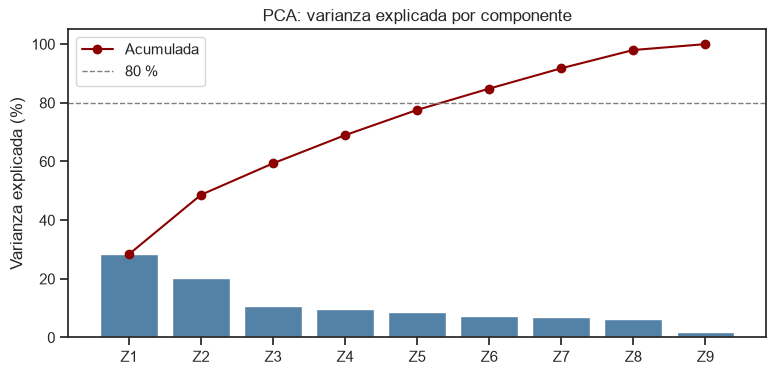

In [73]:
nombres_z = [f"Z{i + 1}" for i in range(len(atributos_dr))]

tabla_varianza = pd.DataFrame({
    "Componente": nombres_z,
    "Autovalor": pca.explained_variance_,
    "Porcentaje": 100 * pca.explained_variance_ratio_,
})
tabla_varianza["Acumulada"] = tabla_varianza["Porcentaje"].cumsum()

# Menor número de componentes que conserva al menos el 80 % de la varianza
k_80 = int(np.argmax(tabla_varianza["Acumulada"].values >= 80) + 1)
# Criterio complementario (Kaiser): autovalor > 1
k_kaiser = int((pca.explained_variance_ > 1).sum())

display(tabla_varianza.round(2))
print(f"Componentes para conservar >= 80 % de la varianza: {k_80} ({tabla_varianza['Acumulada'].iloc[k_80 - 1]:.1f} %)")
print(f"Componentes con autovalor > 1 (Kaiser): {k_kaiser} ({tabla_varianza['Acumulada'].iloc[k_kaiser - 1]:.1f} %)")

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=tabla_varianza, x="Componente", y="Porcentaje", color="steelblue", ax=ax)
ax.plot(tabla_varianza["Componente"], tabla_varianza["Acumulada"], color="darkred", marker="o", label="Acumulada")
ax.axhline(80, color="gray", linestyle="--", linewidth=1, label="80 %")
ax.set(title="PCA: varianza explicada por componente", xlabel="", ylabel="Varianza explicada (%)")
ax.legend()
plt.show()

**¿Cuántas componentes conservar?**

*   Se necesitan **6 componentes para conservar el 80 %** de la varianza (84.8 %): la dimensión pasa de 9 a 6.
*   La reducción es moderada (en el caso Bumpus, Z1 sola explicaba 66 %). Es lo esperable: 8 de los 9 atributos son
    binarios, y las variables 0/1 tienen correlaciones bajas entre sí, así que la varianza se reparte.
*   Solo Z1 y Z2 tienen autovalor mayor que 1 (criterio de Kaiser); desde Z3 cada componente aporta entre 6 % y 11 %,
    casi lo mismo que un atributo aislado.

**Decisión:** se interpretan Z1 y Z2 (48.6 % de la varianza) y se guardan las 6 componentes del 80 % para compararlas en el clustering (10.11).

#### Direcciones de proyección \(P\)

Cada valor es el peso (*loading*) de un atributo en la componente. A mayor valor absoluto, mayor contribución; los
signos opuestos indican un **contraste**. El signo global de una componente es arbitrario: lo que importa es qué
atributos van juntos y cuáles van en sentido opuesto.

,Z1,Z2,Z3
log_mat_total,0.39,0.27,0.17
urbano,0.42,0.49,-0.04
gestion_privada,0.30,0.50,-0.16
resp_convivencia,0.32,-0.31,-0.12
afiliado_siseve,0.33,-0.27,-0.28
conoce_protocolos,0.36,-0.32,-0.17
reporta_ugel,0.28,-0.35,-0.26
consulta_rnssc,0.34,-0.05,0.31
actividad_esi,0.20,-0.23,0.81


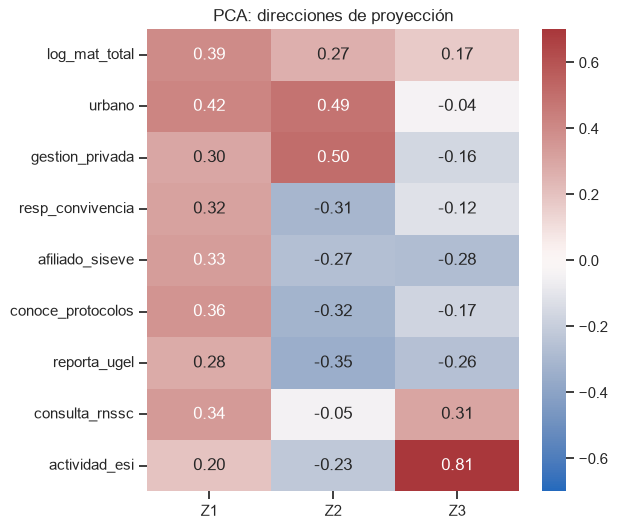

In [74]:
P_df = pd.DataFrame(P, index=atributos_dr, columns=nombres_z)
display(P_df[["Z1", "Z2", "Z3"]].round(2))

ax = sns.heatmap(P_df[["Z1", "Z2", "Z3"]], annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.7, vmax=0.7)
ax.set(title="PCA: direcciones de proyección", xlabel="", ylabel="")
ax.figure.set_size_inches(6, 6)
plt.show()

**Interpretación de Z1 y Z2.**

**Z1 (28.4 %): nivel general de capacidad y contexto.** Todos los pesos son positivos (como el “tamaño general del ave”
en Bumpus):

```
Z1 ≈ 0.42 urbano + 0.39 log_mat_total + 0.36 conoce_protocolos + 0.34 consulta_rnssc + 0.33 afiliado_siseve
   + 0.32 resp_convivencia + 0.30 privada + 0.28 reporta_ugel + 0.20 ESI
```

Un colegio con Z1 alto es grande, urbano y tiene todos los instrumentos; uno con Z1 bajo es pequeño, rural y le faltan
instrumentos. La tabla siguiente muestra qué cambia a lo largo de Z1.

**Z2 (20.3 %): contexto privado-urbano frente a instrumentos de convivencia.** Es un contraste:

*   Positivos: `gestion_privada` (0.50), `urbano` (0.49), `log_mat_total` (0.27).
*   Negativos: `reporta_ugel` (−0.35), `conoce_protocolos` (−0.32), `resp_convivencia` (−0.31), `afiliado_siseve`
    (−0.27), `actividad_esi` (−0.23).

Descontado Z1, Z2 separa a los colegios **privados urbanos**, que declaran menos instrumentos del sistema público (UGEL,
SíseVe, protocolos del MINEDU), de los **públicos rurales**, que suelen declararlos todos.

**Z3 (10.7 %)** es casi solo `actividad_esi` (0.81) y su autovalor es menor que 1: no resume varios atributos.

In [75]:
# Respaldo de la interpretación: % de colegios con cada atributo, por quintil de Z1
quintil_z1 = pd.qcut(pd.Series(Z[:, 0], index=datos_dr.index).rank(method="first"), 5,
                     labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
display(datos_dr[atributos_convivencia + ["urbano", "gestion_privada"]]
        .groupby(quintil_z1, observed=True).mean().mul(100).round(0).T
        .rename_axis("% de colegios con el atributo"))

,Q1 (bajo),Q2,Q3,Q4,Q5 (alto)
% de colegios con el atributo,,,,,
resp_convivencia,52.0,92.0,97.0,96.0,100.0
afiliado_siseve,41.0,84.0,94.0,94.0,99.0
conoce_protocolos,46.0,94.0,98.0,98.0,100.0
reporta_ugel,61.0,93.0,97.0,95.0,99.0
consulta_rnssc,7.0,16.0,49.0,65.0,83.0
actividad_esi,19.0,29.0,54.0,59.0,59.0
urbano,5.0,6.0,8.0,46.0,100.0
gestion_privada,5.0,6.0,6.0,24.0,64.0


*   **El extremo bajo de Z1 lo marcan los instrumentos:** en Q1 solo el 52 % tiene responsable de convivencia, el 46 %
    de directores conoce los protocolos y el 41 % está afiliado al SíseVe; desde Q2, más del 84 %.
*   **El extremo alto lo marca el contexto:** de Q4 a Q5 los colegios urbanos pasan de 46 % a 100 % y los privados de
    24 % a 64 %.
*   Z1 mezcla dos cosas: abajo mide la falta de instrumentos y arriba el contexto urbano y privado.

#### Representación PCA: Z1 y Z2

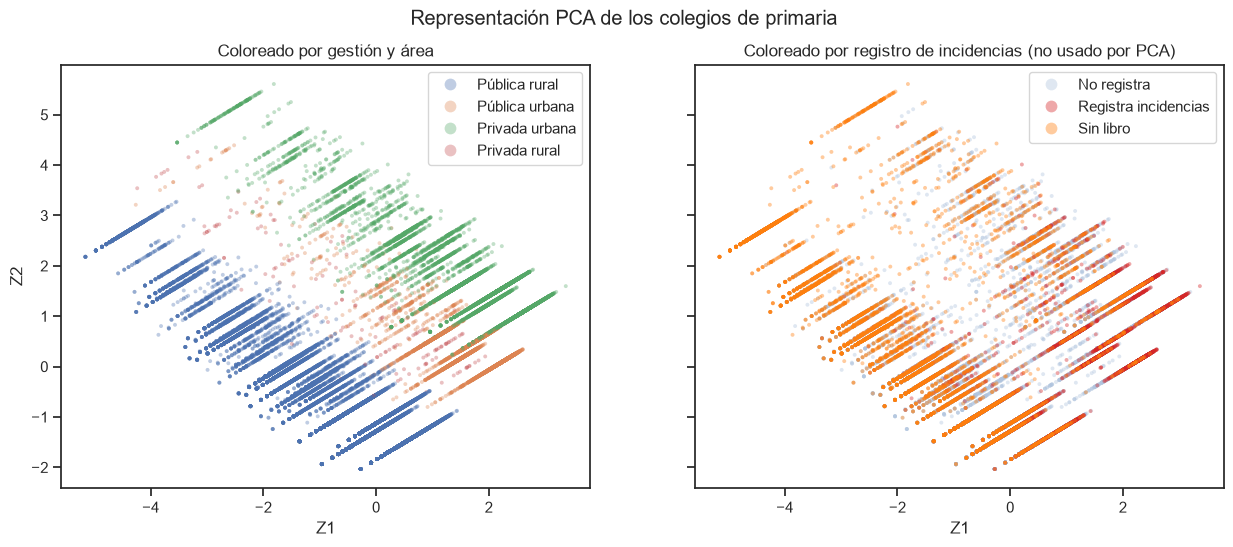

In [76]:
Z_df = pd.DataFrame(Z[:, :2], columns=["Z1", "Z2"], index=datos_dr.index).join(etiquetas_dr)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True, sharey=True)

sns.scatterplot(data=Z_df, x="Z1", y="Z2", hue="Contexto", hue_order=orden_contexto,
                s=8, alpha=0.35, linewidth=0, ax=axes[0])
axes[0].set_title("Coloreado por gestión y área")
axes[0].legend(title="", markerscale=3)

sns.scatterplot(data=Z_df[Z_df["Registro"] != "Sin dato"].sort_values("Registro"), x="Z1", y="Z2",
                hue="Registro", palette=colores_registro,
                s=8, alpha=0.4, linewidth=0, ax=axes[1])
axes[1].set_title("Coloreado por registro de incidencias (no usado por PCA)")
axes[1].legend(title="", markerscale=3)

fig.suptitle("Representación PCA de los colegios de primaria")
plt.show()

*   **Z2 separa la gestión y el área:** los públicos rurales (2 de cada 3 colegios) quedan abajo y los privados urbanos
    arriba.
*   **Las bandas diagonales no son grupos naturales:** aparecen porque casi todos los atributos son binarios. Cada
    banda reúne a colegios con el mismo número de instrumentos de convivencia; cada instrumento que **falta** desplaza
    al colegio un paso hacia la izquierda y hacia arriba, y dentro de cada banda la posición la da el tamaño.
*   Los colegios que registran y los que no **se superponen**, como sobrevivientes y no sobrevivientes en Bumpus: PCA
    no busca separar el registro (no lo usó). Los colegios **sin libro** (naranja) se concentran en Z1 bajo. Para ver
    proporciones se calcula, por quintil, el % que registra (entre colegios con libro) y el % sin libro:

In [77]:
def registro_por_quintil(rep, columna):
    """% que registra (entre colegios con libro y dato) y % sin libro, por quintil de una componente."""
    q = pd.qcut(rep[columna].rank(method="first"), 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
    con_libro = rep[rep["Registro"].isin(["Registra incidencias", "No registra"])]
    return pd.DataFrame({
        "% registra (con libro)": con_libro["Registro"].eq("Registra incidencias")
                                  .groupby(q, observed=True).mean() * 100,
        "% sin libro": rep["Registro"].eq("Sin libro").groupby(q, observed=True).mean() * 100,
    }).rename_axis(f"Quintil de {columna}")

for componente in ["Z1", "Z2"]:
    display(registro_por_quintil(Z_df, componente).round(1))

,% registra (con libro),% sin libro
Quintil de Z1,,
Q1 (bajo),5.2,48.2
Q2,5.8,15.2
Q3,10.0,9.5
Q4,17.3,7.1
Q5 (alto),26.8,4.0


,% registra (con libro),% sin libro
Quintil de Z2,,
Q1 (bajo),7.7,6.7
Q2,9.6,9.4
Q3,15.8,17.4
Q4,22.7,19.3
Q5 (alto),16.2,31.3


*   **El registro crece con Z1:** entre los colegios con libro, pasa de 5.2 % en el quintil más bajo a 26.8 % en el
    más alto.
*   **Pero el quintil más bajo esconde un grupo mayor: el 48 % de sus colegios no tiene libro**, así que ni siquiera
    puede registrar. Mirando solo el % que registra, este grupo quedaría fuera del análisis.
*   **Con Z2 la relación no es lineal:** el registro sube hasta el cuarto quintil (22.7 %) y baja en el quinto
    (16.2 %), donde además el 31 % no tiene libro: es el extremo privado-urbano, que declara menos instrumentos del
    sistema público.
*   Advertencia: Z1 mezcla capacidad y contexto, y PCA no permite separar ambos efectos. NMF (9.3) sí lo hace.

### <font color=skyblue> 9.3 NMF </font>

NMF aproxima la matriz como \(X \approx WH\) con \(W \ge 0\) y \(H \ge 0\):

*   \(H\) (k × p): cada fila es un **factor**, una combinación aditiva de atributos;
*   \(W\) (n × k): cuánto participa cada factor en cada colegio (la nueva representación).

**¿Por qué `MinMaxScaler` y no `StandardScaler`?** El z-score produce valores negativos y NMF exige datos no negativos.
`MinMaxScaler` lleva cada atributo a [0, 1]. Las 8 binarias no cambian (ya están en 0–1); solo se reescala
`log_mat_total`.

In [78]:
X_pos = MinMaxScaler().fit_transform(X_dr)
print("Mínimo de X_pos:", X_pos.min(), "| Máximo de X_pos:", X_pos.max())

nmf = NMF(
    n_components=2,   # número de factores
    init="random",    # inicializa W y H con valores aleatorios
    random_state=1,   # reproducibilidad
    max_iter=2000,
)
W = nmf.fit_transform(X_pos)   # representación de cada colegio
H = nmf.components_            # composición de los factores

print("Dimensión de X_pos:", X_pos.shape, "| W:", W.shape, "| H:", H.shape)
print(f"Error de reconstrucción: {nmf.reconstruction_err_:.1f} "
      f"(relativo a la norma de X: {nmf.reconstruction_err_ / np.linalg.norm(X_pos):.1%})")

Mínimo de X_pos: 0.0 | Máximo de X_pos: 1.0
Dimensión de X_pos: (37260, 9) | W: (37260, 2) | H: (2, 9)
Error de reconstrucción: 166.7 (relativo a la norma de X: 38.2%)


#### Matriz \(H\): composición de los factores

,NMF1,NMF2
log_mat_total,0.48,0.45
urbano,0.00,1.45
gestion_privada,0.00,1.08
resp_convivencia,1.15,0.25
afiliado_siseve,1.09,0.28
conoce_protocolos,1.15,0.29
reporta_ugel,1.18,0.23
consulta_rnssc,0.49,0.56
actividad_esi,0.67,0.00


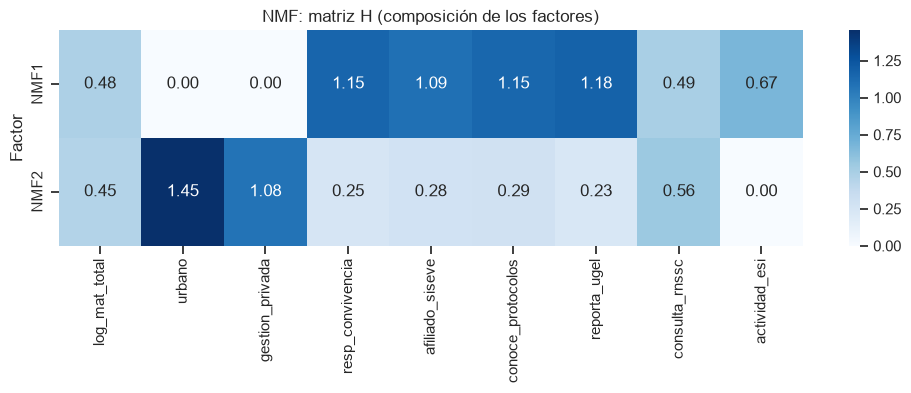

In [79]:
H_df = pd.DataFrame(H, index=["NMF1", "NMF2"], columns=atributos_dr)
display(H_df.T.round(2))

ax = sns.heatmap(H_df, annot=True, fmt=".2f", cmap="Blues")
ax.set(title="NMF: matriz H (composición de los factores)", xlabel="", ylabel="Factor")
ax.figure.set_size_inches(12, 2.8)
plt.show()

**Interpretación de los factores.**

**NMF1: instrumentos de gestión de la convivencia.** Pesos altos y casi iguales en `reporta_ugel` (1.18),
`resp_convivencia` (1.15), `conoce_protocolos` (1.15) y `afiliado_siseve` (1.09), seguidos de `actividad_esi` (0.67).
Peso **cero** en `urbano` y `gestion_privada`. Es el “paquete” de instrumentos que el MINEDU pide a cada colegio, sin
importar dónde esté.

**NMF2: contexto urbano y privado.** Dominado por `urbano` (1.45) y `gestion_privada` (1.08), con algo de
`consulta_rnssc` (0.56) y matrícula (0.45); peso bajo en los instrumentos y **cero** en ESI.

`log_mat_total` y `consulta_rnssc` se reparten entre ambos factores.

In [80]:
# ¿Los factores cambian con la semilla? Correlación entre H (random_state=1) y H con otras semillas
estabilidad = []
for semilla in range(5):
    H_s = NMF(n_components=2, init="random", random_state=semilla, max_iter=2000).fit(X_pos).components_
    corr = np.corrcoef(np.vstack([H, H_s]))[:2, 2:]      # factores base (filas) vs. factores de la semilla
    directo = corr[0, 0] + corr[1, 1] >= corr[0, 1] + corr[1, 0]
    estabilidad.append({"semilla": semilla, "orden": "igual" if directo else "invertido",
                        "corr_NMF1": corr[0, 0] if directo else corr[0, 1],
                        "corr_NMF2": corr[1, 1] if directo else corr[1, 0]})
display(pd.DataFrame(estabilidad).round(3))

,semilla,orden,corr_NMF1,corr_NMF2
0,0,igual,1.0,1.0
1,1,igual,1.0,1.0
2,2,igual,1.0,1.0
3,3,igual,1.0,1.0
4,4,invertido,1.0,1.0


Con 5 semillas distintas se obtienen los mismos dos factores (correlación 1.0 con la solución usada); en una de ellas
salen en orden inverso. La solución es estable.

#### Representación NMF: NMF1 y NMF2

,NMF1,NMF2
Contexto,,
Pública rural,0.73,0.03
Pública urbana,0.76,0.45
Privada urbana,0.58,0.75
Privada rural,0.53,0.33


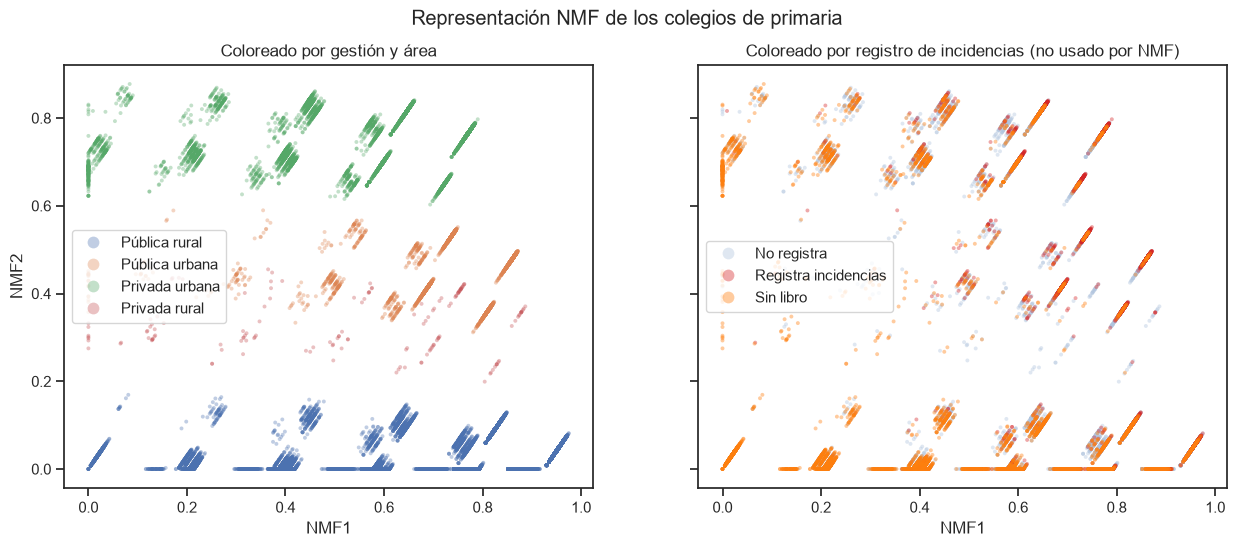

In [81]:
W_df = pd.DataFrame(W, columns=["NMF1", "NMF2"], index=datos_dr.index).join(etiquetas_dr)
display(W_df.groupby("Contexto")[["NMF1", "NMF2"]].mean().loc[orden_contexto].round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True, sharey=True)

sns.scatterplot(data=W_df, x="NMF1", y="NMF2", hue="Contexto", hue_order=orden_contexto,
                s=8, alpha=0.35, linewidth=0, ax=axes[0])
axes[0].set_title("Coloreado por gestión y área")
axes[0].legend(title="", markerscale=3)

sns.scatterplot(data=W_df[W_df["Registro"] != "Sin dato"].sort_values("Registro"), x="NMF1", y="NMF2",
                hue="Registro", palette=colores_registro,
                s=8, alpha=0.4, linewidth=0, ax=axes[1])
axes[1].set_title("Coloreado por registro de incidencias (no usado por NMF)")
axes[1].legend(title="", markerscale=3)

fig.suptitle("Representación NMF de los colegios de primaria")
plt.show()

*   **NMF2 ordena el contexto en franjas horizontales:** públicos rurales abajo (NMF2 ≈ 0), públicos urbanos al
    medio y privados urbanos arriba.
*   **NMF1 ordena, dentro de cada franja, los instrumentos de convivencia:** cada grupo de puntos corresponde a
    colegios con el mismo número de instrumentos; cuantos más tiene, más a la derecha.
*   En el panel derecho, los colegios que registran se concentran **a la derecha de cada franja** y los sin libro a la
    izquierda. Como las franjas
    mezclan contextos con niveles de registro muy distintos, se compara el % que registra y el % sin libro según el tercio de NMF1
    **dentro de cada contexto**:

In [82]:
w = W_df.copy()
w["Tercio de NMF1"] = w.groupby("Contexto")["NMF1"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 3, labels=["bajo", "medio", "alto"]))
con_libro_w = w[w["Registro"].isin(["Registra incidencias", "No registra"])]

pct_nmf = (con_libro_w.assign(registra=con_libro_w["Registro"].eq("Registra incidencias"))
           .pivot_table(index="Tercio de NMF1", columns="Contexto", values="registra",
                        aggfunc="mean", observed=True)[orden_contexto] * 100)
sin_libro_nmf = (w.assign(sin_libro=w["Registro"].eq("Sin libro"))
                 .pivot_table(index="Tercio de NMF1", columns="Contexto", values="sin_libro",
                              aggfunc="mean", observed=True)[orden_contexto] * 100)

print("% que registra incidencias (colegios con libro), por contexto y tercio de NMF1:")
display(pct_nmf.round(1))
print("% de colegios sin libro de incidencias, por contexto y tercio de NMF1:")
display(sin_libro_nmf.round(1))

% que registra incidencias (colegios con libro), por contexto y tercio de NMF1:


Contexto,Pública rural,Pública urbana,Privada urbana,Privada rural
Tercio de NMF1,,,,
bajo,6.5,29.4,9.4,10.0
medio,7.2,39.0,13.5,5.4
alto,11.1,40.7,21.8,17.0


% de colegios sin libro de incidencias, por contexto y tercio de NMF1:


Contexto,Pública rural,Pública urbana,Privada urbana,Privada rural
Tercio de NMF1,,,,
bajo,43.5,10.0,31.3,78.0
medio,10.0,3.2,7.8,24.5
alto,5.7,1.6,3.0,6.0


*   **Dentro de cada contexto, el registro sube con NMF1:** entre colegios con libro, en los públicos rurales pasa de
    6.5 % (tercio bajo) a 11.1 % (alto) y en los privados urbanos de 9.4 % a 21.8 %. Tener los instrumentos de
    convivencia se asocia con registrar.
*   **El contexto marca el nivel:** un público rural en el tercio alto de NMF1 (11.1 %) registra mucho menos que un
    público urbano en el tercio bajo (29.4 %).
*   **La brecha más grande está en el libro:** en el tercio bajo de NMF1, el 44 % de los públicos rurales y el 31 % de
    los privados urbanos no tiene libro; en el tercio alto, entre 2 % y 6 %. Los colegios con menos instrumentos son,
    sobre todo, colegios que no pueden registrar.
*   NMF hace visible esta separación porque pone capacidad y contexto en factores distintos; en PCA quedan mezclados
    en Z1.

#### ¿Cómo elegir el número de factores \(k\)?

Se usó \(k = 2\) para poder visualizar. Para revisar si es suficiente se prueba el error de reconstrucción con
distintos valores de \(k\) (criterio del codo).

,0,1,2,3,4,5,6,7
k,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0
Error_reconstruccion,200.1,166.7,138.8,124.6,91.5,73.5,56.0,40.9


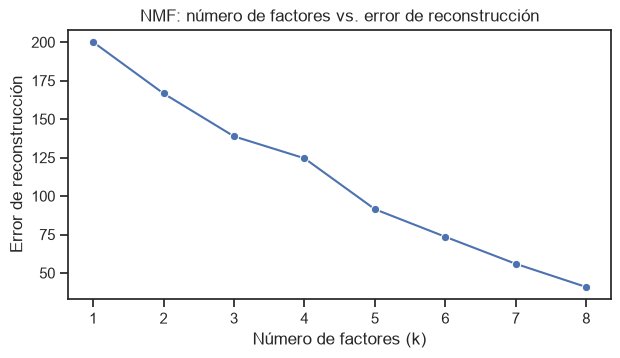

In [83]:
errores_k = pd.DataFrame([
    {"k": k, "Error_reconstruccion": NMF(n_components=k, init="random", random_state=1, max_iter=5000)
                                     .fit(X_pos).reconstruction_err_}
    for k in range(1, len(atributos_dr))
])
display(errores_k.round(1).T)

ax = sns.lineplot(data=errores_k, x="k", y="Error_reconstruccion", marker="o")
ax.set(title="NMF: número de factores vs. error de reconstrucción", xlabel="Número de factores (k)",
       ylabel="Error de reconstrucción")
ax.figure.set_size_inches(7, 3.5)
plt.show()

El error baja de forma casi constante y **no hay un codo claro**: cada factor nuevo mejora la reconstrucción en una
cantidad parecida, por la misma razón por la que PCA necesita 6 componentes (atributos binarios poco correlacionados).
Por eso \(k\) no se decide solo por el error: se mantiene \(k = 2\) porque los dos factores tienen una
interpretación clara y útil para el problema, aceptando una reconstrucción aproximada.

### <font color=skyblue> 9.4 Comparación PCA vs. NMF </font>

| | PCA | NMF (k = 2) |
|---|---|---|
| Preprocesamiento | `StandardScaler` | `MinMaxScaler` |
| Componente 1 | Z1: nivel general (instrumentos **+** tamaño **+** urbano), todos positivos | NMF1: solo instrumentos de convivencia (+ ESI) |
| Componente 2 | Z2: contraste privado-urbano **vs.** instrumentos (signos opuestos) | NMF2: solo contexto urbano-privado |
| Información conservada | 6 componentes para el 80 % (84.8 %) | Error relativo de 38.2 % con 2 factores; sin codo claro |
| Relación con el registro | Crece con Z1 (5.2 % → 26.8 %); el 48 % del quintil bajo no tiene libro | Crece con NMF1 dentro de cada contexto; el contexto (NMF2) marca el nivel |

**¿Resaltan los mismos atributos?** Sí, los mismos **dos bloques**: los instrumentos de convivencia (P123B, P124B,
P128B, P129B) y el contexto (`urbano`, `gestion_privada`, tamaño). La diferencia es cómo los combinan: PCA los
**mezcla** (Z1 suma ambos bloques y Z2 los opone con signos), mientras que NMF los **separa**, un bloque por factor y
con ceros exactos en el bloque contrario.

**¿Cuál es más fácil de interpretar?** **NMF.** Sus factores responden directamente a la pregunta del proyecto:
NMF1 mide *cuánta capacidad institucional de registro tiene el colegio* y NMF2 *en qué contexto está*. En PCA, Z2 es
un contraste con signos negativos, más difícil de explicar a un especialista de la UGEL.

**¿Cuál es más útil para el clustering?** Inicialmente, **PCA**:

*   conserva más información (6 componentes con el 85 % de la varianza, frente a 2 factores NMF sin un codo que
    justifique cuántos usar);
*   sus componentes son no correlacionadas y están en una escala comparable, lo que conviene a K-means, que usa
    distancias euclidianas;
*   W de NMF no es ortogonal y su escala depende de cómo se normaliza H.

En la práctica no hizo falta: en 10.11, K-means con las 6 componentes da casi los mismos grupos que con los 9
atributos (ARI 0.995), así que se usan los atributos, que se leen directo.

NMF se usará para **describir** los clusters resultantes (cuánto de cada factor tiene cada perfil), aprovechando que
es más fácil de comunicar.

### <font color=skyblue> 9.5 Guardado de las representaciones </font>

Se guardan, con la llave del colegio, la matriz transformada de PCA (\(Z\), 6 componentes del 80 %) y la matriz
reducida de NMF (\(W\), 2 factores). También las direcciones \(P\) y la matriz \(H\), para citarlas en el informe.

In [84]:
llave_dr = datos_dr[LLAVE + ["D_DPTO"]]

pca_Z = pd.concat([llave_dr, pd.DataFrame(Z[:, :k_80], columns=nombres_z[:k_80], index=datos_dr.index)], axis=1)
nmf_W = pd.concat([llave_dr, pd.DataFrame(W, columns=["NMF1", "NMF2"], index=datos_dr.index)], axis=1)

pca_Z.to_csv(SALIDAS / "pca_Z.csv", index=False)
nmf_W.to_csv(SALIDAS / "nmf_W.csv", index=False)
P_df.to_csv(SALIDAS / "pca_direcciones_P.csv")
H_df.to_csv(SALIDAS / "nmf_H.csv")

print("PCA (Z):", pca_Z.shape, "->", SALIDAS / "pca_Z.csv")
print("NMF (W):", nmf_W.shape, "->", SALIDAS / "nmf_W.csv")
display(pca_Z.head(3), nmf_W.head(3))

PCA (Z): (37260, 9) -> salidas\pca_Z.csv
NMF (W): (37260, 5) -> salidas\nmf_W.csv


,COD_MOD,ANEXO,D_DPTO,Z1,Z2,Z3,Z4,Z5,Z6
0,1720556,0,AREQUIPA,1.613279,2.417197,-0.102026,-1.459876,0.133561,0.660638
1,0313890,0,AREQUIPA,-0.060781,-1.327400,0.404770,0.549559,-0.897890,-0.597108
2,1495092,0,HUANUCO,2.049224,-0.034383,1.155705,0.128755,-0.217337,0.714336


,COD_MOD,ANEXO,D_DPTO,NMF1,NMF2
0,1720556,0,AREQUIPA,0.474907,0.832623
1,0313890,0,AREQUIPA,0.886147,0.000000
2,1495092,0,HUANUCO,0.856851,0.473169


### <font color=skyblue> 9.6 Lectura grupal (preliminar) </font>

1. Con 9 atributos de contexto y convivencia (37,260 colegios), PCA requiere 6 componentes para el 80 % de la varianza.
2. Z1 resume el nivel general: instrumentos de convivencia (responsable, SíseVe, protocolos) junto con tamaño y área urbana.
3. Z2 contrasta el contexto privado-urbano con los instrumentos de convivencia del sistema público.
4. NMF separa esos dos bloques en factores aditivos: instrumentos de convivencia (NMF1) y contexto (NMF2).
5. Sin usar el registro, el % que registra (con libro) pasa de 5.2 % a 26.8 % a lo largo de Z1; en el quintil bajo, el 48 % no tiene libro.
6. Dentro de cada contexto el registro se asocia a los instrumentos (NMF1), pero el contexto marca el nivel.
7. NMF es más fácil de interpretar; PCA conserva más información. K-means usa los 9 atributos para que los grupos se lean directo; en 10.11 se comprueba si usar las 6 componentes cambia los grupos.
8. Z (`pca_Z.csv`) y W (`nmf_W.csv`) quedan guardadas en `salidas/` para la siguiente etapa.

## <font color=yellow> 10. Clustering con K-means </font>

Se buscan **perfiles de colegios según su contexto y su capacidad institucional para gestionar la convivencia**.

**Técnica seleccionada: K-means. ¿Por qué?**

*   **Responde al objetivo.** La UGEL necesita saber qué tipos de colegio existen para priorizar. No hay una etiqueta de
    "colegio con baja capacidad" con la que entrenar un modelo, así que es un problema de agrupamiento.
*   **Se explica fácil.** Cada grupo se describe con el promedio de cada atributo.
*   **Funciona con todos los colegios.** Procesa los 37 mil colegios; el jerárquico necesita una muestra (10.10).
*   **Supuesto y limitación.** Busca grupos compactos con distancia euclidiana, y 8 de los 9 atributos son sí/no. Por eso
    se compara con DBSCAN y con el jerárquico.

**Qué no resuelve.** No separa un colegio sin violencia de uno sin registro, porque los datos no miden la violencia
ocurrida: sirve para priorizar dónde un cero es menos confiable. Tampoco responde por sí solo la relación con la
repetición y el retiro; eso se explora en la sección 6.

| Paso | Sección |
|---|---|
| Unidad de análisis y variables que entran (y no entran) a la distancia | 10.1 |
| Revisión de escalas y outliers | 10.2 |
| Escalamiento justificado | 10.3 |
| Inercia, codo, silueta, Davies-Bouldin y estabilidad | 10.4 – 10.6 |
| K-means con K = 3 y perfilamiento | 10.7 – 10.8 |
| Comparación con DBSCAN, jerárquico y otras representaciones | 10.9 – 10.12 |
| Resultados preliminares | 10.13 |

### <font color=skyblue> 10.1 Unidad de análisis y variables </font>

**Unidad de análisis:** cada fila es un colegio de primaria (`COD_MOD` + `ANEXO`), igual que en toda la matriz analítica.

**Variables que entran a la distancia:** los mismos **9 atributos** de la sección 9.1 (contexto + instrumentos de
convivencia), con las preguntas condicionadas ya corregidas en 1.7.

K-means se entrena sobre estas 9 variables estandarizadas y **no** sobre las componentes Z de PCA. Así los
centroides se interpretan directamente en términos de las variables, y no se pierde el 15 % de la varianza que dejan
fuera las 6 componentes.

**No entran a la distancia** (se usan solo para interpretar los grupos, igual que `categoria` en el laboratorio):

| Variable(s) | Motivo |
|---|---|
| `COD_MOD`, `ANEXO`, `D_DPTO` | Identificadores / etiqueta geográfica |
| `registra_incidencia`, `tasa_incidencias_100`, `tasa_casos_siseve_100` | Son el **resultado** que se quiere explicar |
| `tiene_libro` | Es el instrumento con el que se registra: incluirlo haría circular el análisis (9.1) |
| `tasa_repeticion`, `tasa_retiro` | Trayectoria escolar: también solo para interpretar |
| `mat_total`, `indice_convivencia`, `pct_mujeres`, otras columnas de gestión | Redundantes o fuera del perfil (ver la tabla de exclusiones de 9.1) |

In [85]:
# Matriz para K-means: mismos 9 atributos y mismos colegios de la sección 9
atributos_km = atributos_dr
datos_km = datos_dr.copy()                     # aquí se agregará la columna cluster_kmeans
X_km = datos_km[atributos_km].astype(float)   # unidades originales -> para perfilar

print(f"Colegios para clustering: {len(datos_km):,} de {len(matriz):,} ({len(datos_km) / len(matriz):.1%})")
print("Variables de clustering:", len(atributos_km))
print("Faltantes:", int(X_km.isna().sum().sum()))

Colegios para clustering: 37,260 de 37,354 (99.7%)
Variables de clustering: 9
Faltantes: 0


### <font color=skyblue> 10.2 Revisión de escalas y outliers antes de escalar </font>

,mean,std,min,50%,max
log_mat_total,3.533,1.477,0.0,3.466,7.712
urbano,0.330,0.470,0.0,0.000,1.000
gestion_privada,0.210,0.407,0.0,0.000,1.000
resp_convivencia,0.871,0.335,0.0,1.000,1.000
afiliado_siseve,0.823,0.382,0.0,1.000,1.000
conoce_protocolos,0.871,0.335,0.0,1.000,1.000
reporta_ugel,0.888,0.315,0.0,1.000,1.000
consulta_rnssc,0.442,0.497,0.0,0.000,1.000
actividad_esi,0.441,0.497,0.0,0.000,1.000


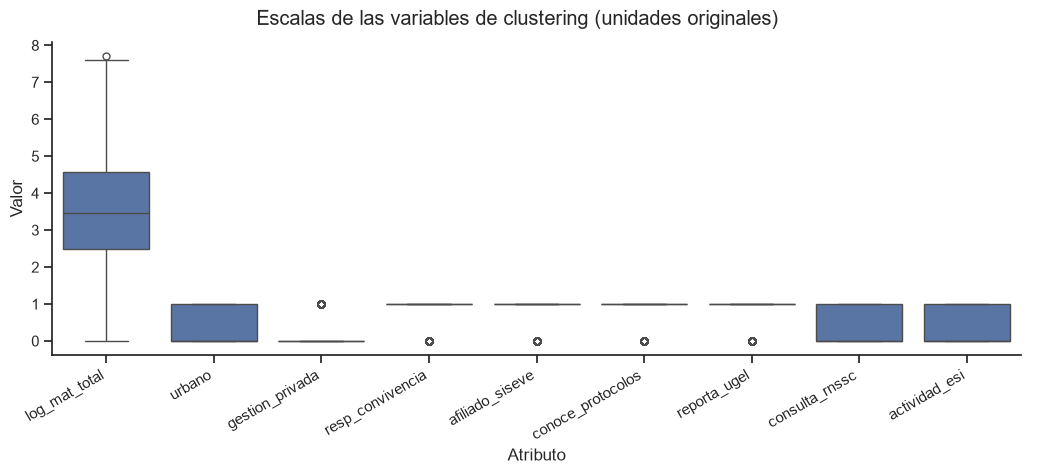

In [86]:
display(X_km.describe().T[["mean", "std", "min", "50%", "max"]].round(3))

X_km_long = X_km.melt(var_name="atributo", value_name="valor")
g = sns.catplot(data=X_km_long, x="atributo", y="valor", kind="box", height=4, aspect=2.6)
g.set_axis_labels("Atributo", "Valor")
g.set_xticklabels(rotation=30, ha="right")
g.fig.suptitle("Escalas de las variables de clustering (unidades originales)", y=1.03)
plt.show()

**Lectura.**

* `log_mat_total` va de 0 a ~7.7, mientras que las otras 8 variables están entre 0 y 1. Sin escalar, la matrícula
  dominaría la distancia euclidiana solo por su escala.
* **Outliers:** la matrícula original es muy asimétrica (colegios de más de 2,000 estudiantes). Ese problema ya se
  trató en la sección 7.3 con el **logaritmo**. Los colegios grandes son reales y **se conservan**.
* Las 8 binarias no pueden tener outliers: solo valen 0 o 1.

### <font color=skyblue> 10.3 Escalamiento </font>

Se usa **`StandardScaler`** (z-score):

* Pone `log_mat_total` en una escala comparable con las binarias.
* Es el mismo escalador usado para PCA (9.2), lo que permite comparar ambos resultados.
* `MinMaxScaler` se descartó en 7.4 porque un solo colegio muy grande comprime al resto.

> Los valores negativos son z-scores: indican "por debajo de la media". Son válidos para K-means.
>
> **Limitación:** en una binaria poco frecuente, el z-score amplifica la categoría rara (por ejemplo, el 13 % sin
> responsable de convivencia queda en z ≈ −2.6). No tener un instrumento pesa más en la distancia que tenerlo (8.4).

In [87]:
scaler_km = StandardScaler()
X_std_km = scaler_km.fit_transform(X_km)   # estandarizada -> para entrenar K-means

display(pd.DataFrame(X_std_km, columns=atributos_km).describe().T[["mean", "std", "min", "max"]].round(2))

,mean,std,min,max
log_mat_total,0.0,1.0,-2.39,2.83
urbano,-0.0,1.0,-0.70,1.42
gestion_privada,-0.0,1.0,-0.52,1.94
resp_convivencia,-0.0,1.0,-2.60,0.38
afiliado_siseve,-0.0,1.0,-2.16,0.46
conoce_protocolos,-0.0,1.0,-2.60,0.38
reporta_ugel,-0.0,1.0,-2.82,0.35
consulta_rnssc,0.0,1.0,-0.89,1.12
actividad_esi,-0.0,1.0,-0.89,1.13


### <font color=skyblue> 10.4 Inercia para K = 1 … 6 </font>

In [88]:
from sklearn.cluster import KMeans

resultados = []
for k in range(1, 7):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_std_km)
    resultados.append({"k": k, "inercia": km.inertia_})
resultados = pd.DataFrame(resultados)
resultados

,k,inercia
0,1,335340.000000
1,2,261769.726720
2,3,211762.152531
3,4,189733.912502
4,5,171916.558876
5,6,153071.358693


### <font color=skyblue> 10.5 Gráfico del codo </font>

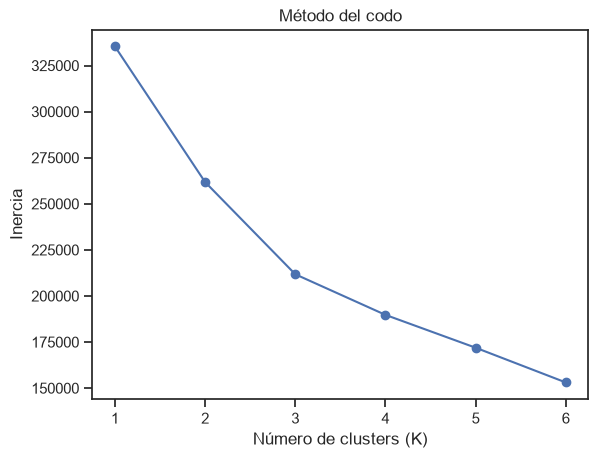

In [89]:
plt.plot(resultados["k"], resultados["inercia"], marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.show()

### <font color=skyblue> 10.6 Silueta y Davies-Bouldin para K = 2 … 6 </font>

El codo sugiere K, pero no dice si los grupos están bien separados. Se agregan dos métricas, como en el laboratorio de
clustering:

| Métrica | Qué mide | Mejor |
|---|---|---|
| **Silueta** (de −1 a 1) | Si cada colegio está más cerca de su grupo que del grupo vecino | Más alta |
| **Davies-Bouldin** | Si los grupos son compactos y están lejos unos de otros | Más bajo |

La silueta compara cada colegio con todos los demás; con 37 mil colegios se calcula sobre una **muestra de 10,000**.

,k,inercia,silueta,davies_bouldin
0,2,261769.727,0.263,1.658
1,3,211762.153,0.290,1.451
2,4,189733.913,0.239,1.480
3,5,171916.559,0.255,1.473
4,6,153071.359,0.285,1.459


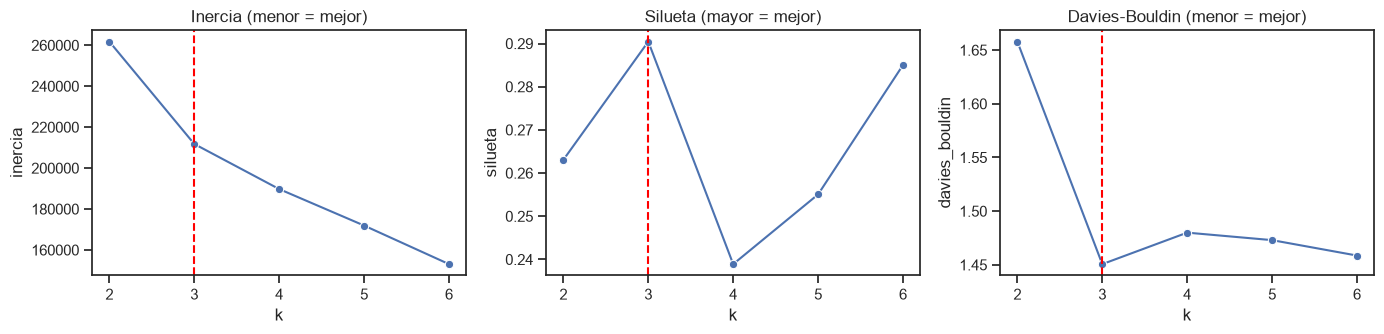

In [90]:
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score

validacion = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X_std_km)
    validacion.append({
        "k": k,
        "inercia": km.inertia_,
        "silueta": silhouette_score(X_std_km, km.labels_, sample_size=10_000, random_state=42),
        "davies_bouldin": davies_bouldin_score(X_std_km, km.labels_),
    })
validacion = pd.DataFrame(validacion)
display(validacion.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
titulos = ["Inercia (menor = mejor)", "Silueta (mayor = mejor)", "Davies-Bouldin (menor = mejor)"]
for ax, columna, titulo in zip(axes, ["inercia", "silueta", "davies_bouldin"], titulos):
    sns.lineplot(data=validacion, x="k", y=columna, marker="o", ax=ax)
    ax.axvline(3, color="red", ls="--")
    ax.set_title(titulo)
plt.tight_layout()
plt.savefig(SALIDAS / "fig_validacion_k.png", dpi=200, bbox_inches="tight")
plt.show()

**Lectura.** K = 3 tiene la silueta más alta (0.290) y el Davies-Bouldin más bajo (1.451), y coincide con el codo. K = 6 se
acerca mucho (0.285 y 1.459). Una silueta cercana a 0.3 indica una estructura débil: los grupos se tocan en los bordes y
hay colegios intermedios.

**¿Es estable?** Una diferencia pequeña de silueta puede deberse a la muestra. Se repite con otras 5 muestras y se vuelve
a correr K-means con otros 4 puntos de partida. El **ARI** compara dos agrupaciones: 1 = los mismos grupos; 0 = coinciden
como por azar.

In [91]:
estabilidad = []
for k in range(2, 7):
    etiquetas_k = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit_predict(X_std_km)
    siluetas = [silhouette_score(X_std_km, etiquetas_k, sample_size=10_000, random_state=r) for r in range(5)]
    parecidos = [adjusted_rand_score(etiquetas_k, KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=r).fit_predict(X_std_km))
                 for r in [1, 7, 21, 99]]
    estabilidad.append({"k": k, "silueta_min": min(siluetas), "silueta_max": max(siluetas),
                        "ARI_min": min(parecidos), "ARI_max": max(parecidos)})
estabilidad = pd.DataFrame(estabilidad)
estabilidad.round(3)

,k,silueta_min,silueta_max,ARI_min,ARI_max
0,2,0.261,0.267,1.000,1.000
1,3,0.288,0.295,1.000,1.000
2,4,0.238,0.245,0.946,1.000
3,5,0.254,0.262,0.401,0.779
4,6,0.283,0.292,0.447,0.982


**Lectura.** Por silueta, K = 3 y K = 6 **no se pueden separar**: sus rangos se traslapan (0.288–0.295 y 0.283–0.292). Lo que
sí los separa es la estabilidad: con K = 3 los grupos son idénticos en todas las corridas (ARI = 1.0), mientras que con
K = 6 cambian bastante (ARI de 0.45 a 0.98) y con K = 5 también (0.40 a 0.78). K = 2 es estable, pero con peores métricas.
Por eso se trabaja con **K = 3**: no porque sea la única opción posible, sino porque es la más estable entre las de mejor
métrica y la más simple de explicar a la UGEL.

### <font color=skyblue> 10.7 K-means con el K elegido y tamaño de los clusters </font>

In [92]:
k_elegido = 3

kmeans = KMeans(
    n_clusters=k_elegido,
    init="k-means++",
    n_init=10,
    random_state=42
)

datos_km["cluster_kmeans"] = kmeans.fit_predict(X_std_km)
matriz["cluster_kmeans"] = datos_km["cluster_kmeans"]

print("Inercia:", round(kmeans.inertia_, 2))

print("\nTamaño de los clusters:")
display(datos_km["cluster_kmeans"].value_counts().sort_index())

# Nombre de cada grupo según su perfil, no según el número que asigna K-means
perfil_clusters = datos_km.groupby("cluster_kmeans")[["resp_convivencia", "mat_total"]].mean()
c_pocos = perfil_clusters["resp_convivencia"].idxmin()              # menos responsables de convivencia
c_urbano = perfil_clusters.drop(c_pocos)["mat_total"].idxmax()     # de los otros dos, el más grande
nombres_cluster = {c: "Rural con instrumentos" for c in perfil_clusters.index}
nombres_cluster.update({c_pocos: "Pocos instrumentos", c_urbano: "Urbano grande"})
print("\nNombres:", nombres_cluster)

Inercia: 211762.15

Tamaño de los clusters:


cluster_kmeans
0     5075
1    20725
2    11460
Name: count, dtype: int64


Nombres: {0: 'Pocos instrumentos', 1: 'Rural con instrumentos', 2: 'Urbano grande'}


### <font color=skyblue> 10.8 Perfilamiento en unidades originales </font>

,log_mat_total,urbano,gestion_privada,resp_convivencia,afiliado_siseve,conoce_protocolos,reporta_ugel,consulta_rnssc,actividad_esi,n
cluster_kmeans,,,,,,,,,,
0,2.87,0.16,0.15,0.37,0.25,0.32,0.45,0.11,0.20,5075
1,2.94,0.00,0.00,0.95,0.90,0.95,0.96,0.41,0.48,20725
2,4.90,1.00,0.61,0.95,0.93,0.97,0.95,0.64,0.48,11460


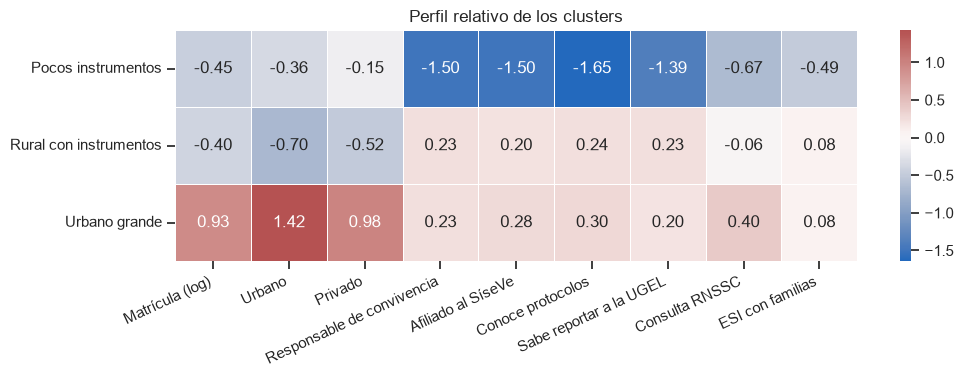

,mat_total,tiene_libro,registra_incidencia,tasa_incidencias_100,tasa_casos_siseve_100,tasa_repeticion,tasa_retiro
cluster_kmeans,,,,,,,
0,35.973,0.411,0.055,0.632,0.148,0.024,0.005
1,34.756,0.883,0.088,0.752,0.223,0.021,0.003
2,236.508,0.927,0.245,0.543,0.223,0.012,0.005


cluster_kmeans,0,1,2
D_DPTO,,,
AMAZONAS,0.24,0.72,0.05
ANCASH,0.06,0.74,0.20
APURIMAC,0.17,0.72,0.12
AREQUIPA,0.05,0.27,0.67
AYACUCHO,0.10,0.76,0.14
CAJAMARCA,0.15,0.78,0.07
CALLAO,0.12,0.00,0.88
CUSCO,0.12,0.67,0.21
HUANCAVELICA,0.08,0.88,0.04


In [93]:
perfil = datos_km.groupby("cluster_kmeans")[atributos_km].mean().round(2)

tamaños = datos_km.groupby("cluster_kmeans").size().rename("n")
perfil = perfil.join(tamaños)

display(perfil)

perfil_z = (perfil[atributos_km] - X_km.mean()) / X_km.std(ddof=0)

plt.figure(figsize=(11, 3))
sns.heatmap(perfil_z.rename(index=nombres_cluster, columns={"log_mat_total": "Matrícula (log)", **nombres_cortos}),
            annot=True, fmt=".2f", center=0, cmap="vlag", linewidths=0.5)
plt.title("Perfil relativo de los clusters")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=25, ha="right")
plt.savefig(SALIDAS / "fig_perfil_kmeans.png", dpi=200, bbox_inches="tight")
plt.show()

# tiene_libro no entró al modelo: aquí solo se usa para interpretar
variables_interpretar = ["mat_total", "tiene_libro", "registra_incidencia", "tasa_incidencias_100",
                         "tasa_casos_siseve_100", "tasa_repeticion", "tasa_retiro"]
display(datos_km.groupby("cluster_kmeans")[variables_interpretar].mean().round(3))

tabla_dpto = pd.crosstab(datos_km["D_DPTO"], datos_km["cluster_kmeans"], normalize="index").round(2)
display(tabla_dpto)

**¿Sobre qué colegios se calcula el registro?** `registra_incidencia` solo existe para los colegios con dato de
incidencias, así que casi todos los colegios sin libro quedan fuera de ese porcentaje. Además, los colegios grandes
registran más, así que los grupos se comparan **a igual tamaño**.

In [94]:
grupos = datos_km["cluster_kmeans"].map(nombres_cluster)

# Base de cada porcentaje
base_registro = datos_km.groupby(grupos)["registra_incidencia"].agg(con_dato="count", registran="sum", pct_registra="mean")
base_registro.insert(0, "colegios", grupos.value_counts())
base_registro["pct_registra"] = (base_registro["pct_registra"] * 100).round(1)
display(base_registro)

# % que registra a igual tamaño (y cuántos colegios con dato hay en cada celda)
tamano = pd.cut(datos_km["mat_total"], [0, 20, 50, 100, np.inf], include_lowest=True,
                labels=["Hasta 20", "21 a 50", "51 a 100", "Más de 100"])
display((datos_km.pivot_table(index=grupos, columns=tamano, values="registra_incidencia", aggfunc="mean", observed=True) * 100).round(1))
display(datos_km.pivot_table(index=grupos, columns=tamano, values="registra_incidencia", aggfunc="count", observed=True))

,colegios,con_dato,registran,pct_registra
cluster_kmeans,,,,
Pocos instrumentos,5075,2265,125.0,5.5
Rural con instrumentos,20725,18457,1615.0,8.8
Urbano grande,11460,10656,2614.0,24.5


mat_total,Hasta 20,21 a 50,51 a 100,Más de 100
cluster_kmeans,,,,
Pocos instrumentos,3.1,7.9,7.0,13.0
Rural con instrumentos,4.9,9.0,15.0,22.8
Urbano grande,3.4,7.1,11.4,33.3


mat_total,Hasta 20,21 a 50,51 a 100,Más de 100
cluster_kmeans,,,,
Pocos instrumentos,1239,559,313,154
Rural con instrumentos,9343,5321,2434,1359
Urbano grande,586,1193,2045,6832


**Lectura.** *Pocos instrumentos* registra menos que *Rural con instrumentos* en los cuatro tamaños (de 3.1 % frente a 4.9 % hasta
13.0 % frente a 22.8 %); son grupos con matrícula parecida, así que esta comparación es la más justa. En cambio, buena
parte del 24.5 % de *Urbano grande* se debe al tamaño: solo supera a *Rural con instrumentos* en los colegios de más de
100 estudiantes. Son asociaciones: con estos datos no se puede saber si *Pocos instrumentos* registra menos porque tiene
menos capacidad o porque hay menos violencia. Las celdas con menos colegios (154 en *Pocos instrumentos* con más de 100
estudiantes) deben leerse con cuidado.

### <font color=skyblue> 10.9 Comparación con DBSCAN </font>

Para saber si los tres perfiles dependen del algoritmo, se prueban otros dos métodos sobre **la misma matriz**
(`X_std_km`: los mismos colegios y los 9 atributos estandarizados). `cluster_kmeans` no entra a ninguno.

DBSCAN agrupa colegios que tienen muchos vecinos parecidos muy cerca. No hay que decirle cuántos grupos buscar, pero sí
**qué tan cerca** deben estar (`eps`) y **cuántos vecinos** se exigen (`min_samples`). Los colegios que no encajan en
ningún grupo quedan como **ruido (`-1`)**.

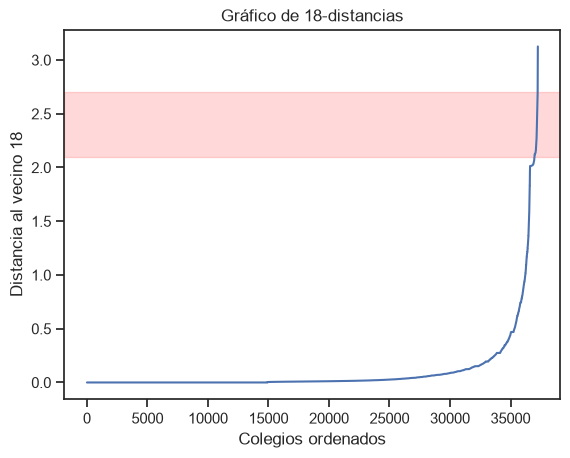

,min_samples,eps,grupos,% ruido,% en el grupo mayor
0,9,2.1,45,0.3,42.5
1,9,2.3,32,0.0,53.6
2,9,2.5,16,0.0,68.0
3,9,2.7,8,0.0,75.0
4,9,3.0,2,0.0,88.8
5,18,2.1,39,0.5,42.5
6,18,2.3,32,0.0,53.6
7,18,2.5,16,0.0,68.0
8,18,2.7,8,0.0,75.0
9,18,3.0,2,0.0,88.8


In [95]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# Regla práctica: min_samples = 2 x número de atributos
min_vecinos = 2 * X_std_km.shape[1]   # 18

# Distancia de cada colegio a su vecino número 18, ordenada de menor a mayor
distancias, _ = NearestNeighbors(n_neighbors=min_vecinos).fit(X_std_km).kneighbors(X_std_km)
k_distancias = np.sort(distancias[:, -1])

plt.plot(k_distancias)
plt.axhspan(2.1, 2.7, color="red", alpha=0.15)
plt.xlabel("Colegios ordenados")
plt.ylabel(f"Distancia al vecino {min_vecinos}")
plt.title(f"Gráfico de {min_vecinos}-distancias")
plt.show()

# ¿Qué pasa con distintos eps y min_samples?
filas_db = []
for vecinos_db in [9, 18, 36]:
    for eps in [2.1, 2.3, 2.5, 2.7, 3.0]:
        etiquetas_db = DBSCAN(eps=eps, min_samples=vecinos_db).fit_predict(X_std_km)
        asignados = etiquetas_db[etiquetas_db != -1]
        filas_db.append({"min_samples": vecinos_db, "eps": eps,
                         "grupos": len(set(asignados)),
                         "% ruido": round(np.mean(etiquetas_db == -1) * 100, 1),
                         "% en el grupo mayor": round(np.bincount(asignados).max() / len(etiquetas_db) * 100, 1)})
pd.DataFrame(filas_db)

**Lectura.** La curva queda en cero para unos 15 mil colegios: cada uno tiene al menos 18 colegios con **exactamente las
mismas respuestas**, porque 8 de los 9 atributos son sí/no. Por eso un cambio pequeño de `eps` cambia mucho el
resultado (de 39 a 2 grupos con `min_samples` = 18): con `eps` pequeño DBSCAN forma casi un grupo por combinación de
respuestas; al subirlo, esas "islas" se van uniendo. `min_samples` casi no influye: de 2.3 en adelante da lo mismo con
9, 18 o 36 vecinos. Se usa `eps = 2.7` porque deja una cantidad de grupos que se puede interpretar (8); con 3.0 casi todo
se junta en un grupo (89 %).

In [96]:
datos_km["cluster_dbscan"] = DBSCAN(eps=2.7, min_samples=min_vecinos).fit_predict(X_std_km)

# Los tres instrumentos que separan a los grupos; tiene_libro y registra_incidencia solo interpretan
columnas_dbscan = ["log_mat_total", "urbano", "resp_convivencia", "conoce_protocolos", "reporta_ugel",
                   "tiene_libro", "registra_incidencia"]
perfil_dbscan = datos_km.groupby("cluster_dbscan")[columnas_dbscan].mean().round(2)
perfil_dbscan["colegios"] = datos_km["cluster_dbscan"].value_counts()
perfil_dbscan["con_dato"] = datos_km.groupby("cluster_dbscan")["registra_incidencia"].count()
perfil_dbscan["registran"] = datos_km.groupby("cluster_dbscan")["registra_incidencia"].sum().astype(int)
perfil_dbscan

,log_mat_total,urbano,resp_convivencia,conoce_protocolos,reporta_ugel,tiene_libro,registra_incidencia,colegios,con_dato,registran
cluster_dbscan,,,,,,,,,,
0,3.69,0.36,1.0,1.0,1.0,0.91,0.15,27954,25709,3913
1,2.93,0.18,1.0,0.0,1.0,0.68,0.07,1794,1268,86
2,2.96,0.22,1.0,0.0,0.0,0.55,0.05,1075,608,29
3,3.49,0.36,1.0,1.0,0.0,0.81,0.14,1649,1355,192
4,3.01,0.26,0.0,1.0,1.0,0.63,0.06,2523,1641,92
5,2.96,0.21,0.0,0.0,0.0,0.15,0.03,1112,233,7
6,2.77,0.17,0.0,0.0,1.0,0.43,0.04,820,383,17
7,3.16,0.35,0.0,1.0,0.0,0.51,0.10,333,181,18


**Lectura.** El 75 % de los colegios (27,954) cae en un solo grupo (0): los que tienen responsable de convivencia,
conocen los protocolos y reportan a la UGEL. Los otros 7 grupos son las combinaciones de **cuál de esos tres
instrumentos les falta**; no queda ningún colegio como ruido. El **grupo 5**, sin ninguno de los tres (1,112 colegios),
es el que tiene menos libro: solo el 15 % lo tiene. Registra el 3 %, pero esa cifra sale de pocos colegios (7 de los 233
con dato). DBSCAN no separa por contexto (urbano, privado, tamaño), solo por instrumentos que faltan, porque tras el
z-score los "no" poco frecuentes pesan más (10.3).

### <font color=skyblue> 10.10 Comparación con el clustering jerárquico </font>

Une poco a poco a los colegios más parecidos hasta formar un árbol (**dendrograma**); cortar el árbol a cierta altura
da los grupos.

Necesita comparar todos los colegios contra todos (casi 700 millones de pares), lo que no cabe en memoria. Por eso el
árbol se construye con una **muestra de 10,000 colegios** y al final cada colegio se asigna al grupo más cercano.

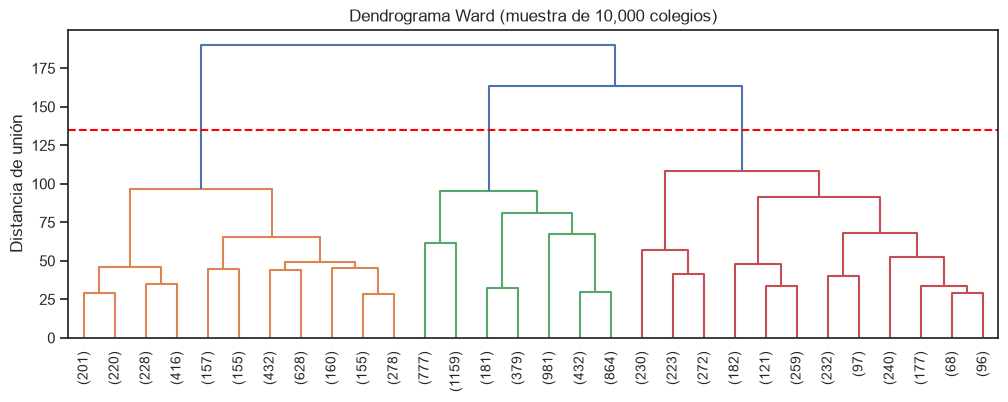

,enlace,tamaños,silueta,davies_bouldin,ARI con K-means
0,ward,"[3030, 4773, 2197]",0.270,1.656,0.759
1,complete,"[1227, 4731, 4042]",0.143,2.130,0.222
2,average,"[9144, 855, 1]",0.312,1.140,0.134
3,single,"[8864, 1135, 1]",0.305,1.271,0.165


In [97]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

muestra_hier = np.random.default_rng(42).choice(len(X_std_km), size=10_000, replace=False)
X_muestra = X_std_km[muestra_hier]

Z_ward = linkage(X_muestra, method="ward")

plt.figure(figsize=(12, 4))
dendrogram(Z_ward, truncate_mode="lastp", p=30, leaf_rotation=90)   # solo las últimas 30 ramas
plt.axhline(135, color="red", ls="--")
plt.title("Dendrograma Ward (muestra de 10,000 colegios)")
plt.ylabel("Distancia de unión")
plt.show()

# Mismo corte (3 grupos) con otras formas de medir la distancia entre grupos
km_muestra = datos_km["cluster_kmeans"].to_numpy()[muestra_hier]
filas_h = []
for metodo in ["ward", "complete", "average", "single"]:
    etiquetas_h = fcluster(linkage(X_muestra, method=metodo), t=3, criterion="maxclust")
    filas_h.append({"enlace": metodo,
                    "tamaños": np.bincount(etiquetas_h)[1:].tolist(),
                    "silueta": round(silhouette_score(X_muestra, etiquetas_h), 3),
                    "davies_bouldin": round(davies_bouldin_score(X_muestra, etiquetas_h), 3),
                    "ARI con K-means": round(adjusted_rand_score(km_muestra, etiquetas_h), 3)})
pd.DataFrame(filas_h)

**Lectura.** El salto vertical más grande está entre ~110 y ~165: cortar ahí (línea roja) deja **3 grupos**, igual que
el codo. Los números entre paréntesis son cuántos colegios hay en cada rama. La tabla muestra que **una métrica sola puede
engañar**: `average` tiene la mejor silueta (0.312) y `single` la segunda, pero las dos juntan casi todo en un grupo y dejan
otro de un solo colegio. `complete` da grupos de tamaño razonable, pero con la peor silueta (0.143). Se usa **Ward**: forma
grupos compactos, con tamaños útiles, y es el más parecido a K-means (ARI 0.759).

In [98]:
from sklearn.neighbors import NearestCentroid

etiquetas_muestra = fcluster(Z_ward, t=3, criterion="maxclust") - 1   # grupos 0, 1, 2

# Cada colegio se asigna al grupo cuyo promedio (centroide) tiene más cerca
asignador = NearestCentroid().fit(X_muestra, etiquetas_muestra)
datos_km["cluster_hier"] = asignador.predict(X_std_km)

# Filas: jerárquico | Columnas: K-means
tabla_hier = pd.crosstab(datos_km["cluster_hier"], datos_km["cluster_kmeans"].map(nombres_cluster))
display(tabla_hier)

# Asignar por centroides acerca el resultado a K-means, por eso también se mide el árbol sin esa asignación
tabla_arbol = pd.crosstab(etiquetas_muestra, km_muestra)
comparacion_hier = pd.DataFrame({
    "% en el grupo equivalente": [tabla_arbol.max(axis=1).sum() / len(km_muestra) * 100,
                                  tabla_hier.max(axis=1).sum() / len(datos_km) * 100],
    "ARI con K-means": [adjusted_rand_score(km_muestra, etiquetas_muestra),
                        adjusted_rand_score(datos_km["cluster_kmeans"], datos_km["cluster_hier"])],
}, index=["Árbol sin asignar (10,000 colegios)", "Asignando a todos por centroides"])
display(comparacion_hier.round(3))

cluster_kmeans,Pocos instrumentos,Rural con instrumentos,Urbano grande
cluster_hier,,,
0,43,4,11343
1,0,18831,4
2,5032,1890,113


,% en el grupo equivalente,ARI con K-means
"Árbol sin asignar (10,000 colegios)",90.020,0.759
Asignando a todos por centroides,94.487,0.856


**Lectura.** Por un camino distinto, el jerárquico llega a grupos parecidos a los de K-means (jerárquico 0 = *Urbano grande*,
1 = *Rural con instrumentos*, 2 = *Pocos instrumentos*). La medida más limpia es la del árbol sin asignar: **90.0 %** de
coincidencia y ARI 0.759. Al asignar a todos por centroides sube a 94.5 % y 0.856, pero esa cifra favorece el parecido
porque el paso se parece a K-means. La diferencia principal: pasa 1,890 colegios de *Rural con instrumentos* a *Pocos
instrumentos*, así que su grupo es más grande (7,035 frente a 5,075).

### <font color=skyblue> 10.11 ¿Cambia algo con otra representación? </font>

Se repite K-means con K = 3 sobre las 6 componentes del PCA (9.5) y sobre los 9 atributos sin escalar. La silueta y el
Davies-Bouldin se miden en el espacio de cada representación, así que el dato para comparar es el **ARI**: cuánto se
parecen los grupos a los de la representación elegida.

In [99]:
representaciones = {
    "9 atributos con z-score (elegida)": X_std_km,
    "6 componentes del PCA": pca_Z[nombres_z[:k_80]].to_numpy(),
    "9 atributos sin escalar": X_km.to_numpy(),
}
filas_rep = []
for nombre, X_rep in representaciones.items():
    etiquetas_rep = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42).fit_predict(X_rep)
    filas_rep.append({"representación": nombre,
                      "tamaños": np.bincount(etiquetas_rep).tolist(),
                      "silueta": round(silhouette_score(X_rep, etiquetas_rep, sample_size=10_000, random_state=42), 3),
                      "davies_bouldin": round(davies_bouldin_score(X_rep, etiquetas_rep), 3),
                      "ARI con la elegida": round(adjusted_rand_score(datos_km["cluster_kmeans"], etiquetas_rep), 3)})
    # Perfil de la última representación: ¿qué separa cuando no se escala?
    if nombre == "9 atributos sin escalar":
        display(X_km.groupby(etiquetas_rep)[["log_mat_total", "urbano", "resp_convivencia", "conoce_protocolos"]].mean().round(2))
pd.DataFrame(filas_rep)

,log_mat_total,urbano,resp_convivencia,conoce_protocolos
0,1.83,0.05,0.81,0.80
1,5.33,0.87,0.94,0.95
2,3.53,0.16,0.87,0.87


,representación,tamaños,silueta,davies_bouldin,ARI con la elegida
0,9 atributos con z-score (elegida),"[5075, 20725, 11460]",0.290,1.451,1.000
1,6 componentes del PCA,"[5088, 20753, 11419]",0.323,1.291,0.995
2,9 atributos sin escalar,"[11143, 10573, 15544]",0.257,1.336,0.263


**Lectura.** Usar las 6 componentes del PCA da casi los mismos grupos (ARI 0.995), así que **no hace falta para agrupar**; se
mantienen los 9 atributos porque los grupos se leen directo. El escalamiento sí importa: sin z-score los grupos cambian
por completo (ARI 0.263) y se separan sobre todo por tamaño (matrícula en log de 1.83, 3.53 y 5.33), con poca diferencia
en los instrumentos. Es lo que se anticipó en 8.4.

### <font color=skyblue> 10.12 Resumen de los tres métodos </font>

In [100]:
resumen = []
for metodo, columna in [("K-means (K = 3)", "cluster_kmeans"), ("DBSCAN (eps = 2.7)", "cluster_dbscan"),
                        ("Jerárquico Ward", "cluster_hier")]:
    etiquetas_m = datos_km[columna]
    resumen.append({
        "método": metodo,
        "grupos": etiquetas_m.nunique(),
        "% en el grupo más grande": round(etiquetas_m.value_counts(normalize=True).max() * 100, 1),
        "silueta": round(silhouette_score(X_std_km, etiquetas_m, sample_size=10_000, random_state=42), 3),
        "davies_bouldin": round(davies_bouldin_score(X_std_km, etiquetas_m), 3),
        "ARI con K-means": round(adjusted_rand_score(datos_km["cluster_kmeans"], etiquetas_m), 3),
    })
pd.DataFrame(resumen)

,método,grupos,% en el grupo más grande,silueta,davies_bouldin,ARI con K-means
0,K-means (K = 3),3,55.6,0.290,1.451,1.000
1,DBSCAN (eps = 2.7),8,75.0,0.291,1.476,0.262
2,Jerárquico Ward,3,50.6,0.281,1.553,0.856


**Lectura.** Los tres métodos tienen una silueta parecida (0.28 a 0.29): ninguno encuentra grupos mucho más separados. K-means
tiene el mejor Davies-Bouldin (1.451) con solo 3 grupos de tamaño útil. DBSCAN iguala la silueta, pero deja el 75 % de los
colegios en un grupo, sus 8 grupos solo dicen qué instrumento falta y se parecen poco a los de K-means (ARI 0.262). **Por
ahora se mantiene K-means con K = 3**: el jerárquico da perfiles parecidos y el grupo 5 de DBSCAN es un dato útil para
priorizar. La comparación final queda para el Hito 4.

### <font color=skyblue> 10.13 Resultados preliminares (máximo 6 líneas) </font>

K = 3 es la configuración más estable entre las de mejor métrica, aunque la separación entre grupos es débil (silueta 0.29).
**Urbano grande** (11,460 colegios): urbanos, más grandes, 61 % privados y con los instrumentos; registra el 24.5 % (2,614 de 10,656 con dato), en buena parte por su tamaño.
**Rural con instrumentos** (20,725): públicos, rurales y pequeños, con los instrumentos; registra el 8.8 % (1,615 de 18,457).
**Pocos instrumentos** (5,075): pequeños, sobre todo rurales; solo el 37 % tiene responsable de convivencia y el 59 % no tiene libro (dato que no entró al modelo). Registra el 5.5 % (125 de 2,265), menos que el grupo rural en todos los tamaños; los datos no permiten saber si es por menos capacidad o por menos violencia.
Ese grupo pesa más en la Amazonía (Loreto 43 %, Ucayali 32 %).
Los grupos sirven para priorizar, no para clasificar de forma definitiva: hay colegios intermedios.

## <font color=yellow> 11. Datos geoespaciales</font>

Tres mapas para ver **dónde** está el problema:

| Mapa | Qué muestra |
|---|---|
| 1 | Cuántos colegios de primaria hay por cada 1,000 km² en cada departamento (densidad) |
| 2 | Dónde están los colegios que **registran** incidencias de violencia |
| 3 | Dónde están los colegios que **no tienen libro** de registro de incidencias |

Se usan los límites de departamentos del IGN (2020) vistos en clase. El código busca la carpeta `peru_shapes/`
junto al notebook; si no existe pero está `peru_shapes.zip`, la descomprime.

In [101]:
import zipfile

import geopandas as gpd

CARPETA_SHAPES = Path("peru_shapes")
if not CARPETA_SHAPES.exists() and Path("peru_shapes.zip").exists():
    with zipfile.ZipFile("peru_shapes.zip") as archivo_zip:
        archivo_zip.extractall(CARPETA_SHAPES)

if not (CARPETA_SHAPES / "per_admbnda_adm1_ign_20200714.shp").exists():
    raise FileNotFoundError(
        "Falta la carpeta peru_shapes/ con los shapefiles del IGN. "
        "Súbanla junto al notebook (en Colab: panel Archivos) o coloquen peru_shapes.zip."
    )

# Límites de los 25 departamentos (ADM1)
regiones = gpd.read_file(CARPETA_SHAPES / "per_admbnda_adm1_ign_20200714.shp")
print("Departamentos:", len(regiones), "| CRS:", regiones.crs)

Departamentos: 25 | CRS: EPSG:4326


### <font color=skyblue> 11.1 Base geográfica: una fila por colegio </font>

Cada colegio tiene sus coordenadas (`NLONG_IE`, `NLAT_IE`) y su ubigeo (`CODGEO_padron`). Los dos primeros dígitos del
ubigeo, con el prefijo `"PE"`, son el código del departamento en el shapefile (`ADM1_PCODE`). Se unen por código y no
por nombre, porque los nombres no coinciden en mayúsculas y tildes.

Se marcan dos situaciones:

* **Registra:** anotó al menos una incidencia en el libro en 2024.
* **Sin libro:** el colegio no tiene libro de registro de incidencias (P125B = NO), así que no tiene dónde anotarlas.

Aquí *registra* incluye a 12 colegios que anotaron incidencias aunque declararon no tener libro (4,367 en
total). En la sección 6 esos 12 cuentan dentro del grupo sin libro, por eso allí registran 4,355.

In [102]:
geo = base_final[LLAVE + ["CODGEO_padron", "D_DPTO", "D_PROV", "NLAT_IE", "NLONG_IE"]].copy()
geo["ADM1_PCODE"] = "PE" + geo["CODGEO_padron"].str[:2]
geo["registra"] = matriz["registra_incidencia"] == 1
geo["sin_libro"] = base_final["P125B"] == "NO"

# De tabla a GeoDataFrame: X = longitud, Y = latitud, en grados (EPSG:4326)
colegios_gdf = gpd.GeoDataFrame(
    geo,
    geometry=gpd.points_from_xy(geo["NLONG_IE"], geo["NLAT_IE"]),
    crs="EPSG:4326",
)

print("Colegios en el mapa:", len(colegios_gdf))
print("Registran incidencias:", colegios_gdf["registra"].sum())
print("Sin libro de incidencias:", colegios_gdf["sin_libro"].sum())
print("Colegios sin departamento en el shapefile:", (~colegios_gdf["ADM1_PCODE"].isin(regiones["ADM1_PCODE"])).sum())

Colegios en el mapa: 37354
Registran incidencias: 4367
Sin libro de incidencias: 6269
Colegios sin departamento en el shapefile: 0


### <font color=skyblue> 11.2 Mapa 1 — Densidad de colegios por departamento </font>

**Densidad** = colegios de primaria por cada 1,000 km² de territorio. El área en km² solo se puede medir en metros, así
que antes se reproyecta el mapa con `to_crs` (UTM zona 18S, la del centro del Perú).

Callao (más de 3,500) y Lima (más de 150) están muy por encima del resto; con una escala continua todo el país se vería
del mismo color. Por eso la densidad se agrupa en cinco tramos.

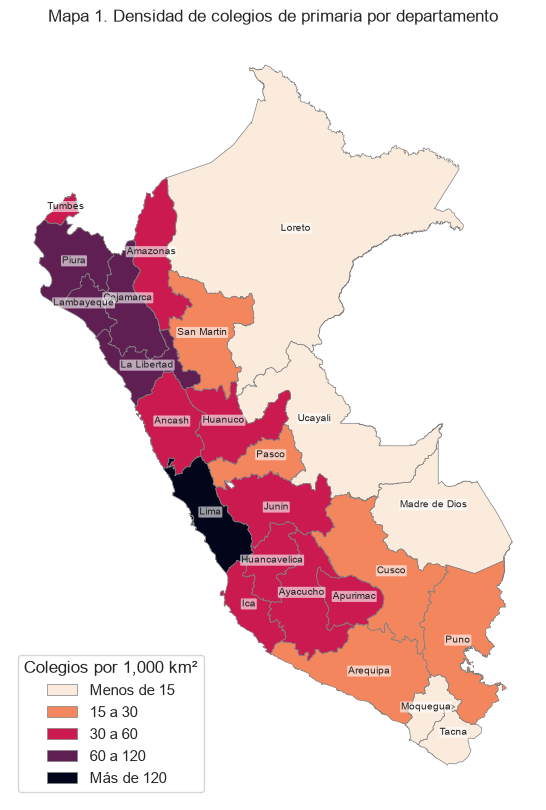

Los 6 departamentos con menor densidad:


,departamento,colegios,km²,"colegios por 1,000 km²",% sin libro
16,Madre de Dios,218,85065.5,2.6,25.7
15,Loreto,2376,375019.4,6.3,50.9
24,Ucayali,842,105158.7,8.0,37.5
17,Moquegua,197,15807.3,12.5,8.6
22,Tacna,239,16083.1,14.9,2.5
3,Arequipa,1311,63317.7,20.7,8.7


In [103]:
# Área de cada departamento en km²
regiones["area_km2"] = regiones.to_crs("EPSG:32718").area / 1_000_000

por_dpto = colegios_gdf.groupby("ADM1_PCODE").agg(
    colegios=("COD_MOD", "size"),
    pct_registra=("registra", lambda s: s.mean() * 100),
    pct_sin_libro=("sin_libro", lambda s: s.mean() * 100),
)

# El GeoDataFrame va a la izquierda para conservar la geometría
mapa_dpto = regiones.merge(por_dpto, on="ADM1_PCODE", how="left")
mapa_dpto["densidad"] = mapa_dpto["colegios"] / mapa_dpto["area_km2"] * 1000
mapa_dpto["tramo"] = pd.cut(mapa_dpto["densidad"], bins=[0, 15, 30, 60, 120, np.inf],
                            labels=["Menos de 15", "15 a 30", "30 a 60", "60 a 120", "Más de 120"])

ax = mapa_dpto.plot(column="tramo", categorical=True, cmap="rocket_r", edgecolor="gray", linewidth=0.5,
                    legend=True, legend_kwds={"title": "Colegios por 1,000 km²", "loc": "lower left"},
                    figsize=(8, 10))
for _, fila in mapa_dpto[mapa_dpto["ADM1_ES"] != "Callao"].iterrows():
    punto = fila["geometry"].representative_point()
    ax.annotate(fila["ADM1_ES"], xy=(punto.x, punto.y), ha="center", fontsize=7,
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.6))
ax.set_title("Mapa 1. Densidad de colegios de primaria por departamento")
ax.set_axis_off()
plt.show()

tabla_densidad = (mapa_dpto.sort_values("densidad")
                  [["ADM1_ES", "colegios", "area_km2", "densidad", "pct_sin_libro"]]
                  .rename(columns={"ADM1_ES": "departamento", "area_km2": "km²",
                                   "densidad": "colegios por 1,000 km²", "pct_sin_libro": "% sin libro"}))
print("Los 6 departamentos con menor densidad:")
display(tabla_densidad.head(6).round(1))

**Lectura**

*   Los tres departamentos con menos colegios por km² son amazónicos: **Madre de Dios (2.6), Loreto (6.3) y Ucayali
    (8.0)**. Allí los colegios están lejos unos de otros y lejos de su UGEL.
*   Esos mismos tres departamentos tienen muchos colegios **sin libro** de incidencias: Loreto 51 %, Ucayali 38 % y
    Madre de Dios 26 %.
*   La densidad sola no lo explica todo: Moquegua y Tacna también tienen pocos colegios por km², pero casi todos
    tienen libro (9 % y 3 % sin libro).

### <font color=skyblue> 11.3 Mapas 2 y 3 — ¿Dónde se registra y dónde no se puede registrar? </font>

Cada punto es un colegio. En gris están todos los colegios de primaria; en color, los del grupo que se quiere ver.

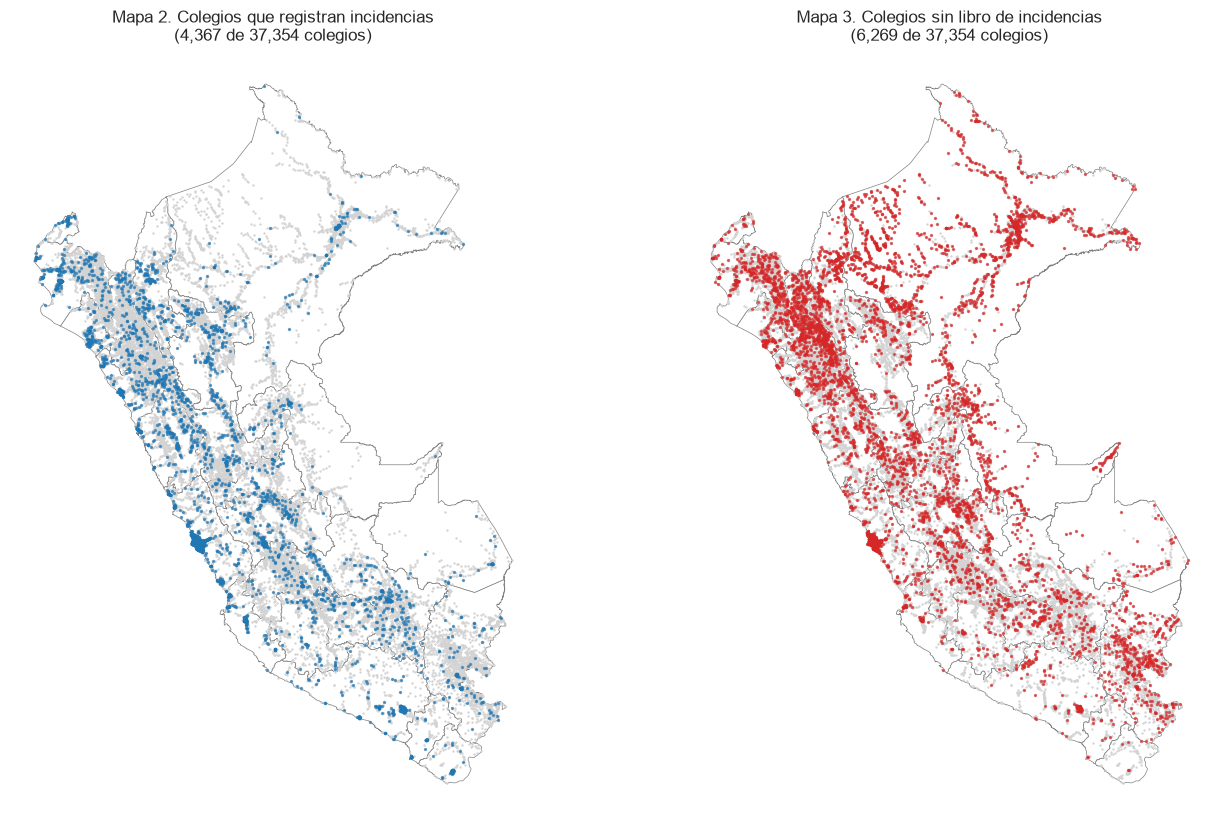

Departamentos con más y con menos colegios sin libro:


,colegios,% registra,% sin libro
ADM1_ES,,,
Loreto,2376,7.1,50.9
Ucayali,842,8.4,37.5
Madre de Dios,218,11.9,25.7
Amazonas,1294,12.0,22.7
Puno,1937,6.0,20.4
Tumbes,179,22.3,8.9
Huancavelica,1195,4.4,8.7
Arequipa,1311,17.5,8.7
Moquegua,197,15.2,8.6


In [104]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10))
mapas_puntos = [("registra", "tab:blue", "Mapa 2. Colegios que registran incidencias"),
                ("sin_libro", "tab:red", "Mapa 3. Colegios sin libro de incidencias")]

for ax, (columna, color, titulo) in zip(axes, mapas_puntos):
    regiones.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.5)
    colegios_gdf.plot(ax=ax, color="lightgray", markersize=0.5)       # todos los colegios
    seleccion = colegios_gdf[colegios_gdf[columna]]
    seleccion.plot(ax=ax, color=color, markersize=2, alpha=0.6)       # el grupo que se quiere ver
    ax.set_title(f"{titulo}\n({len(seleccion):,} de {len(colegios_gdf):,} colegios)", fontsize=12)
    ax.set_axis_off()
plt.show()

tabla_puntos = (mapa_dpto.set_index("ADM1_ES")[["colegios", "pct_registra", "pct_sin_libro"]]
                .rename(columns={"pct_registra": "% registra", "pct_sin_libro": "% sin libro"})
                .sort_values("% sin libro", ascending=False))
print("Departamentos con más y con menos colegios sin libro:")
display(pd.concat([tabla_puntos.head(5), tabla_puntos.tail(5)]).round(1))

**Lectura**

*   **Mapa 2 (azul):** los colegios que registran incidencias están sobre todo en la costa y en las ciudades. En la
    selva, fuera de ciudades como Iquitos, casi no hay puntos azules.
*   **Mapa 3 (rojo):** los colegios sin libro siguen los ríos de la Amazonía y se acumulan en la sierra norte
    (Cajamarca) y en Puno.
*   Donde el Mapa 3 se llena de rojo, el Mapa 2 se queda vacío. En Loreto solo el 7.1 % de los colegios registra y el
    50.9 % no tiene libro; en Tacna es al revés: 22.2 % registra y solo 2.5 % no tiene libro.
*   Hay una excepción: Huancavelica registra muy poco (4.4 %) aunque casi todos sus colegios tienen libro (8.7 % sin
    libro). Ahí el bajo registro no se explica por la falta del libro.

### <font color=skyblue> 11.4 Lectura preliminar </font>

1. La Amazonía tiene la menor densidad de colegios del país y la mayor proporción de colegios sin libro de incidencias.
2. Los colegios que registran y los que no tienen libro ocupan lugares distintos del mapa: costa y ciudades frente a
   ríos amazónicos, sierra norte y Puno.
3. En las zonas rojas del Mapa 3, un "cero" dice poco: muchos colegios no tienen libro donde anotar los casos, así que
   no se puede saber si hubo violencia.

## <font color=yellow> 12. Clustering espacial </font>

Como en el laboratorio, hay dos preguntas distintas y cada una pide un enfoque distinto:

| Enfoque | Pregunta | Qué entra al modelo |
|---|---|---|
| 12.1 Clustering por atributos y luego mapa | ¿Qué colegios se parecen? | Los 9 atributos de la sección 10, **sin** la ubicación |
| 12.2 Clustering espacial (DBSCAN) | ¿Dónde se juntan muchos colegios sin libro? | **Solo** la ubicación, en metros |
| 12.3 Mapa de calor | ¿Cuánta concentración hay en cada lugar? | **Solo** la ubicación |
| 12.4 Desafío del laboratorio | ¿Cambian los resultados con otros parámetros o algoritmos? | Lo mismo que 12.1 y 12.2, cambiando K, `min_samples` o el algoritmo |

In [105]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

### <font color=skyblue> 12.1 Clustering por atributos, visto en el mapa </font>

Los grupos de K-means de la sección 10 se formaron **sin usar la ubicación**. Aquí se pone la etiqueta de cada colegio
en el mapa para ver si los grupos forman regiones. Los números que asigna K-means (0, 1, 2) son arbitrarios, así que
cada grupo se identifica por el nombre que se le dio según su perfil (sección 10.7).

,resp_convivencia,mat_total
cluster_kmeans,,
Pocos instrumentos,0.37,35.97
Rural con instrumentos,0.95,34.76
Urbano grande,0.95,236.51


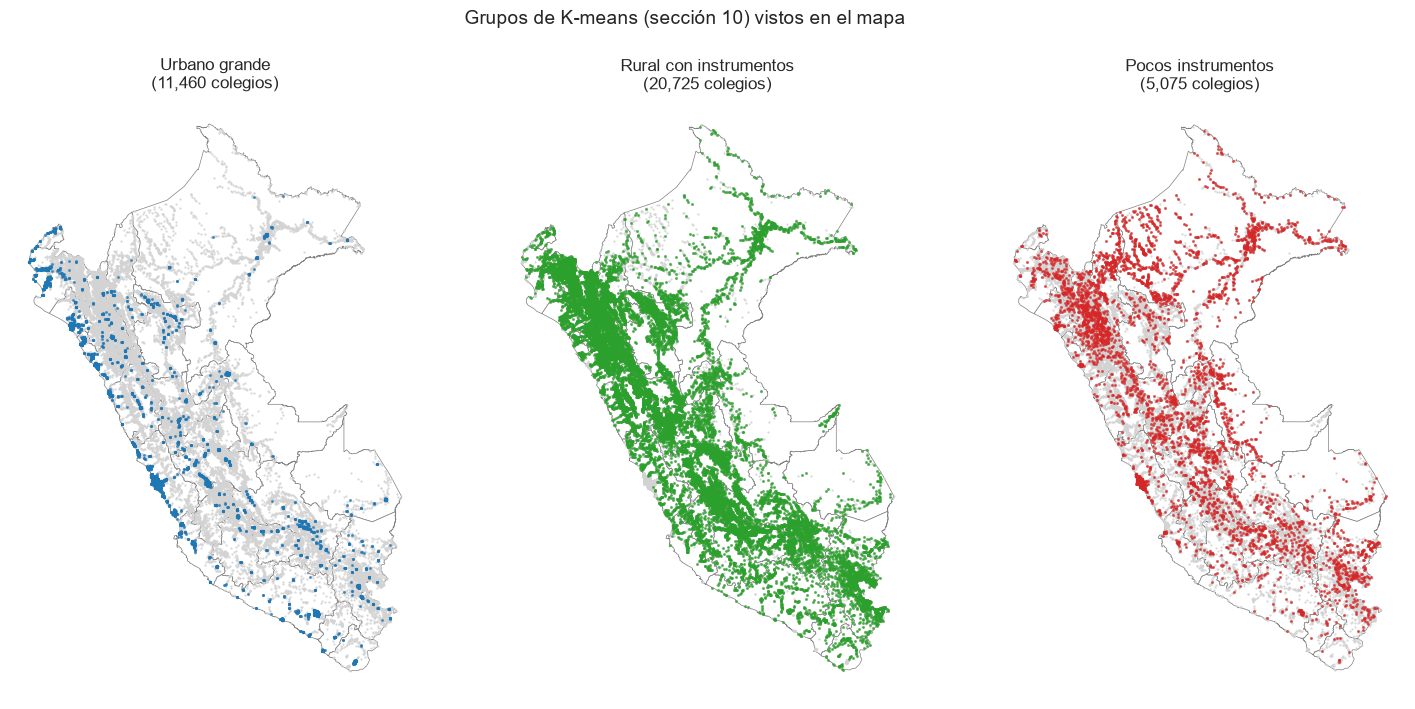

grupo_kmeans,Urbano grande,Rural con instrumentos,Pocos instrumentos
D_DPTO,,,
LORETO,10.0,47.0,43.0
UCAYALI,15.0,52.0,32.0
MADRE DE DIOS,26.0,45.0,29.0
PASCO,10.0,65.0,25.0
AMAZONAS,5.0,72.0,24.0
PUNO,18.0,64.0,18.0


In [106]:
# Los nombres de los grupos vienen de 10.7
colegios_gdf["grupo_kmeans"] = datos_km["cluster_kmeans"].map(nombres_cluster)
display(perfil_clusters.rename(index=nombres_cluster).round(2))

colores_grupo = {"Urbano grande": "tab:blue", "Rural con instrumentos": "tab:green", "Pocos instrumentos": "tab:red"}
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, (grupo, color) in zip(axes, colores_grupo.items()):
    regiones.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.5)
    colegios_gdf.plot(ax=ax, color="lightgray", markersize=0.3)
    capa = colegios_gdf[colegios_gdf["grupo_kmeans"] == grupo]
    capa.plot(ax=ax, color=color, markersize=1.5, alpha=0.6)
    ax.set_title(f"{grupo}\n({len(capa):,} colegios)")
    ax.set_axis_off()
fig.suptitle("Grupos de K-means (sección 10) vistos en el mapa", fontsize=14)
plt.savefig(SALIDAS / "fig_mapa_grupos.png", dpi=200, bbox_inches="tight")
plt.show()

# ¿En qué departamentos cae cada grupo? (% de los colegios del departamento)
pct_grupo = pd.crosstab(colegios_gdf["D_DPTO"], colegios_gdf["grupo_kmeans"], normalize="index") * 100
display(pct_grupo[list(colores_grupo)].sort_values("Pocos instrumentos", ascending=False).head(6).round(0))

**Lectura**

*   K-means no usó la ubicación, pero los grupos forman regiones: **Urbano grande** está en la costa y en las ciudades;
    **Rural con instrumentos** cubre casi toda la sierra; **Pocos instrumentos** sigue los ríos de la Amazonía y
    aparece también en Cajamarca y Puno.
*   El 43 % de los colegios de Loreto está en el grupo *Pocos instrumentos*; en Ucayali el 32 % y en Madre de Dios
    el 29 %. Les siguen Pasco (25 %) y Amazonas (24 %).
*   El patrón geográfico **sale de las características del colegio**, no de su ubicación: es la interpretación espacial
    posterior que propone el laboratorio.

### <font color=skyblue> 12.2 DBSCAN espacial: ¿dónde se juntan los colegios sin libro? </font>

Ahora se usa **solo la ubicación** de los colegios **sin libro** de incidencias. DBSCAN forma una zona cuando hay al
menos `min_samples` colegios a menos de `eps` de distancia; los colegios aislados quedan como **ruido** (`-1`).

Para el proyecto, una zona así es útil para planear: una sola capacitación o visita de la UGEL puede llegar a muchos
colegios sin libro a la vez.

**Primero, a metros.** `eps` es una distancia, así que las coordenadas deben estar en metros. El Perú abarca tres zonas
UTM (17S, 18S y 19S); se usa la del centro del país, **EPSG:32718** (UTM 18S). En los extremos del país el error de
distancia es menor al 1 %.

In [107]:
sin_libro_m = colegios_gdf[colegios_gdf["sin_libro"]].to_crs("EPSG:32718")
regiones_m = regiones.to_crs("EPSG:32718")

# DBSCAN recibe una matriz con dos columnas: X e Y (en metros)
coords_m = np.column_stack([sin_libro_m.geometry.x, sin_libro_m.geometry.y])
print("Colegios sin libro:", len(coords_m), "| CRS:", sin_libro_m.crs.name)

Colegios sin libro: 6269 | CRS: WGS 84 / UTM zone 18S


**¿Y si se usaran grados?** Con longitud y latitud en grados, `eps = 30_000` no serían 30 km sino 30,000 grados, más que la vuelta al mundo. Se comprueba con los mismos colegios:

In [108]:
# Mismo eps = 30_000, pero con longitud/latitud en grados (sin reproyectar)
coords_grados = colegios_gdf.loc[colegios_gdf["sin_libro"], ["NLONG_IE", "NLAT_IE"]].to_numpy()
etiquetas_grados = DBSCAN(eps=30_000, min_samples=30).fit_predict(coords_grados)
print("Zonas con coordenadas en grados:", len(set(etiquetas_grados)))
# 1 sola zona: en grados, 30,000 abarca todo el país. Por eso primero se reproyecta a metros.

Zonas con coordenadas en grados: 1


#### ¿Qué valor de `eps`? El gráfico de k-distancias

Se fija `min_samples = 30`: interesa encontrar zonas con **muchos** colegios sin libro, no pares de colegios vecinos.
Para cada colegio se mide la distancia a su 30.º vecino más cercano y se ordenan esas distancias. Donde la curva
**se dispara** están los colegios aislados: ese codo es el **máximo** razonable para `eps`.

Mediana: 30 km
Percentil 90: 60 km


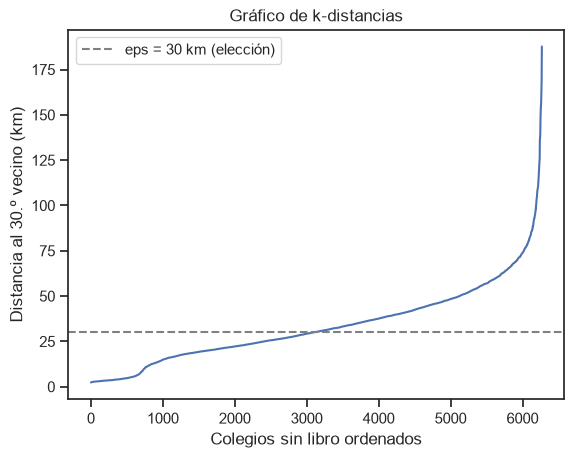

In [109]:
MIN_COLEGIOS = 30

vecinos = NearestNeighbors(n_neighbors=MIN_COLEGIOS).fit(coords_m)
distancias, _ = vecinos.kneighbors(coords_m)
k_dist_km = np.sort(distancias[:, -1]) / 1000      # en km, de menor a mayor

print("Mediana:", round(np.median(k_dist_km)), "km")
print("Percentil 90:", round(np.percentile(k_dist_km, 90)), "km")

ax = sns.lineplot(x=range(len(k_dist_km)), y=k_dist_km)
ax.axhline(30, color="gray", linestyle="--", label="eps = 30 km (elección)")
ax.set(title="Gráfico de k-distancias", xlabel="Colegios sin libro ordenados",
       ylabel="Distancia al 30.º vecino (km)")
ax.legend()
plt.show()

In [110]:
# ¿Qué pasa con distintos eps? (mismo min_samples = 30)
filas = []
for eps_km in [10, 20, 30, 40, 50]:
    etiquetas = DBSCAN(eps=eps_km * 1000, min_samples=MIN_COLEGIOS).fit_predict(coords_m)
    tamanos = pd.Series(etiquetas[etiquetas != -1]).value_counts()
    filas.append({"eps_km": eps_km,
                  "zonas": len(tamanos),
                  "ruido": (etiquetas == -1).sum(),
                  "% ruido": round((etiquetas == -1).mean() * 100),
                  "zona_mas_grande": tamanos.max()})
display(pd.DataFrame(filas))

,eps_km,zonas,ruido,% ruido,zona_mas_grande
0,10,6,5442,87,594
1,20,22,3749,60,611
2,30,22,2106,34,1689
3,40,15,983,16,3435
4,50,8,409,7,5159


**Lectura**

*   La mitad de los colegios sin libro tiene 30 vecinos sin libro a menos de 30 km. La curva se dispara después de
    unos 60–75 km: ahí están los colegios aislados.
*   Con `eps = 10 km` casi todo es ruido (87 %). Con 40 o 50 km aparecen zonas gigantes de miles de colegios que unen
    varios departamentos.
*   Se usa **`eps = 30 km`**: deja 22 zonas y un tercio de ruido, a una escala parecida a la de una provincia.

In [111]:
# eps = 30 km y min_samples = 30: al menos 30 colegios sin libro a menos de 30 km
sin_libro_m["zona"] = DBSCAN(eps=30_000, min_samples=MIN_COLEGIOS).fit_predict(coords_m)

ruido = sin_libro_m[sin_libro_m["zona"] == -1]
zonas = sin_libro_m[sin_libro_m["zona"] != -1]
print("Zonas encontradas:", zonas["zona"].nunique())
print(f"Colegios como ruido: {len(ruido)} ({len(ruido) / len(sin_libro_m):.0%})")

# Resumen de cada zona: cuántos colegios y dónde está
resumen_zonas = (zonas.groupby("zona")
                 .agg(colegios_sin_libro=("COD_MOD", "size"),
                      departamentos=("D_DPTO", lambda s: ", ".join(s.value_counts().index[:2].str.title())),
                      departamento=("D_DPTO", lambda s: s.mode()[0]),
                      provincia_principal=("D_PROV", lambda s: s.mode()[0]))
                 .sort_values("colegios_sin_libro", ascending=False))

# Para comparar: % de colegios sin libro en esa provincia (todos sus colegios)
pct_provincia = colegios_gdf.groupby(["D_DPTO", "D_PROV"])["sin_libro"].mean().mul(100).round(1)
resumen_zonas["% sin libro en la provincia"] = [pct_provincia[(d, p)] for d, p in
                                                zip(resumen_zonas["departamento"], resumen_zonas["provincia_principal"])]
display(resumen_zonas.drop(columns="departamento").head(10))

Zonas encontradas: 22
Colegios como ruido: 2106 (34%)


,colegios_sin_libro,departamentos,provincia_principal,% sin libro en la provincia
zona,,,,
0,1689,"Cajamarca, Piura",CELENDIN,39.7
4,619,"Lima, Callao",LIMA,12.2
7,244,Loreto,MAYNAS,42.1
2,230,Puno,AZANGARO,23.2
9,205,"Amazonas, Loreto",CONDORCANQUI,60.5
5,173,"Junin, Pasco",SATIPO,21.2
6,161,"Loreto, San Martin",ALTO AMAZONAS,40.9
1,114,"Ucayali, Huanuco",CORONEL PORTILLO,36.9
3,100,"Junin, Huancavelica",HUANCAYO,14.0


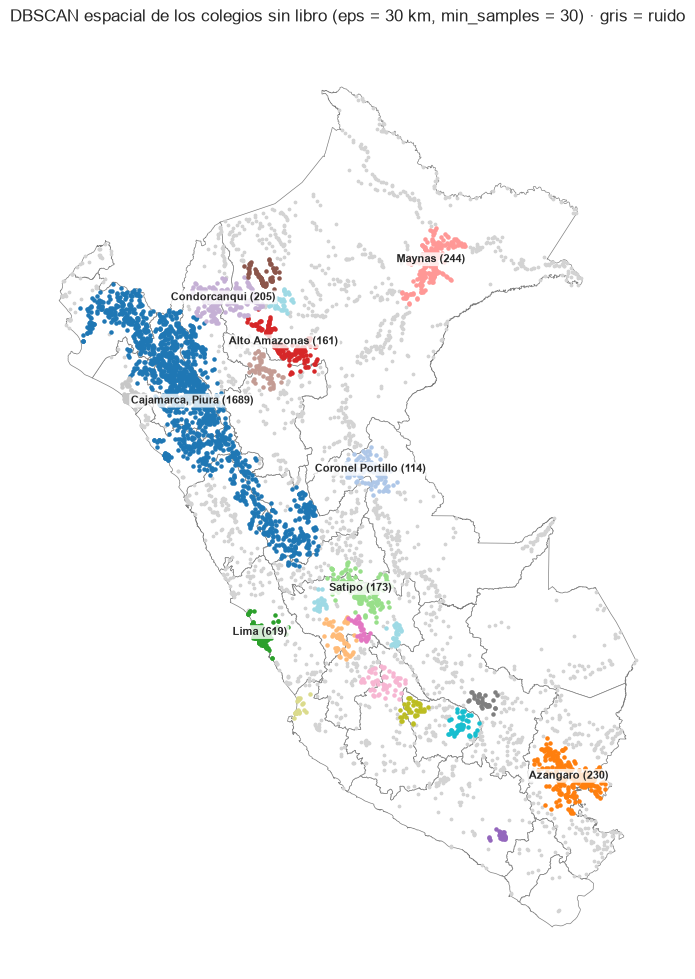

In [112]:
ax = regiones_m.plot(figsize=(10, 12), facecolor="white", edgecolor="gray", linewidth=0.5)
ruido.plot(ax=ax, color="lightgray", markersize=3)                      # gris = ruido
zonas.plot(ax=ax, column="zona", categorical=True, cmap="tab20", markersize=5)

# Nombre de las 8 zonas más grandes, en el centro de sus colegios
for zona, fila in resumen_zonas.head(8).iterrows():
    puntos = zonas[zonas["zona"] == zona].geometry
    etiqueta = fila["departamentos"] if zona == resumen_zonas.index[0] else fila["provincia_principal"].title()
    ax.annotate(f"{etiqueta} ({fila['colegios_sin_libro']})", xy=(puntos.x.mean(), puntos.y.mean()),
                ha="center", fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))

ax.set_title("DBSCAN espacial de los colegios sin libro (eps = 30 km, min_samples = 30) · gris = ruido")
ax.set_axis_off()
plt.show()

**¿Y la Amazonía?** En el Mapa 3 la Amazonía tenía las proporciones más altas de colegios sin libro. Se revisa qué
parte de esos colegios quedó como ruido:

In [113]:
amazonia = ["LORETO", "UCAYALI", "MADRE DE DIOS"]
es_amazonia = sin_libro_m["D_DPTO"].isin(amazonia)
print(f"Colegios sin libro que quedan como ruido -> Amazonía: {(sin_libro_m.loc[es_amazonia, 'zona'] == -1).mean():.0%}"
      f" | resto del país: {(sin_libro_m.loc[~es_amazonia, 'zona'] == -1).mean():.0%}")

print("\nProvincias con mayor % de colegios sin libro:")
display(pct_provincia.sort_values(ascending=False).head(5))

Colegios sin libro que quedan como ruido -> Amazonía: 56% | resto del país: 26%

Provincias con mayor % de colegios sin libro:


D_DPTO    D_PROV           
LORETO    DATEM DEL MARAÑON    85.3
UCAYALI   PURUS                81.6
LORETO    PUTUMAYO             68.6
AMAZONAS  CONDORCANQUI         60.5
LORETO    LORETO               50.0
Name: sin_libro, dtype: float64

**Lectura**

*   La zona más grande (1,689 colegios sin libro) es una franja continua en la sierra norte:
    va de Piura y Cajamarca (693 colegios) hasta La Libertad y Huánuco.
*   Lima es la segunda zona (619), pero porque tiene muchos colegios: en la provincia de Lima solo el 12 % no tiene
    libro. En Condorcanqui (Amazonas) la zona es más pequeña (205), pero el 61 % de sus colegios no tiene libro.
*   **Limitación importante:** en la Amazonía el 56 % de los colegios sin libro quedó como **ruido** (26 % en el resto
    del país). DBSCAN busca colegios *juntos*, y en la selva están dispersos a lo largo de los ríos. Justo en las
    provincias donde el problema es mayor en proporción (Datem del Marañón, Purús, Putumayo), DBSCAN casi no forma zonas.

### <font color=skyblue> 12.3 Mapa de calor vs. DBSCAN </font>

El mapa de calor colorea cada lugar según cuántos colegios sin libro hay alrededor. No forma grupos ni marca ruido.

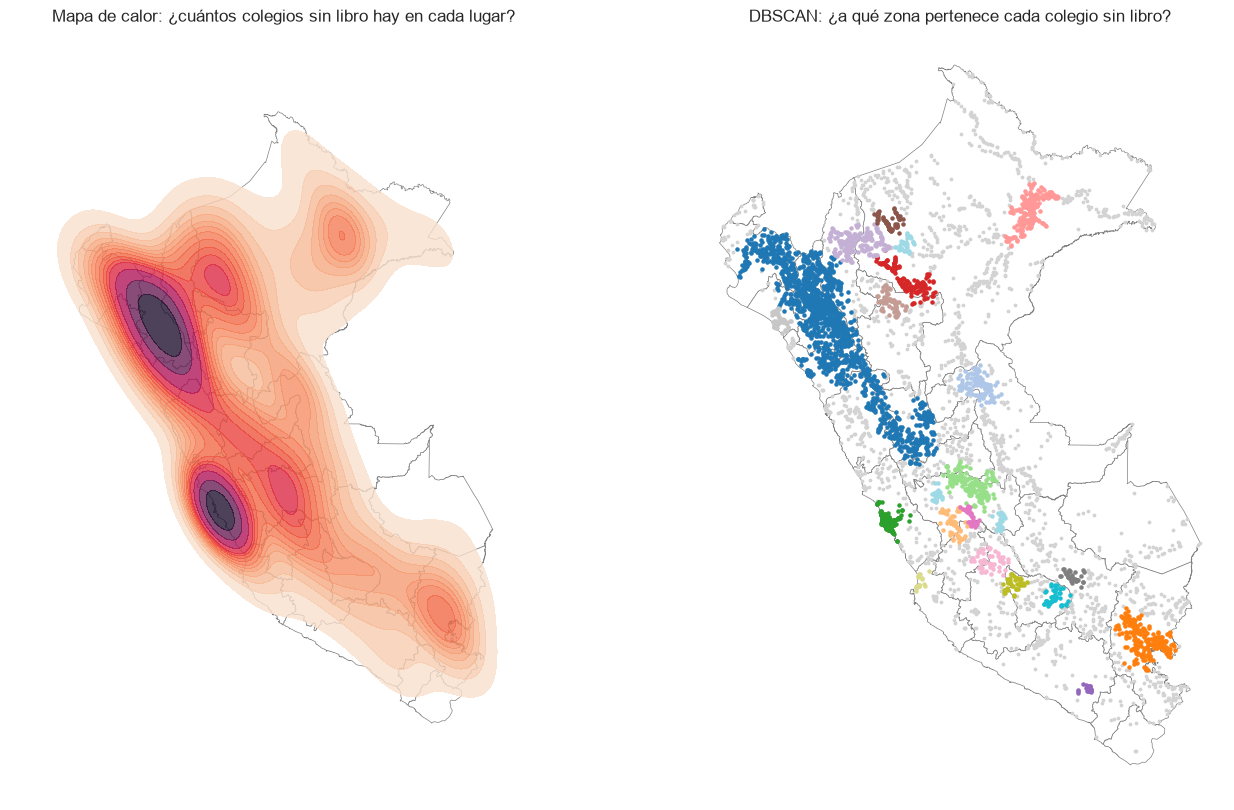

In [114]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 10))

# Izquierda: mapa de calor
regiones_m.plot(ax=ax1, facecolor="white", edgecolor="gray", linewidth=0.5)
sns.kdeplot(x=sin_libro_m.geometry.x, y=sin_libro_m.geometry.y, fill=True, cmap="rocket_r",
            levels=15, thresh=0.05, alpha=0.8, ax=ax1)
ax1.set_title("Mapa de calor: ¿cuántos colegios sin libro hay en cada lugar?")
ax1.set_axis_off()

# Derecha: DBSCAN
regiones_m.plot(ax=ax2, facecolor="white", edgecolor="gray", linewidth=0.5)
ruido.plot(ax=ax2, color="lightgray", markersize=3)
zonas.plot(ax=ax2, column="zona", categorical=True, cmap="tab20", markersize=5)
ax2.set_title("DBSCAN: ¿a qué zona pertenece cada colegio sin libro?")
ax2.set_axis_off()

plt.show()

**Lectura**

*   Los dos mapas marcan los mismos focos: la sierra norte y Lima, y con menos intensidad Iquitos, la selva central y
    Puno.
*   El mapa de calor es más fácil de leer para cualquier público, pero **pinta también el mar y zonas sin colegios**, y
    no dice a qué zona pertenece cada colegio.
*   DBSCAN da una etiqueta por colegio (zona o ruido) que se puede usar después, por ejemplo para listar los colegios
    de cada zona.
*   Ninguno de los dos mide proporciones: muestran dónde hay **muchos** colegios sin libro, que no es lo mismo que
    dónde es **más común** no tenerlo (para eso está el Mapa 3 y su tabla).

**El mapa de calor también depende de un parámetro de escala.** El ancho de banda (`bw_adjust`) cumple un papel parecido al `eps` de DBSCAN:

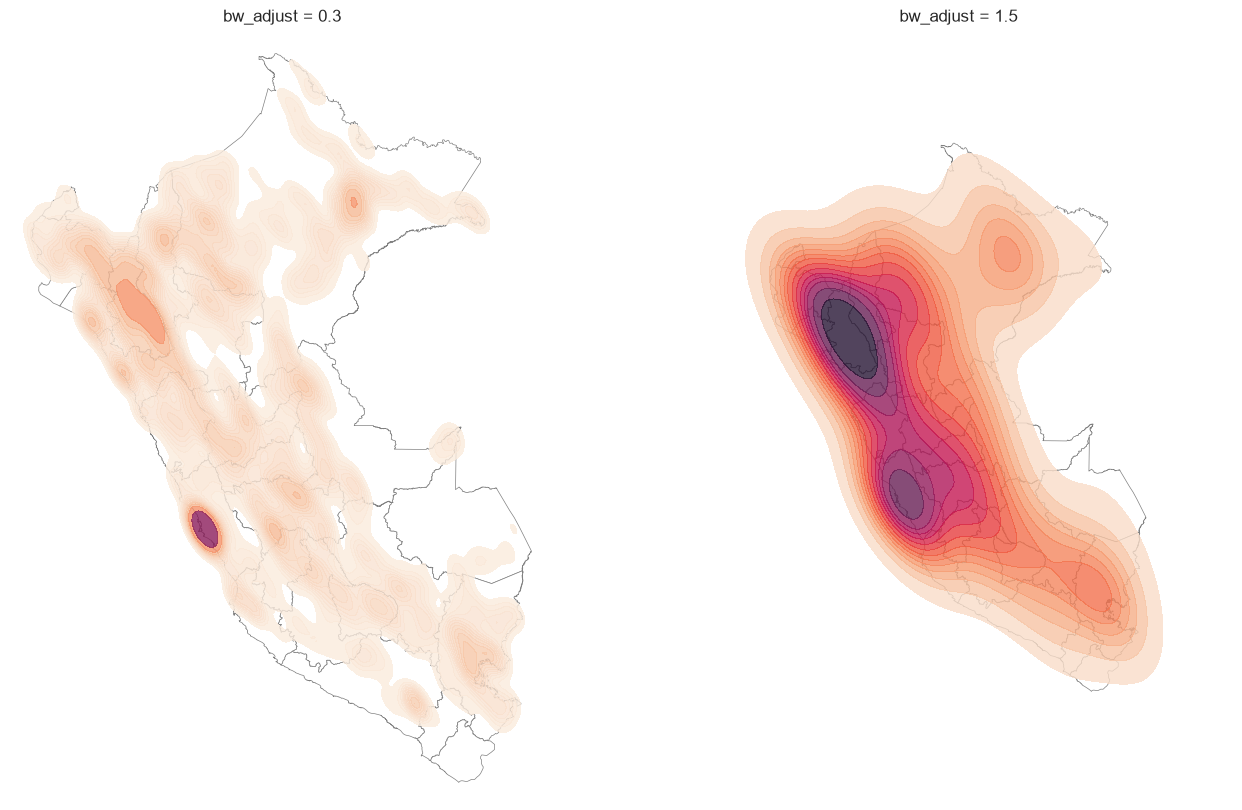

In [115]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10))
for ax, bw in zip(axes, [0.3, 1.5]):
    regiones_m.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.5)
    sns.kdeplot(x=sin_libro_m.geometry.x, y=sin_libro_m.geometry.y, fill=True, cmap="rocket_r",
                levels=15, thresh=0.05, alpha=0.8, bw_adjust=bw, ax=ax)
    ax.set_title(f"bw_adjust = {bw}")
    ax.set_axis_off()
plt.show()

**Lectura.** Con `bw_adjust = 0.3` el mapa marca muchos focos pequeños y el más fuerte es Lima, donde hay muchos
colegios juntos. Con `1.5` quedan dos manchas grandes (sierra norte y centro) que se extienden al mar y fuera del país.
Igual que `eps` en DBSCAN, el patrón depende de la escala elegida; para comunicar se usa el valor por defecto (12.3).

### <font color=skyblue> 12.4 Desafío del laboratorio S12: ¿cambian los resultados con otros parámetros? </font>

El laboratorio de clustering espacial cierra con un desafío de tres partes. Así se aplica a nuestros datos:

| Parte del desafío | Qué se hace con nuestros datos | Dónde |
|---|---|---|
| A. Clustering por atributos con otro número de grupos | K-means con K = 2 y K = 4 (el elegido es K = 3): ¿qué grupos se juntan o se parten? ¿Siguen formando regiones en el mapa? | A |
| B. DBSCAN espacial con otro `min_samples` | `eps = 30 km` fijo y `min_samples` = 15 y 60: la mitad y el doble de 30, como 5 y 20 frente a 10 en el laboratorio | B |
| B (adicional). Comparar algoritmos con la ubicación | K-means y jerárquico sobre las mismas coordenadas que DBSCAN, con 22 grupos (los de DBSCAN) y con 4 | B (adicional) |
| C. ¿Qué enfoque usaría el proyecto? | Tabla de decisión | 12.5 |

#### A. Clustering por atributos con K = 2 y K = 4

En el laboratorio se pasa de 4 a 3 grupos para ver cuáles se fusionan. Nuestro K elegido es 3, así que se prueba un
grupo menos (K = 2) y uno más (K = 4). Es el mismo K-means de 10.7, con los mismos 9 atributos estandarizados: solo
cambia K. La tabla cruza los grupos nuevos (filas) con los tres de 10.7 (columnas) y agrega el perfil promedio de cada
grupo nuevo (`tiene_libro` no entró al modelo: solo ayuda a interpretar).

In [116]:
grupo_k3 = datos_km["cluster_kmeans"].map(nombres_cluster)     # los 3 grupos de 10.7
columnas_perfil = ["mat_total", "urbano", "resp_convivencia", "conoce_protocolos", "actividad_esi", "tiene_libro"]

for k in [2, 4]:
    datos_km[f"kmeans_k{k}"] = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit_predict(X_std_km)
    # Filas: grupos con el nuevo K | Columnas: grupos con K = 3 (colegios) | Derecha: perfil promedio
    tabla_k = pd.crosstab(datos_km[f"kmeans_k{k}"], grupo_k3)
    tabla_k = tabla_k.join(datos_km.groupby(f"kmeans_k{k}")[columnas_perfil].mean().round(2))
    print(f"K = {k}: ¿de qué grupos de K = 3 viene cada grupo nuevo?")
    display(tabla_k)

K = 2: ¿de qué grupos de K = 3 viene cada grupo nuevo?


,Pocos instrumentos,Rural con instrumentos,Urbano grande,mat_total,urbano,resp_convivencia,conoce_protocolos,actividad_esi,tiene_libro
kmeans_k2,,,,,,,,,
0,4289,20703,5,33.32,0.0,0.85,0.84,0.43,0.8
1,786,22,11455,226.72,1.0,0.91,0.93,0.46,0.9


K = 4: ¿de qué grupos de K = 3 viene cada grupo nuevo?


,Pocos instrumentos,Rural con instrumentos,Urbano grande,mat_total,urbano,resp_convivencia,conoce_protocolos,actividad_esi,tiene_libro
kmeans_k4,,,,,,,,,
0,0,10807,61,29.57,0.01,0.93,0.93,0.00,0.85
1,4965,0,1,36.07,0.17,0.37,0.30,0.19,0.41
2,102,9918,39,40.26,0.01,0.96,0.97,1.00,0.92
3,8,0,11359,238.22,1.00,0.95,0.97,0.48,0.93


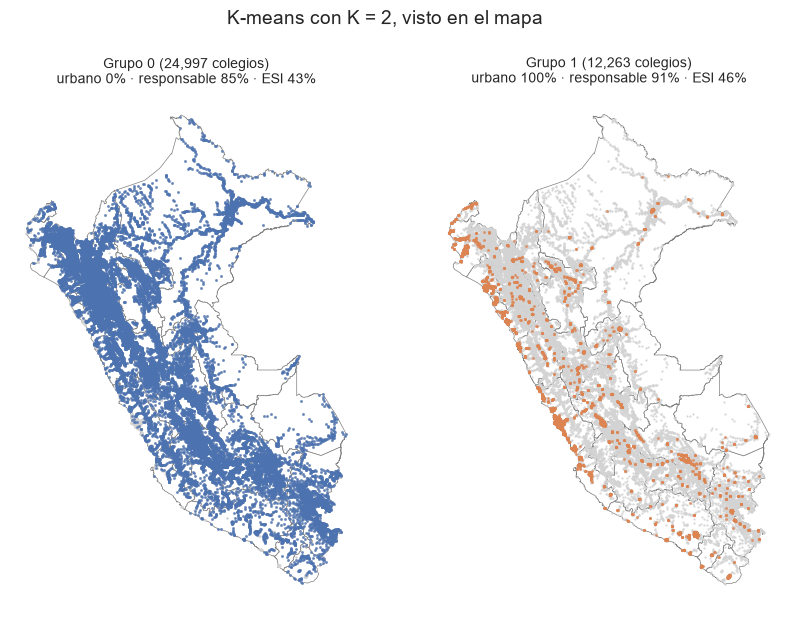

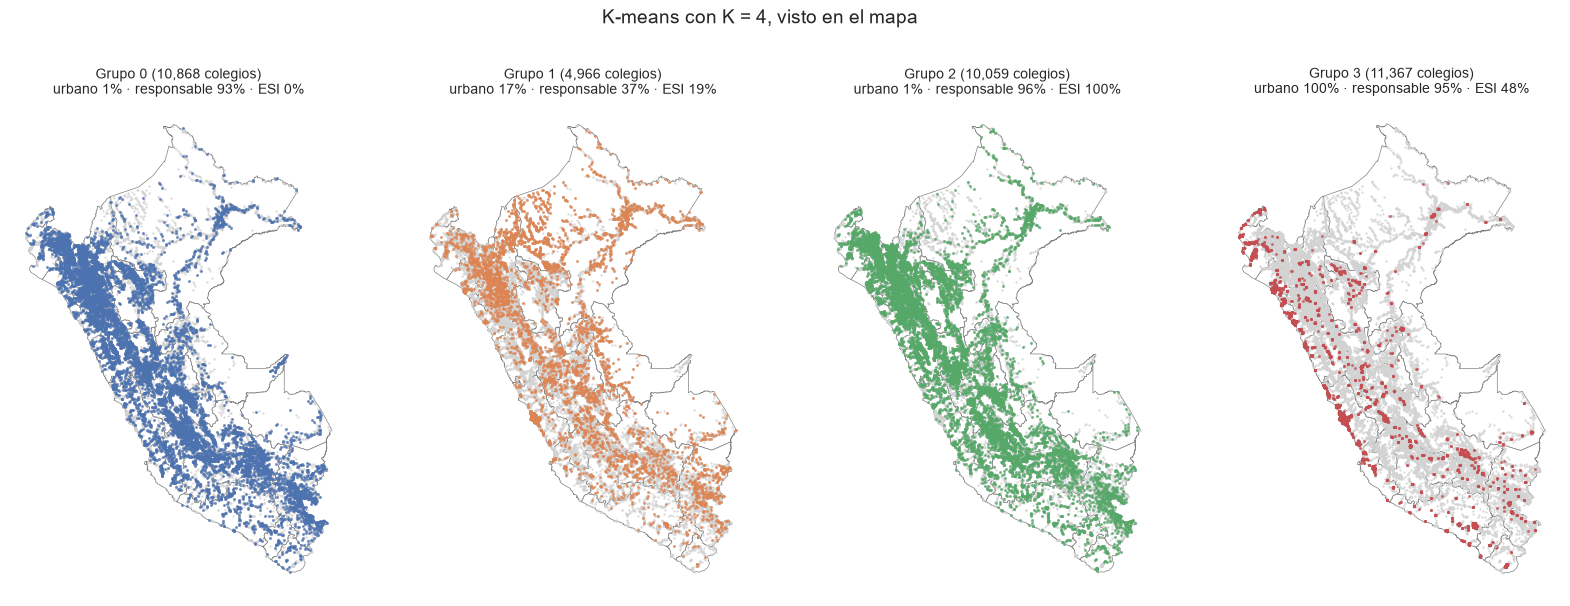

In [117]:
# ¿Siguen formando regiones? Un mapa por grupo, como en 12.1
for k in [2, 4]:
    colegios_gdf[f"kmeans_k{k}"] = datos_km[f"kmeans_k{k}"]          # mismo índice que la matriz
    perfil_k = datos_km.groupby(f"kmeans_k{k}")[["urbano", "resp_convivencia", "actividad_esi"]].mean()

    fig, axes = plt.subplots(1, k, figsize=(5 * k, 7))
    for ax, (grupo, fila) in zip(axes, perfil_k.iterrows()):
        regiones.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.5)
        colegios_gdf.plot(ax=ax, color="lightgray", markersize=0.3)
        capa = colegios_gdf[colegios_gdf[f"kmeans_k{k}"] == grupo]
        capa.plot(ax=ax, color=f"C{grupo}", markersize=1.5, alpha=0.6)
        ax.set_title(f"Grupo {grupo} ({len(capa):,} colegios)\n"
                     f"urbano {fila['urbano']:.0%} · responsable {fila['resp_convivencia']:.0%} · "
                     f"ESI {fila['actividad_esi']:.0%}", fontsize=10)
        ax.set_axis_off()
    fig.suptitle(f"K-means con K = {k}, visto en el mapa", fontsize=14)
    plt.show()

**Lectura**

*   **K = 2 (un grupo menos):** *Pocos instrumentos* desaparece. El 85 % de sus colegios (4,289 de 5,075) se junta con
    *Rural con instrumentos* y los otros 786, urbanos, pasan a *Urbano grande*. El mapa queda dividido solo entre
    ciudades y campo. K = 2 es estable (10.6), pero esconde justo el grupo que interesa a la UGEL.
*   **K = 4 (un grupo más):** *Pocos instrumentos* y *Urbano grande* casi no cambian (conservan 4,965 y 11,359 de sus
    colegios). Lo que se parte es *Rural con instrumentos*, en dos mitades que solo se diferencian por las actividades
    de ESI con familias (0 % frente a 100 %).
*   **¿Siguen formando regiones?** Sí: con K = 3 y con K = 4, el grupo de pocos instrumentos sigue los ríos de la
    Amazonía y el urbano está en la costa y las ciudades. Las dos mitades rurales de K = 4, en cambio, se reparten por
    toda la sierra: no forman regiones distintas.
*   Los perfiles útiles para priorizar no dependen de elegir exactamente K = 3, pero sí de no usar menos grupos.

#### B. DBSCAN espacial con `min_samples` = 15 y 60

Se deja `eps = 30 km` (12.2) y solo cambia `min_samples`: cuántos colegios sin libro se exigen a menos de 30 km para
formar una zona. Además del ruido total, se mide:

* el ruido en la Amazonía (Loreto, Ucayali y Madre de Dios), la limitación que se encontró en 12.2;
* **la distancia de cada colegio al centro de su zona** (mediana, en km): si es grande, una sola visita o
  capacitación no llega a todos los colegios de la zona.

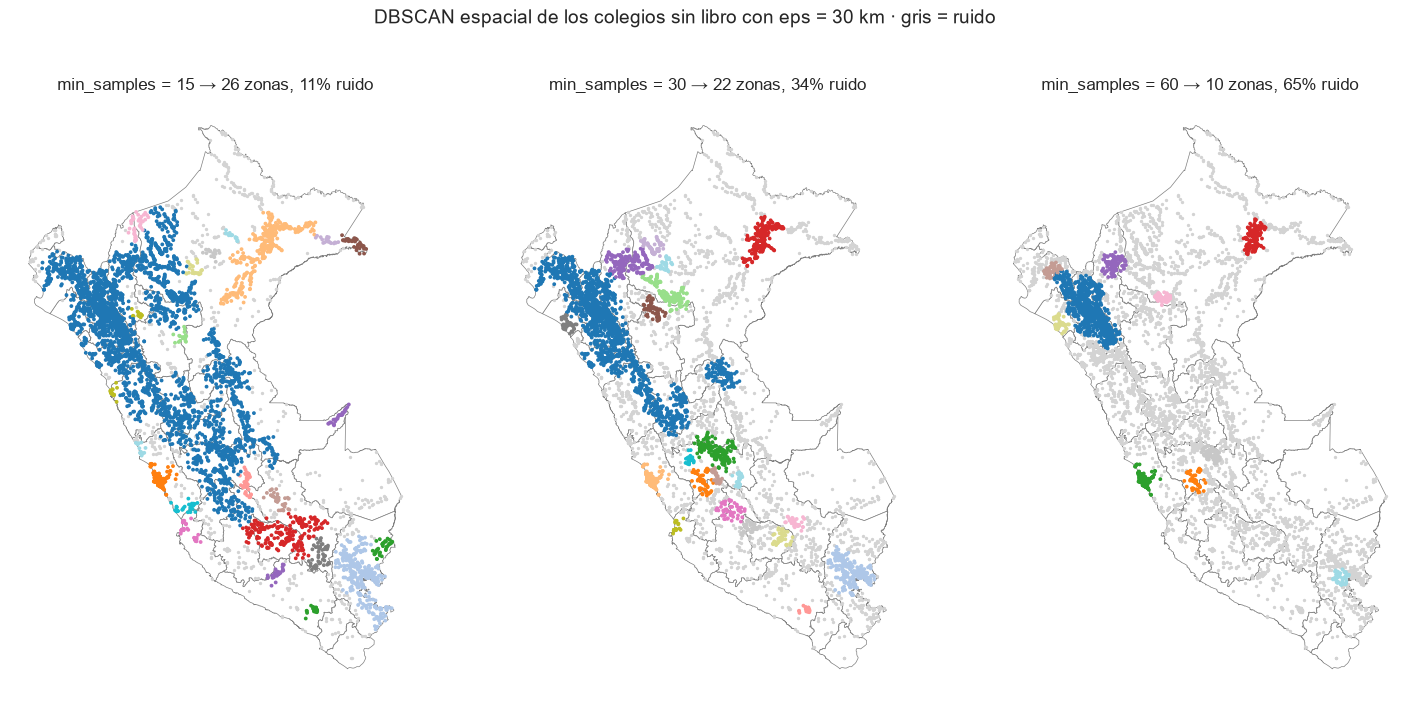

,min_samples,zonas,ruido,% ruido,% ruido en la Amazonía,zona_mas_grande,"distancia al centro (km, mediana)"
0,15,26,662,11,18,3236,154
1,30,22,2106,34,56,1689,45
2,60,10,4050,65,84,846,26


In [118]:
def distancia_al_centro_km(etiquetas):
    """Mediana de la distancia (km) de cada colegio al centro de su grupo; el ruido no cuenta."""
    distancias = []
    for grupo in set(etiquetas) - {-1}:
        puntos = coords_m[etiquetas == grupo]
        distancias.extend(np.linalg.norm(puntos - puntos.mean(axis=0), axis=1) / 1000)
    return round(np.median(distancias))

filas = []
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, ms in zip(axes, [15, 30, 60]):
    etiquetas = DBSCAN(eps=30_000, min_samples=ms).fit_predict(coords_m)
    es_ruido = etiquetas == -1
    tamanos = pd.Series(etiquetas[~es_ruido]).value_counts()
    filas.append({"min_samples": ms,
                  "zonas": len(tamanos),
                  "ruido": es_ruido.sum(),
                  "% ruido": round(es_ruido.mean() * 100),
                  "% ruido en la Amazonía": round(es_ruido[es_amazonia.to_numpy()].mean() * 100),
                  "zona_mas_grande": tamanos.max(),
                  "distancia al centro (km, mediana)": distancia_al_centro_km(etiquetas)})

    regiones_m.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.5)
    ax.scatter(coords_m[es_ruido, 0], coords_m[es_ruido, 1], s=2, color="lightgray")      # gris = ruido
    ax.scatter(coords_m[~es_ruido, 0], coords_m[~es_ruido, 1], s=3, c=etiquetas[~es_ruido], cmap="tab20")
    ax.set_title(f"min_samples = {ms} → {len(tamanos)} zonas, {es_ruido.mean():.0%} ruido")
    ax.set_axis_off()

fig.suptitle("DBSCAN espacial de los colegios sin libro con eps = 30 km · gris = ruido", fontsize=14)
plt.savefig(SALIDAS / "fig_dbscan_min_samples.png", dpi=200, bbox_inches="tight")
plt.show()
display(pd.DataFrame(filas))

**Lectura**

*   **`min_samples = 15`:** se exige menos densidad, así que más colegios forman zona: el ruido baja al 11 % y en la
    Amazonía al 18 %. Pero las zonas vecinas se encadenan: la de la sierra norte crece de 1,689 a 3,236 colegios y baja
    por la sierra hasta el centro del país; la mitad de los colegios queda a más de 154 km del centro de su zona.
*   **`min_samples = 60`:** solo quedan los núcleos más densos (10 zonas, como Cajamarca, Maynas y Lima); el 65 % es
    ruido y en la Amazonía, el 84 %.
*   **¿Por qué?** `min_samples` es la densidad mínima para formar una zona. Con un valor bajo casi cualquier colegio
    tiene suficientes vecinos y las zonas se unen; con uno alto solo cuentan los lugares con muchos colegios juntos.
    Los colegios amazónicos, dispersos a lo largo de los ríos, son los primeros en quedar como ruido.
*   Se mantiene **`min_samples = 30`**: queda entre zonas demasiado grandes para una visita y un mapa casi todo ruido.
    El ruido amazónico se puede reducir, pero no sin unir zonas lejanas.

#### B (adicional). K-means y jerárquico con la ubicación

En el laboratorio, con las coordenadas gana DBSCAN. Se repite con nuestros datos: los mismos 6,269 colegios sin libro
y las mismas coordenadas en metros. K-means y el jerárquico (Ward) necesitan el número de grupos: primero 22 (las zonas
de DBSCAN) y luego 4, como pide el desafío.

Primero, el dendrograma: ¿dónde cortar el árbol? Cada rama lleva el departamento más frecuente y cuántos colegios tiene.

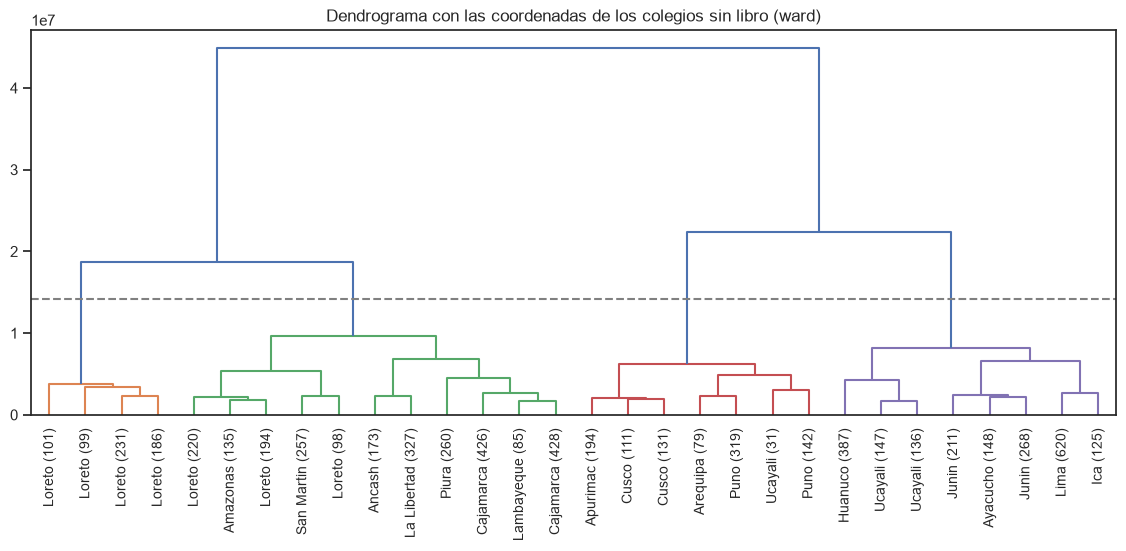

Grupos con ese corte: 4


In [119]:
from scipy.cluster.hierarchy import to_tree

# Árbol con las coordenadas en metros (ward = mismo método que AgglomerativeClustering)
Z_coords = linkage(coords_m, method="ward")

# Etiqueta de cada rama: departamento más frecuente y cuántos colegios tiene
_, nodos = to_tree(Z_coords, rd=True)

def etiqueta_rama(id_nodo):
    miembros = nodos[id_nodo].pre_order()                                # colegios de esa rama
    departamento = sin_libro_m["D_DPTO"].iloc[miembros].value_counts().index[0]
    return f"{departamento.title()} ({len(miembros)})"

# Línea entre la 4.ª y la 3.ª unión más altas: deja 4 ramas
corte_4 = (Z_coords[-4, 2] + Z_coords[-3, 2]) / 2

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z_coords, truncate_mode="lastp", p=30, color_threshold=corte_4,
           leaf_label_func=etiqueta_rama, leaf_rotation=90, ax=ax)
ax.axhline(corte_4, color="gray", linestyle="--")
ax.set_title("Dendrograma con las coordenadas de los colegios sin libro (ward)")
plt.show()
print("Grupos con ese corte:", len(set(fcluster(Z_coords, t=corte_4, criterion="distance"))))

**Lectura.** El salto más grande separa **2 ramas**: el norte (Loreto, Amazonas, San Martín, Cajamarca, Piura, La
Libertad) y el centro-sur. La línea punteada deja **4**: Loreto, el norte andino, el sur (Apurímac, Cusco, Arequipa,
Puno) y el centro (Huánuco, Junín, Ayacucho, Lima, Ica). Son macrorregiones, no zonas de trabajo. El árbol no muestra
un salto especial en 22 grupos: ese número se usa solo para comparar con DBSCAN, como en el laboratorio.

Ahora los tres algoritmos sobre las mismas coordenadas, con las mismas medidas que en B (ruido y distancia al
centro del grupo).

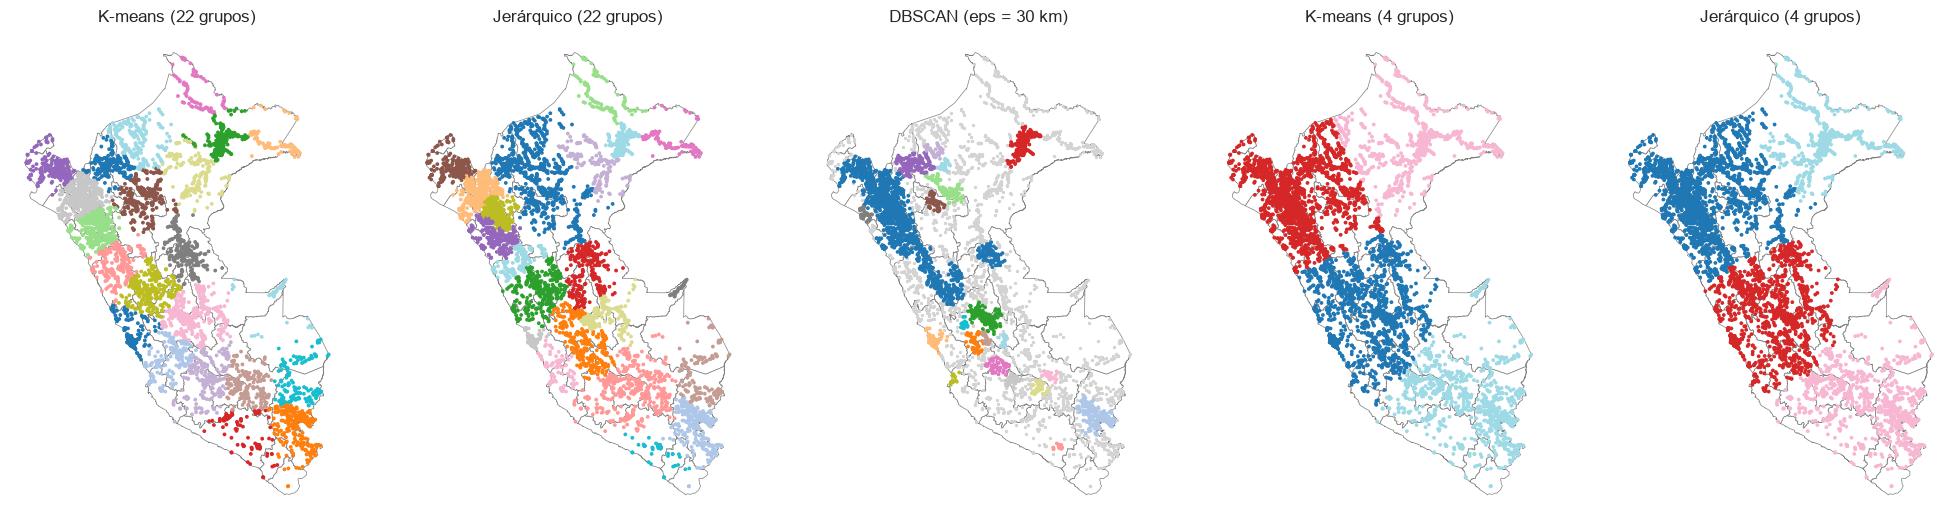

,método,grupos,% ruido,% ruido en la Amazonía,grupo más grande,"distancia al centro (km, mediana)"
0,K-means (22 grupos),22,0,0,686,68
1,Jerárquico (22 grupos),22,0,0,620,69
2,DBSCAN (eps = 30 km),22,34,56,1689,45
3,K-means (4 grupos),4,0,0,2370,174
4,Jerárquico (4 grupos),4,0,0,2603,173


In [120]:
from sklearn.cluster import AgglomerativeClustering

modelos_coords = {
    "K-means (22 grupos)": KMeans(n_clusters=22, n_init=10, random_state=42),
    "Jerárquico (22 grupos)": AgglomerativeClustering(n_clusters=22, linkage="ward"),
    "DBSCAN (eps = 30 km)": DBSCAN(eps=30_000, min_samples=MIN_COLEGIOS),
    "K-means (4 grupos)": KMeans(n_clusters=4, n_init=10, random_state=42),
    "Jerárquico (4 grupos)": AgglomerativeClustering(n_clusters=4, linkage="ward"),
}

filas = []
fig, axes = plt.subplots(1, 5, figsize=(25, 8))
for ax, (nombre, modelo) in zip(axes, modelos_coords.items()):
    etiquetas = modelo.fit_predict(coords_m)
    es_ruido = etiquetas == -1          # solo DBSCAN produce -1
    filas.append({"método": nombre,
                  "grupos": len(set(etiquetas[~es_ruido])),
                  "% ruido": round(es_ruido.mean() * 100),
                  "% ruido en la Amazonía": round(es_ruido[es_amazonia.to_numpy()].mean() * 100),
                  "grupo más grande": np.bincount(etiquetas[~es_ruido]).max(),
                  "distancia al centro (km, mediana)": distancia_al_centro_km(etiquetas)})

    regiones_m.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.5)
    ax.scatter(coords_m[es_ruido, 0], coords_m[es_ruido, 1], s=2, color="lightgray")
    ax.scatter(coords_m[~es_ruido, 0], coords_m[~es_ruido, 1], s=3, c=etiquetas[~es_ruido], cmap="tab20")
    ax.set_title(nombre)
    ax.set_axis_off()

plt.show()
comparacion_coords = pd.DataFrame(filas)
display(comparacion_coords)

**Lectura.** Como en el laboratorio, **con la ubicación gana DBSCAN**:

*   K-means y el jerárquico reparten a **todos** los colegios sin libro, incluidos los aislados de la Amazonía: no dejan
    ruido, pero cortan el país en territorios. Con 22 grupos, la mitad de los colegios queda a más de 68–69 km del
    centro de su grupo, frente a 45 km en las zonas de DBSCAN.
*   Con 4 grupos (lo que pide el desafío) **no mejoran**: son macrorregiones con la mitad de los colegios a más de
    170 km del centro. Sirven para repartir el trabajo entre equipos, no para planear una visita.
*   DBSCAN solo forma zonas donde de verdad hay muchos colegios sin libro juntos, con la forma que tengan (la de la
    sierra norte es una franja larga). Su costo es el ruido amazónico (56 %).
*   K-means con 22 grupos tendría un uso: si la UGEL quisiera asignar **todos** los colegios, incluidos los aislados,
    a territorios de trabajo, no deja a ninguno fuera.

**Respuesta al desafío (resumen)**

| Parte | Pregunta | Respuesta con nuestros datos |
|---|---|---|
| A | ¿Qué grupos se fusionan con un K menor? | Con K = 2, *Pocos instrumentos* se funde con el grupo rural y el mapa queda en ciudad frente a campo. Con K = 4 ese grupo se mantiene y se parte el rural (según las actividades de ESI) |
| A | ¿Siguen formando regiones? | Sí: el grupo urbano en la costa y las ciudades, el de pocos instrumentos en los ríos amazónicos. Las dos mitades rurales de K = 4 se mezclan en la sierra |
| B | `min_samples` = 15 y 60: ¿cuántas zonas y cuánto ruido? ¿Por qué? | 15: 26 zonas y 11 % de ruido, pero una zona de 3,236 colegios. 60: 10 zonas y 65 % de ruido. `min_samples` es la densidad mínima que se exige |
| B | Con 4 grupos, ¿mejoran K-means y el jerárquico? | No: forman macrorregiones (mitad de los colegios a más de 170 km del centro). Con la ubicación conviene DBSCAN |
| C | ¿Qué enfoque usaría el proyecto? | Ver 12.5 |

### <font color=skyblue> 12.5 ¿Qué enfoque conviene para el proyecto? </font>

| Enfoque | ¿Lo usamos? | Por qué |
|---|---|---|
| Clustering por atributos y luego mapa | **Sí, es el principal** | Responde la pregunta del proyecto (qué colegios tienen poca capacidad de registro) y el mapa muestra dónde están |
| Clustering espacial (DBSCAN) | Sí, como apoyo | Encuentra zonas con muchos colegios sin libro juntos, útil para planear capacitaciones; pero deja como ruido a los colegios dispersos de la Amazonía |
| Mapa de calor | Solo para presentar | Muestra la concentración de forma intuitiva, pero no forma grupos y pinta zonas sin colegios |
| K-means o jerárquico con la ubicación | No | Reparten a todos los colegios en territorios grandes (12.4); no encuentran dónde se juntan muchos colegios sin libro |

Esta tabla responde la parte C del desafío del laboratorio S12.

### <font color=skyblue> 12.6 Lectura preliminar </font>

1. Los grupos de K-means, formados sin la ubicación, forman regiones: el grupo *Pocos instrumentos* está sobre todo en
   la Amazonía.
2. DBSCAN (`eps = 30 km`, `min_samples = 30`) encuentra 22 zonas con muchos colegios sin libro; las mayores están en la
   sierra norte, Lima, Maynas (Iquitos) y Azángaro (Puno).
3. Muchos colegios sin libro juntos no es lo mismo que una proporción alta: Lima tiene muchos por su tamaño, y en la
   Amazonía los colegios están tan dispersos que DBSCAN deja como ruido al 56 %.
4. Por ahora, el enfoque principal es el clustering por atributos y luego el mapa; DBSCAN sirve para la
   logística de la UGEL y el mapa de calor para comunicar.
5. El desafío del laboratorio (12.4) muestra que los resultados no dependen de un solo parámetro: con K = 4 el grupo
   *Pocos instrumentos* se mantiene (con K = 2 desaparece), y en DBSCAN `min_samples` cambia sobre todo cuánto de
   la Amazonía queda como ruido (de 18 % a 84 %).

### <font color=skyblue> 12.7 Mapa interactivo para la UGEL (Folium) </font>

Los mapas de las secciones 11 y 12 son imágenes fijas. A la UGEL le sirve más un mapa en el que pueda acercarse, hacer
clic en un colegio y prender o apagar capas. Se aplica la plantilla del laboratorio de Folium (S13) a nuestros datos,
con sus dos casos:

| Capa | Caso de la plantilla | Qué muestra |
|---|---|---|
| 1. % sin libro por departamento | B: la tabla tiene departamento (se une por `ADM1_PCODE`, no por nombre) | Dónde es más **común** no tener libro |
| 2. Mapa de calor (apagada al inicio) | A: la tabla tiene latitud y longitud | Dónde hay **muchos** colegios sin libro juntos |
| 3. Colegios sin ninguno de los 3 instrumentos | A: la tabla tiene latitud y longitud | Los colegios para empezar (sección 13). Al hacer clic: nombre, código modular, matrícula, si tiene libro y su zona DBSCAN (12.2) |

Folium dibuja en grados (EPSG:4326), como `colegios_gdf`. El mapa se guarda en `salidas/mapa_ugel_sin_libro.html`, que
se abre en cualquier navegador sin Python y se puede adjuntar al informe.

In [121]:
import folium
from folium.plugins import HeatMap

# Mapa de fondo de Esri: OpenStreetMap bloquea sus mapas en Colab (laboratorio S13).
# Gris neutro para que resalten los datos.
MAPA_BASE = "Esri.WorldGrayCanvas"

# --- Capa 1 (caso B): % de colegios sin libro por departamento (tabla de 11.2) ---
dpto_web = mapa_dpto[["ADM1_ES", "colegios", "pct_sin_libro", "pct_registra", "geometry"]].copy()
dpto_web[["pct_sin_libro", "pct_registra"]] = dpto_web[["pct_sin_libro", "pct_registra"]].round(1)
# Bordes simplificados con tolerancia de 1 km (en metros) para que el mapa cargue rápido
dpto_web["geometry"] = dpto_web.to_crs("EPSG:32718").simplify(1000).to_crs("EPSG:4326")

mapa_ugel = dpto_web.explore(
    column="pct_sin_libro", cmap="OrRd", legend=True,
    legend_kwds={"caption": "% de colegios sin libro de incidencias"},
    tooltip=["ADM1_ES", "colegios", "pct_sin_libro", "pct_registra"],
    tooltip_kwds={"aliases": ["Departamento", "Colegios", "% sin libro", "% que registra"]},
    style_kwds={"color": "gray", "weight": 0.5, "fillOpacity": 0.5},
    tiles=MAPA_BASE, name="% sin libro por departamento",
)

# --- Capa 2 (caso A): mapa de calor de los colegios sin libro -----------------
capa_calor = folium.FeatureGroup(name="Mapa de calor: colegios sin libro", show=False)   # empieza apagada
puntos_sin_libro = colegios_gdf.loc[colegios_gdf["sin_libro"], ["NLAT_IE", "NLONG_IE"]].values.tolist()
HeatMap(puntos_sin_libro, radius=8, blur=10).add_to(capa_calor)
capa_calor.add_to(mapa_ugel)

# --- Capa 3 (caso A): colegios sin responsable, sin protocolos y sin reporte a la UGEL ---
prioridad = base_final[base_final["indice_convivencia"] == 0].copy()
prioridad["zona"] = sin_libro_m["zona"]        # zona DBSCAN de 12.2 (solo la tienen los colegios sin libro)
nombre_zona = resumen_zonas["provincia_principal"].str.title()

def texto_zona(zona):
    if pd.isna(zona):
        return "—"
    return "aislado (ruido)" if zona == -1 else f"zona de {nombre_zona[int(zona)]}"

capa_prioridad = folium.FeatureGroup(name="Colegios sin ninguno de los 3 instrumentos")
for _, fila in prioridad.iterrows():
    sin_libro = fila["P125B"] == "NO"
    texto = (f"<b>{fila['CEN_EDU_censo']}</b><br>"
             f"Código modular: {fila['COD_MOD']}<br>"
             f"{fila['D_DIST'].title()}, {fila['D_PROV'].title()} ({fila['D_DPTO'].title()})<br>"
             f"Matrícula: {fila['mat_total']:.0f} estudiantes<br>"
             f"Libro de incidencias: {'no' if sin_libro else 'sí'}<br>"
             f"Zona DBSCAN: {texto_zona(fila['zona'])}")
    folium.CircleMarker(
        location=[fila["NLAT_IE"], fila["NLONG_IE"]],
        radius=4, weight=1, fill=True, fill_opacity=0.8,
        color="darkred" if sin_libro else "darkorange",    # rojo = además no tiene libro
        popup=folium.Popup(texto, max_width=280),
    ).add_to(capa_prioridad)
capa_prioridad.add_to(mapa_ugel)

folium.LayerControl(collapsed=False).add_to(mapa_ugel)   # selector de capas, siempre al final
mapa_ugel.save(str(SALIDAS / "mapa_ugel_sin_libro.html"))

print("Colegios sin ninguno de los 3 instrumentos:", len(prioridad))
print("  sin libro (rojo):", (prioridad["P125B"] == "NO").sum(),
      "| dentro de una zona DBSCAN:", (prioridad["zona"] >= 0).sum())
print("Mapa guardado:", SALIDAS / "mapa_ugel_sin_libro.html")
display(prioridad["D_DPTO"].str.title().value_counts().head(5).rename("colegios sin los 3 instrumentos"))
mapa_ugel

Colegios sin ninguno de los 3 instrumentos: 1112
  sin libro (rojo): 949 | dentro de una zona DBSCAN: 630
Mapa guardado: salidas\mapa_ugel_sin_libro.html


D_DPTO
Loreto       351
Lima         120
Ucayali       84
Cajamarca     74
Puno          68
Name: colegios sin los 3 instrumentos, dtype: int64

**Lectura**

*   **Los colegios para empezar están sobre todo en la Amazonía:** de los 1,112 colegios sin responsable de
    convivencia, sin protocolos y sin reporte a la UGEL, 351 están en Loreto (uno de cada tres), y 949 (85 %) tampoco
    tienen libro (puntos rojos).
*   **Con las zonas de DBSCAN se puede planear la visita:** 630 de esos 949 colegios sin libro están dentro de una zona
    con muchos colegios sin libro, donde una sola capacitación llega a varios; los otros 319 están aislados y hay que
    atenderlos uno por uno.
*   **Limitación:** el color de cada departamento es un promedio que esconde diferencias grandes entre provincias. Loreto
    tiene 51 % de colegios sin libro, pero en Datem del Marañón son el 85 % (12.2); para decidir dónde ir hay que hacer
    clic en los puntos, no quedarse con el color del departamento.

## <font color=yellow> 13. Problemas y trabajo pendiente </font>

**Problemas encontrados**

| Problema | Efecto | Qué se hizo |
|---|---|---|
| 8 de los 9 atributos son sí/no | Muchos colegios idénticos; DBSCAN forma "islas" y depende mucho de `eps` | Se reporta y DBSCAN queda como comparación (10.9) |
| El z-score agranda los "no" poco frecuentes | No tener un instrumento pesa más en la distancia | Se aceptó porque es lo que interesa al problema (8.4); se mostró el efecto de no escalar (10.11) |
| Silueta débil (cerca de 0.29) | Hay colegios intermedios entre grupos | Los grupos se usan para priorizar, no para clasificar |
| El jerárquico no cabe en memoria | Solo se puede con una muestra de 10,000 colegios | Se reporta el árbol sin asignar y la asignación por centroides (10.10) |
| El tamaño influye en registrar | Comparar los grupos sin más puede engañar | Se comparan a igual tamaño (10.8) |
| Casi todos los colegios sin libro no tienen dato de registro | Los porcentajes de registro salen de menos colegios | Se muestra la base de cada porcentaje (10.8) |
| Colegios dispersos en la Amazonía | DBSCAN espacial deja como ruido al 56 % | Se complementa con el mapa de proporciones (sección 12). Con `min_samples = 15` baja al 18 %, pero la zona mayor casi se duplica (12.4) |

**Decisiones todavía abiertas**

*   ¿Quedarse con K = 3 o buscar más detalle? K = 5 y K = 6 son inestables hoy, y K = 4 solo parte al grupo rural según las actividades de ESI (12.4).
*   ¿Probar una distancia pensada para atributos sí/no (por ejemplo, Gower) en el jerárquico? Con z-score y distancia
    euclidiana, los resultados dependen de cómo se trata cada "no".

**Qué falta antes del Hito 4**

1.  **Reglas de asociación (Apriori).** Ver qué instrumentos de convivencia (responsable, protocolos, SíseVe, plan
    TOECE, normas) suelen estar presentes, o faltar, juntos.
2.  **Lista priorizada para la UGEL.** Colegios del grupo *Pocos instrumentos* o sin libro, con su departamento,
    provincia y zona DBSCAN (sección 12) cuando la tengan. Empezar por los 1,112 colegios sin responsable, sin protocolos
    y sin reporte a la UGEL (grupo 5 de DBSCAN, 10.9). El mapa de 12.7 ya los ubica; falta entregarlos como tabla.
3.  **Describir los perfiles con los factores NMF** (sección 9) para explicarlos con menos variables.
4.  **Relación con la repetición y el retiro por grupo.** El clustering todavía no responde esta parte de la pregunta.
5.  **Pruebas de sensibilidad:** el umbral de 10 estudiantes en las tasas, los colegios con matrícula imputada
    (`matricula_imputada`) y el desfase entre incidencias de 2024 y matrícula de 2025.
6.  **Comparación final, discusión y conclusiones** que respondan la pregunta del proyecto.

## <font color=yellow> 14. Hallazgos preliminares y limitaciones </font>

Son resultados de avance, no conclusiones definitivas: las conclusiones y recomendaciones se cierran en el Hito 4.

**Lo que muestran los datos hasta ahora**

1.  **El cero es la situación más común, pero no siempre significa lo mismo.** El 71.5 % de los colegios tiene libro y
    anotó cero incidencias en 2024, el 16.8 % no tiene libro y solo el 11.7 % registra al menos una incidencia.

2.  **Los colegios sin libro se concentran en la Amazonía.** En Loreto la mitad de los colegios (51 %) no tiene libro y
    en Ucayali el 38 %; en Tacna, el 3 %. Ahí un cero dice muy poco sobre la violencia.

3.  **La falta de libro va junto con la falta de otros instrumentos de convivencia.** Entre los colegios sin ninguno de
    los tres instrumentos, el 85 % tampoco tiene libro; entre los que tienen los tres, el 9 %. El porcentaje que
    registra sube de menos del 1 % a 14 %.

4.  **En las zonas rurales, los colegios sin libro tienen más repetición alta** (24 % frente a 17 %). En las urbanas
    las diferencias son pequeñas (entre 4 % y 8 %).

5.  **PCA y NMF resumen el perfil del colegio en dos bloques: contexto e instrumentos de convivencia.** Sin usar el
    dato de violencia, el registro sube con los instrumentos dentro de cada contexto (de 6.5% a 11% en los públicos
    rurales) y el contexto marca el nivel. Los colegios con menos instrumentos son, en gran parte, colegios sin libro
    (44% en el tercio bajo de los públicos rurales).

6.  **K-means encuentra tres perfiles de colegio** (sección 10): urbano grande, rural con instrumentos y pocos
    instrumentos. El 59 % de los colegios de *Pocos instrumentos* (5,075) no tiene libro, aunque el libro no entró al
    modelo, y los que tienen dato registran menos que el grupo rural en todos los tamaños. K = 3 es el más estable entre
    las opciones con mejor métrica, y el jerárquico da grupos parecidos (90 % de coincidencia; ARI 0.76). Con K = 4 el grupo
    *Pocos instrumentos* se mantiene casi igual; con K = 2 desaparece dentro del grupo rural (12.4).

7.  **En el mapa, registrar y no poder registrar ocupan lugares distintos** (sección 11). Los colegios que registran
    están en la costa y las ciudades; los sin libro siguen los ríos amazónicos, la sierra norte y Puno. Los tres
    departamentos con menos colegios por km² (Madre de Dios, Loreto y Ucayali) son los de mayor % sin libro.

8.  **DBSCAN encuentra 22 zonas con muchos colegios sin libro juntos** (sección 12), útiles para planear
    capacitaciones; la mayor está en la sierra norte. Pero en la Amazonía el 56 % de los colegios sin libro queda
    como ruido por estar dispersos: ahí el mapa de proporciones (Mapa 3) dice más que el clustering espacial. Bajar
    `min_samples` a 15 reduce ese ruido al 18 %, pero une zonas lejanas en una de 3,236 colegios (12.4).

**Decisiones principales sobre los datos**

9.  El cambio de la base de denuncias del SíseVe por fuentes con código modular fue la
    decisión metodológica central del trabajo. Permitió pasar de un análisis a nivel UGEL
    disfrazado de análisis a nivel colegio, a una integración 1 a 1 real entre las cuatro
    fuentes, sin duplicación de llaves.

10.  El tratamiento de las preguntas condicionadas (`P124B_SI`, `P126B_SI_1`, `P126B`, `P116A`, `P105B`, `P106B` y
    `P122B`) resultó ser determinante. Distinguir entre "respondió cero", "no corresponde responder" y "no
    respondió" cambia por completo la magnitud de los indicadores de violencia.

11.  **La forma de medir importó tanto como la limpieza.** Con incidencias y tasas concentradas en cero, los promedios
    engañan: unos pocos colegios con valores altos los arrastran. Por eso el EDA cuenta colegios (qué porcentaje está
    en cada situación) en lugar de promediar tasas.

12.  Tres decisiones de diseño evitaron sesgos: la matrícula se une por separado para que ningún
    colegio pierda su denominador; el índice de gestión, el PCA y el NMF excluyen el libro de incidencias para no
    ser circulares; y los colegios sin libro se identificaron como grupo propio en lugar de imputarse.

13. **Las transformaciones se aplicaron solo donde servían.** El logaritmo corrigió la asimetría de la matrícula
    (de 3.6 a 0.1), pero no la de las tasas, cuyo problema es la masa de ceros; por eso la incidencia se
    discretizó (`registra_incidencia`) en lugar de escalarse. Min-max, el escalador robusto, los cuantiles y el
    one-hot del departamento se probaron y se descartaron con evidencia (sección 7.5). La escala común se aplica
    dentro de cada técnica en lugar de guardarse en la matriz.

14. La base integrada se transformó en una matriz analítica de 37,354 colegios y 26 columnas (sección 8), con
    diccionario de variables y exclusiones documentadas. La selección de atributos (8.3) y la comparación de
    distancias (8.4) dejan justificada la representación que usará el clustering.

**Limitaciones**

15. Ambos indicadores de violencia son **autodeclarados por el director** y están mediados
    por la capacidad de registro del colegio, por lo que miden violencia *registrada*, no
    violencia *ocurrida*. Esta es la limitación de fondo del trabajo.
16. El 16% de los colegios no tiene dato de incidencias, pero casi todos (5,851 de 5,875) son colegios
    **sin libro**: no es falta de respuesta. En total, 6,269 colegios no tienen libro. Se concentran en colegios
    pequeños, rurales y de la Amazonía. Las comparaciones de registro se calculan con los colegios que tienen libro
    y los sin libro se muestran aparte (secciones 6 y 9).
17. El motivo de retiro por violencia, que sería la medida más directa, resultó
    inutilizable: solo 6 estudiantes en 5 colegios de todo el país.
18. Parte de los datos de matrícula fueron imputados por el MINEDU (variable `IMPUTADO`, 3.3% de los
    colegios) y no declarados directamente por el colegio.
19. El análisis es transversal. Las incidencias del libro corresponden a 2024, los casos del SíseVe llegan
    hasta la fecha del Censo 2025 y la repetición y la matrícula son de 2025, así que no es un panel ni permite
    afirmar causalidad en ninguna dirección; además, la matrícula de 2025 se usa como denominador de incidencias
    de 2024.
20. La silueta de los tres métodos de clustering es débil (cerca de 0.29): los grupos sirven para priorizar, pero hay
    colegios intermedios entre perfiles. La silueta y el jerárquico se calcularon con muestras de 10,000 colegios.